In [29]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d

In [30]:
#========== FUNCTIONS TO PRINT SCORES ==========#

def load_txt_file(rootpath, model_name):
    txt_path = os.path.join(rootpath, model_name, "scores.txt")
    if not os.path.exists(txt_path):
        raise FileNotFoundError(f"File not found: {txt_path}")

    scores = []
    labels = []
    with open(txt_path, 'r') as fh:
        for line in fh:
            parts = line.strip().split()
            if len(parts) != 3:
                continue  # skip malformed lines

            _, score, label = parts
            score = score.strip("[]")
            scores.append(float(score))
            labels.append(int(label))

    scores = np.array(scores)
    labels = np.array(labels)
    return scores, labels

def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    #eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]

    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")
    
def plot_scores_distribution(scores, labels):
    # Split real/fake
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    print(f"Loaded {len(scores)} samples")
    print(f"Real mean score: {real_scores.mean():.4f}")
    print(f"Fake mean score: {fake_scores.mean():.4f}\n")

    # Plot
    plt.figure(figsize=(6, 4))
    plt.hist(real_scores, bins=100, alpha=0.5, density=True)
    plt.hist(fake_scores, bins=100, alpha=0.5, density=True)
    plt.xlabel("Score")
    plt.ylabel("Density")
    plt.title(f"Score Distribution")
    plt.legend(["Real (0)", "Fake (1)"])
    plt.show()

def plot_expert_stats(rootpath,
                      model_name,
                      stat="gating",
                      expert_labels=None):

    base_path = os.path.join(rootpath, model_name)

    global_path = os.path.join(base_path, f"{stat}_mean_global.npy")
    real_path   = os.path.join(base_path, f"{stat}_mean_real.npy")
    spoof_path  = os.path.join(base_path, f"{stat}_mean_fake.npy")

    global_w = np.load(global_path).flatten()
    real_w   = np.load(real_path).flatten()
    spoof_w  = np.load(spoof_path).flatten()

    if expert_labels is not None:
        n_experts = len(expert_labels)
        if len(global_w) != n_experts:
            raise ValueError(
                f"Mismatch: loaded stats have {len(global_w)} experts "
                f"but expert_labels has {n_experts}")
    else:
        n_experts = len(global_w)
        expert_labels = [f"E{i}" for i in range(n_experts)]

    fig, axes = plt.subplots(1, 3, figsize=(4*n_experts/2 + 6, 4), sharey=True)

    if stat == "gating":
        fig.suptitle("Gating Weights")
    elif stat == "weighted":
        fig.suptitle("Gating × Expert Logits")
    else:
        fig.suptitle("Expert Logits")

    titles = ["Avg global", "Avg real", "Avg fake"]
    data   = [global_w, real_w, spoof_w]
    colors = ["blue", "pink", "green"]

    for ax, weights, title, color in zip(axes, data, titles, colors):
        ax.bar(range(n_experts), weights, color=color)
        ax.set_title(title)
        ax.set_xticks(range(n_experts))
        ax.set_xticklabels(expert_labels, rotation=45)
        #if stat == 'gating':
        #   ax.set_ylim(0, 1)
        ax.grid(True)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Value")

    plt.tight_layout()
    plt.show()

    return data


In [3]:
def compute_res_and_plot(rootpath, model_name, expert_labels, distr=False, plot=True):
    scores, labels = load_txt_file(rootpath, model_name)
    
    print("\nIndividual Experts' Performance:")
    experts_scores = np.load(os.path.join(rootpath, model_name, "expert_all.npy"))
    for i in range(experts_scores.shape[1]):
        print_metrics(experts_scores[:, i], labels)    
    print("\nMoE Performance:")
    print_metrics(scores, labels)

    if distr:
        plot_scores_distribution(scores, labels)
        
    if plot:
        out_e = plot_expert_stats(rootpath, model_name, stat= 'expert', expert_labels=expert_labels)
        out_g = plot_expert_stats(rootpath, model_name, stat= 'gating', expert_labels=expert_labels)
        out_w = plot_expert_stats(rootpath, model_name, stat= 'weighted', expert_labels=expert_labels)
        return out_e, out_g, out_w

# Re-trained last expert, now is 'energy inconsistency'


Individual Experts' Performance:
AUC: 47.59%, EER: 51.90%
AUC: 30.90%, EER: 64.03%
AUC: 52.68%, EER: 50.01%
AUC: 77.23%, EER: 30.35%
AUC: 82.19%, EER: 25.04%

MoE Performance:
AUC: 76.31%, EER: 29.12%
Loaded 19171 samples
Real mean score: -4.0815
Fake mean score: 2.0541



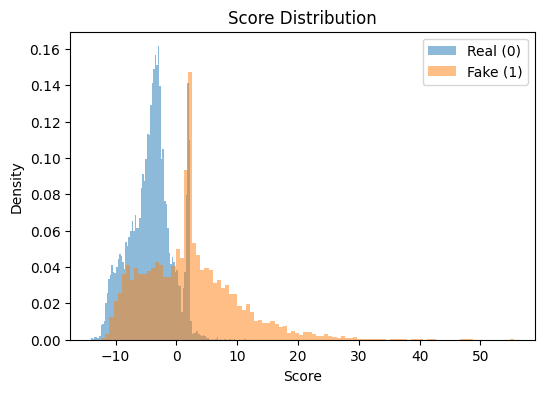

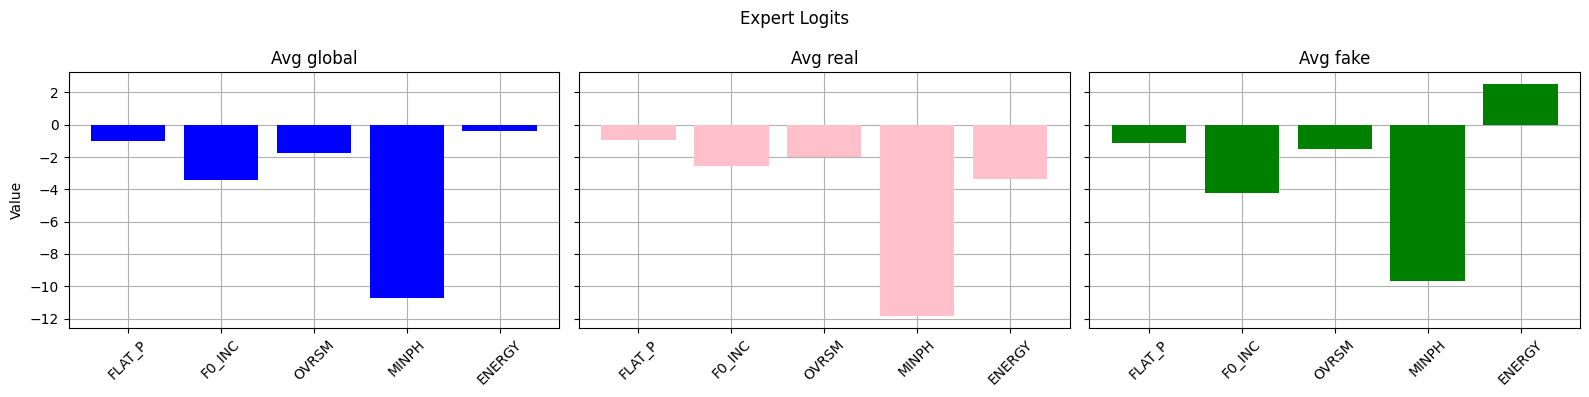

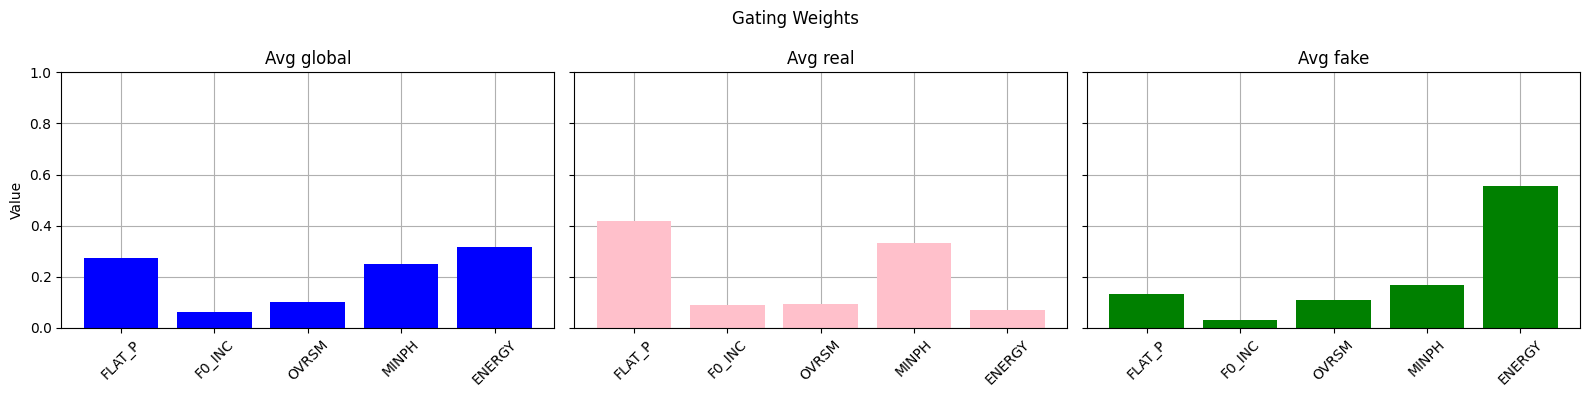

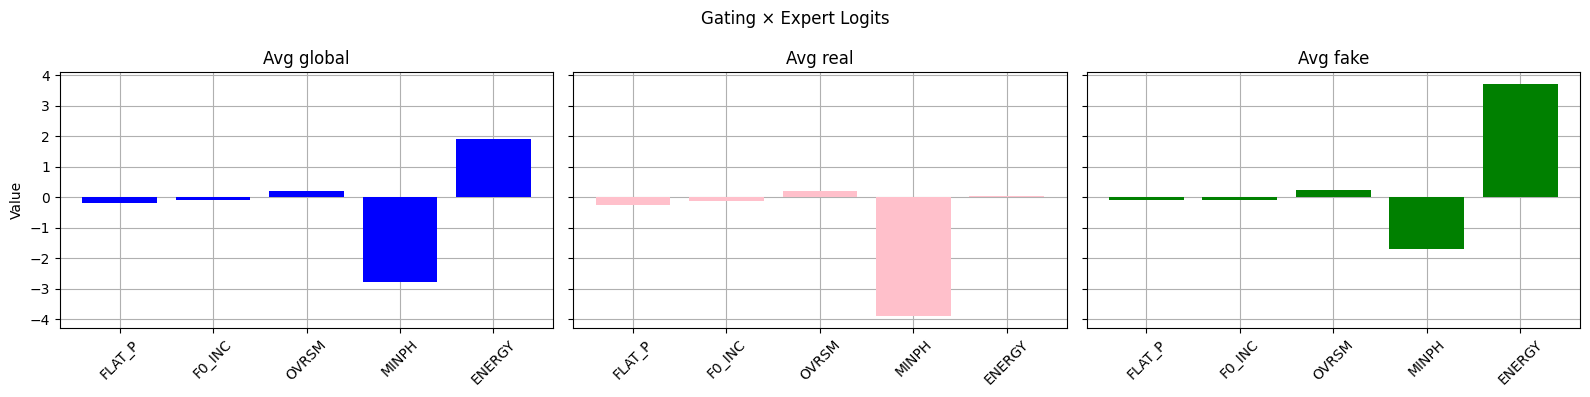

In [16]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/ALL"
model_name = "best_frozen_5_exp_new"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

# Per generator analysis

A01

Individual Experts' Performance:
AUC: 72.92%, EER: 31.99%
AUC: 32.78%, EER: 62.91%
AUC: 79.52%, EER: 30.07%
AUC: 73.13%, EER: 33.37%
AUC: 79.96%, EER: 25.29%

MoE Performance:
AUC: 81.07%, EER: 24.76%
Loaded 1898 samples
Real mean score: -4.0981
Fake mean score: -0.0330



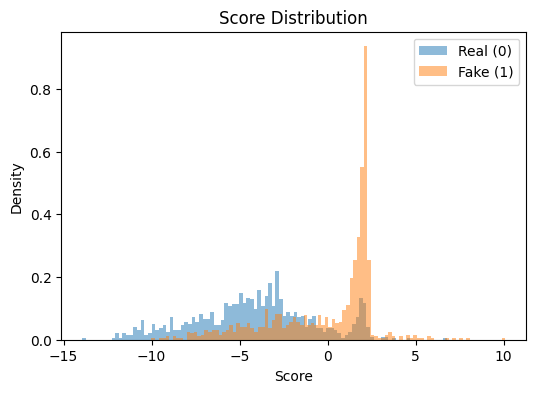

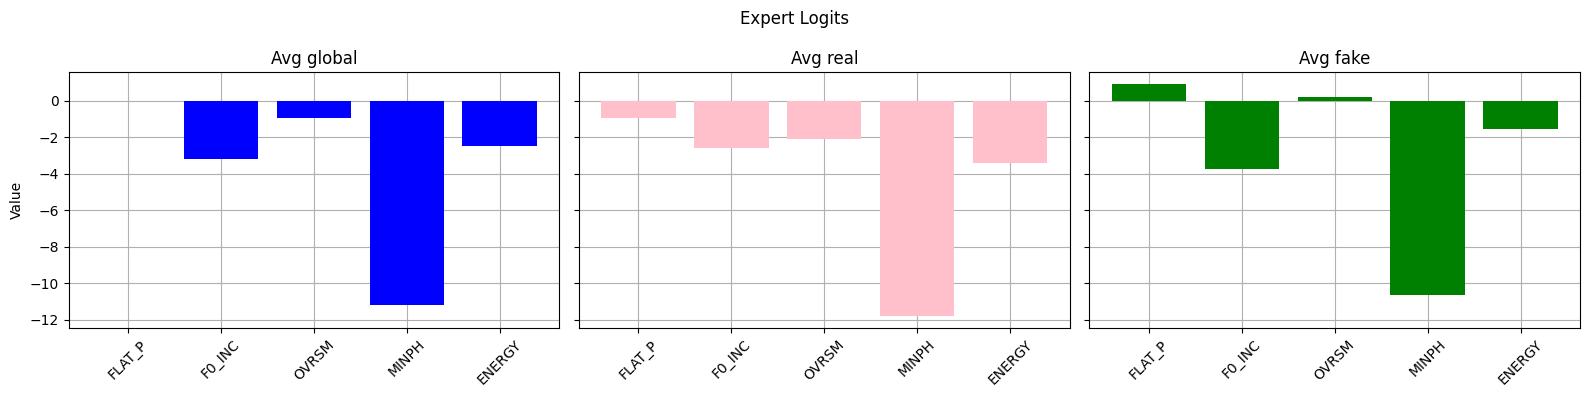

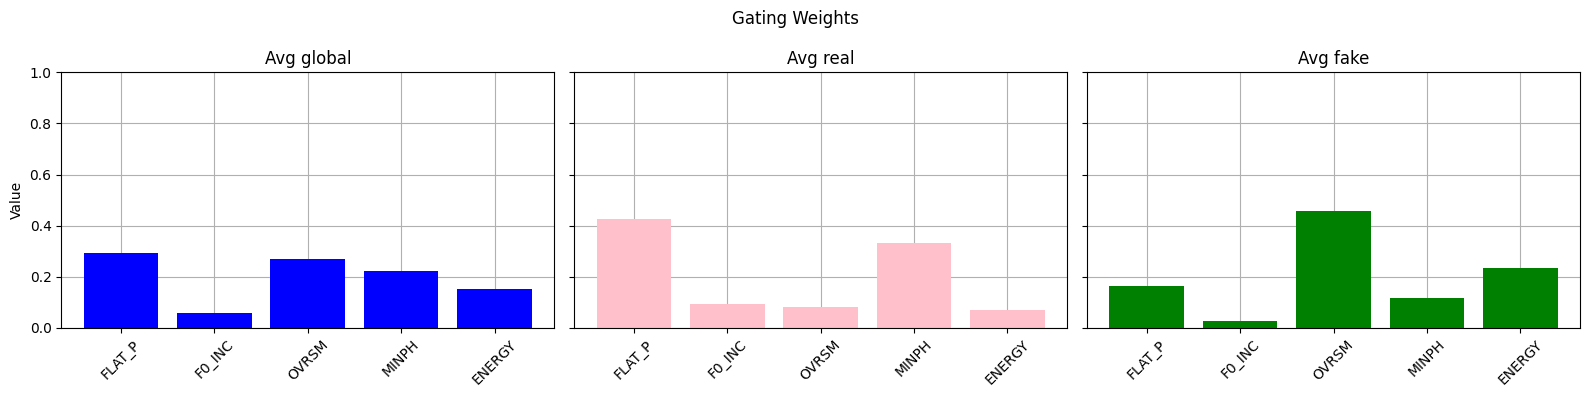

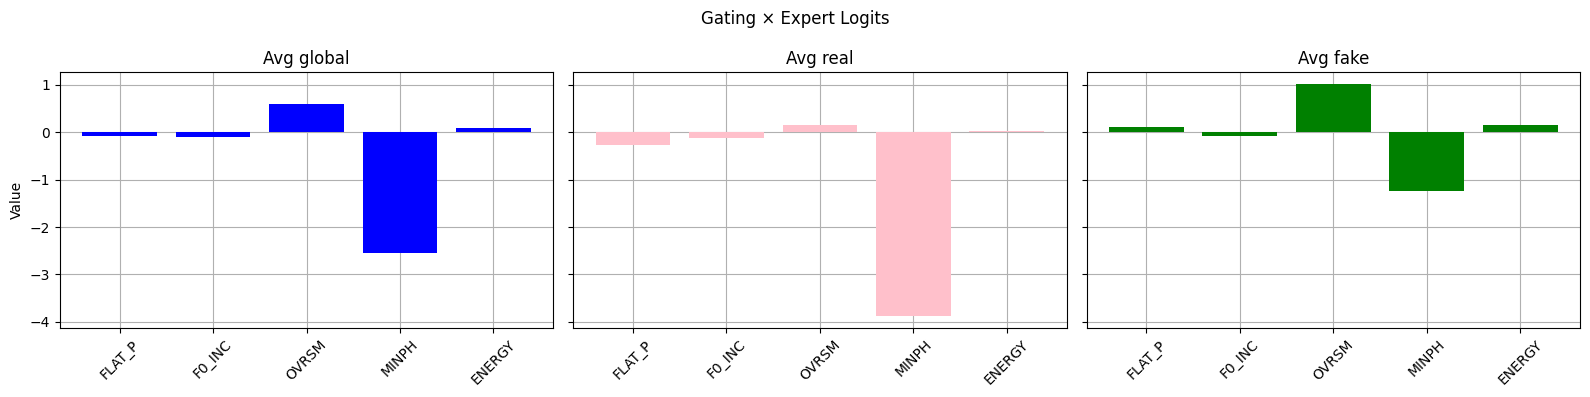

-----------------------------------
A02

Individual Experts' Performance:
AUC: 31.26%, EER: 63.02%
AUC: 17.31%, EER: 73.75%
AUC: 66.08%, EER: 39.43%
AUC: 72.41%, EER: 34.75%
AUC: 71.92%, EER: 32.20%

MoE Performance:
AUC: 62.80%, EER: 39.96%
Loaded 1926 samples
Real mean score: -4.0981
Fake mean score: -1.0324



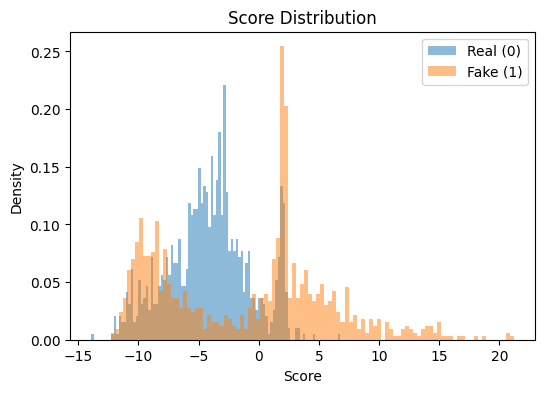

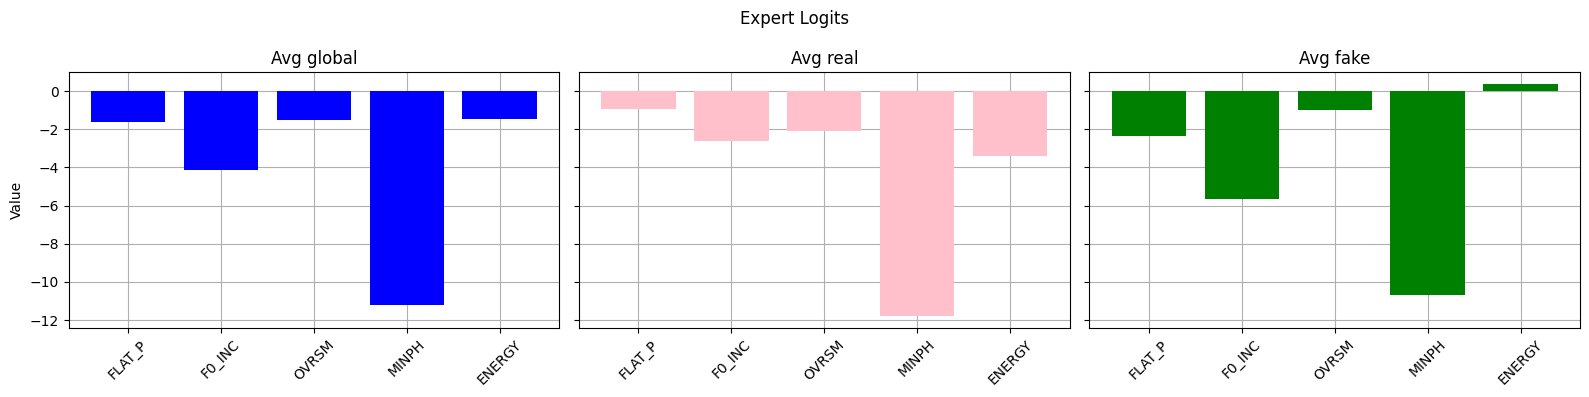

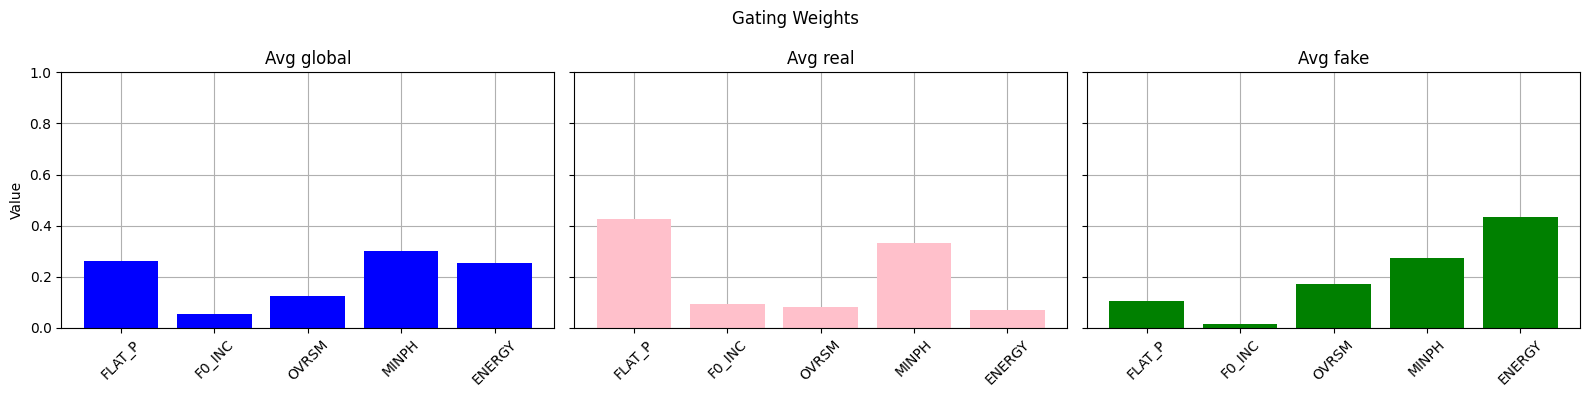

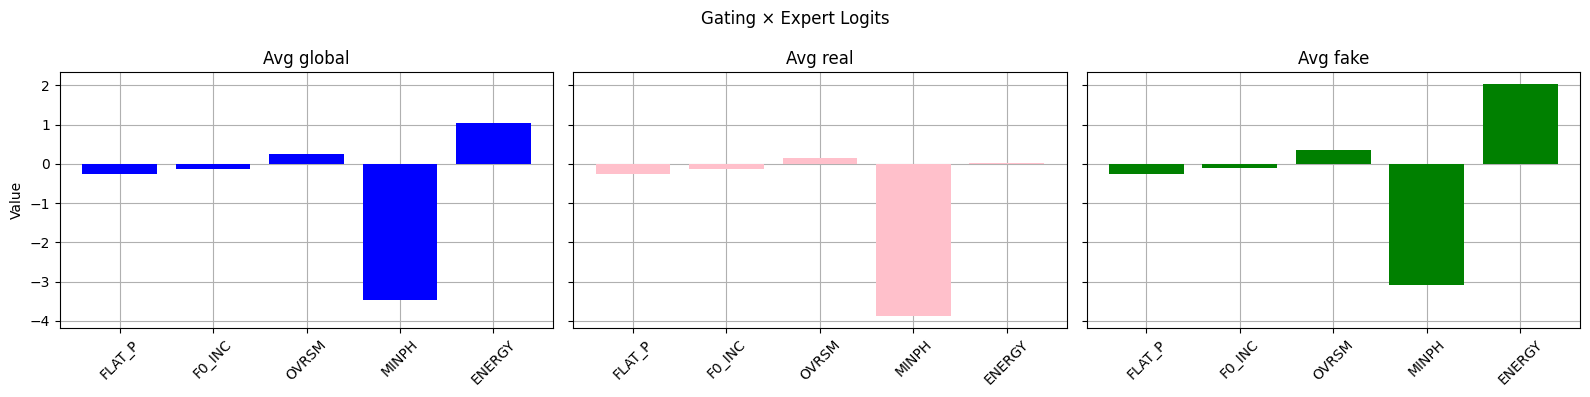

-----------------------------------
A03

Individual Experts' Performance:
AUC: 42.46%, EER: 56.11%
AUC: 22.00%, EER: 69.71%
AUC: 63.72%, EER: 40.60%
AUC: 88.08%, EER: 19.98%
AUC: 96.54%, EER: 9.14%

MoE Performance:
AUC: 89.82%, EER: 14.56%
Loaded 1931 samples
Real mean score: -4.0981
Fake mean score: 2.5090



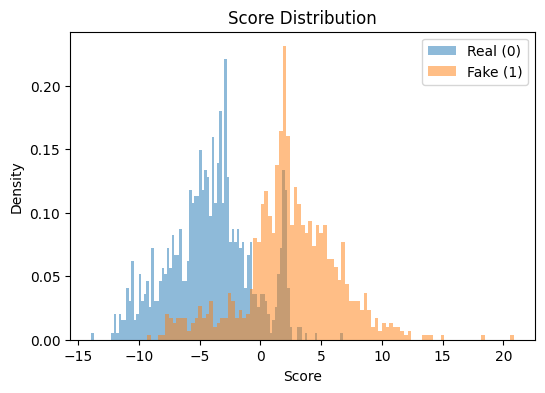

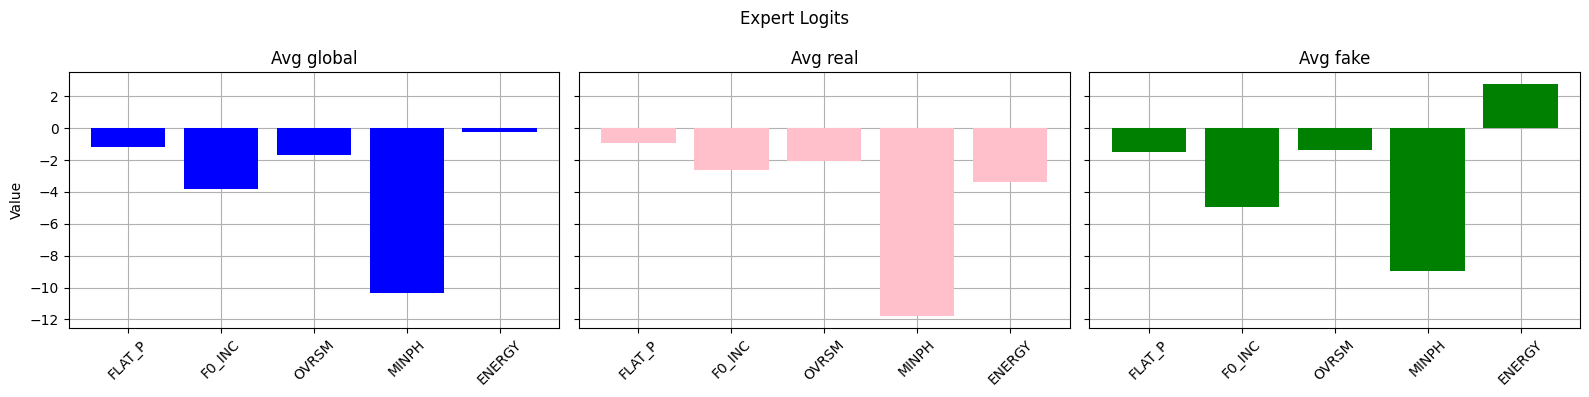

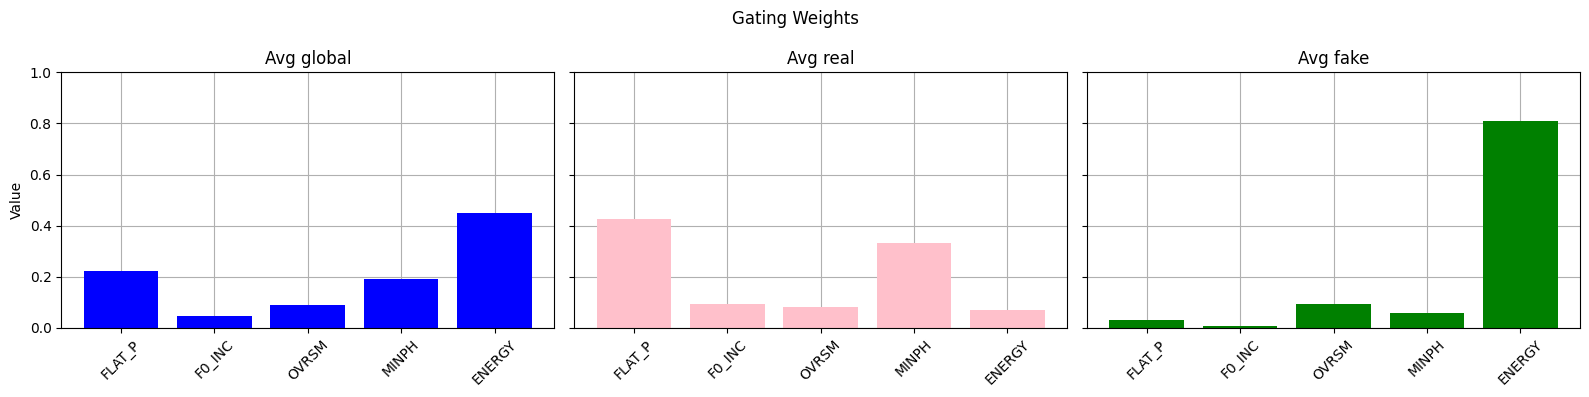

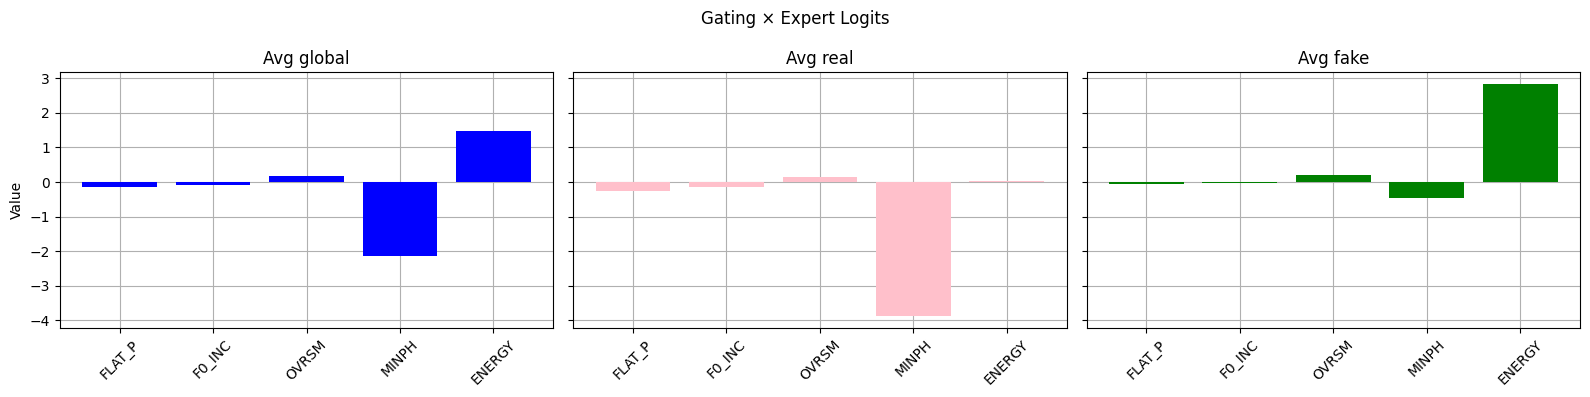

-----------------------------------
A04

Individual Experts' Performance:
AUC: 63.55%, EER: 40.70%
AUC: 72.36%, EER: 34.43%
AUC: 41.74%, EER: 57.60%
AUC: 41.26%, EER: 56.11%
AUC: 89.75%, EER: 19.34%

MoE Performance:
AUC: 90.21%, EER: 19.66%
Loaded 1880 samples
Real mean score: -4.0981
Fake mean score: 6.0657



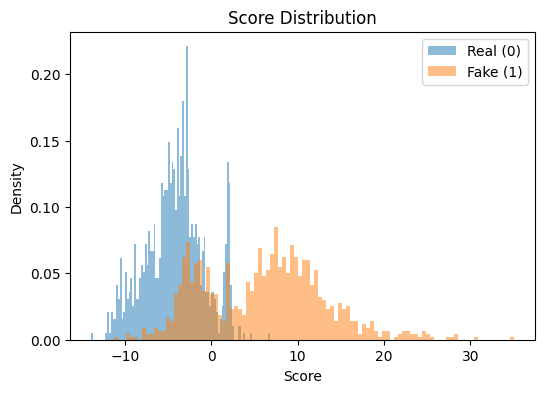

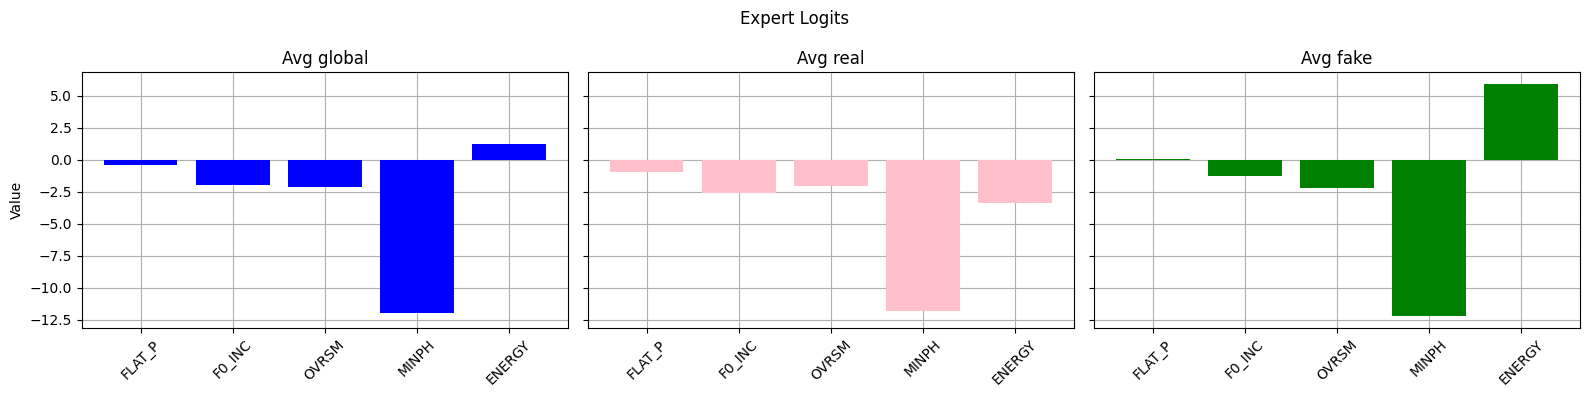

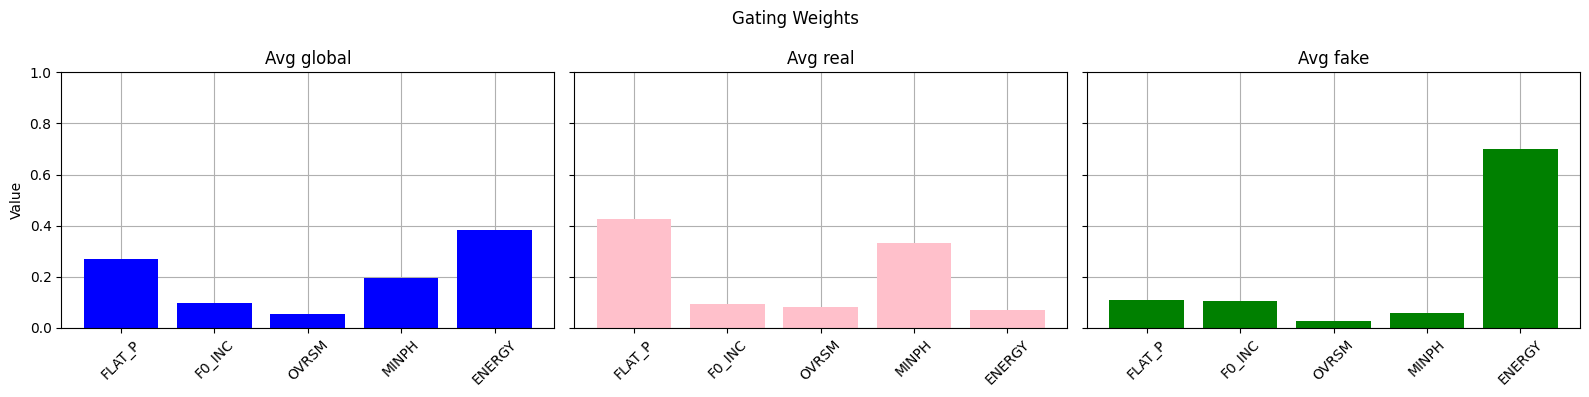

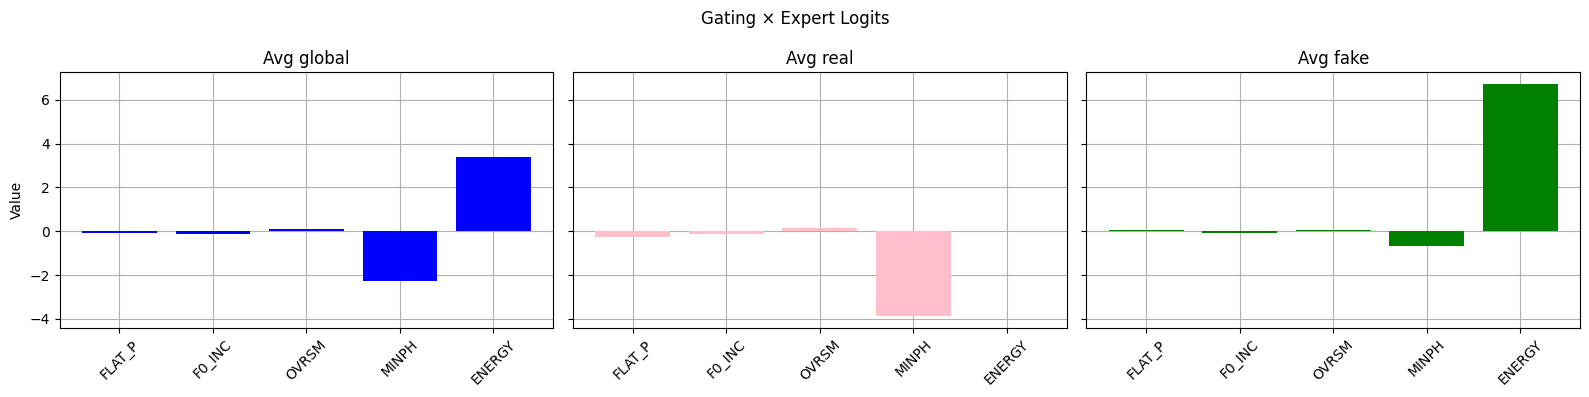

-----------------------------------
A07

Individual Experts' Performance:
AUC: 31.75%, EER: 63.55%
AUC: 13.62%, EER: 76.41%
AUC: 38.91%, EER: 58.77%
AUC: 83.97%, EER: 24.02%
AUC: 63.86%, EER: 38.79%

MoE Performance:
AUC: 37.68%, EER: 63.12%
Loaded 1940 samples
Real mean score: -4.0981
Fake mean score: -5.3140



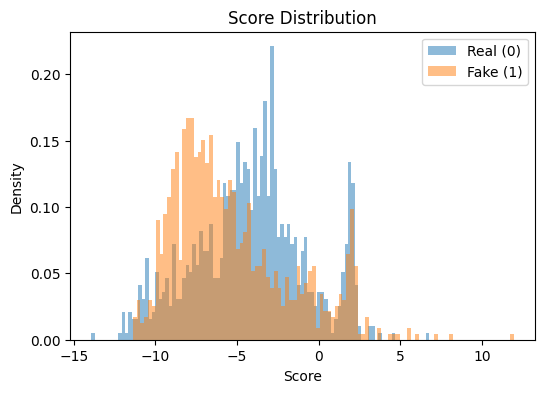

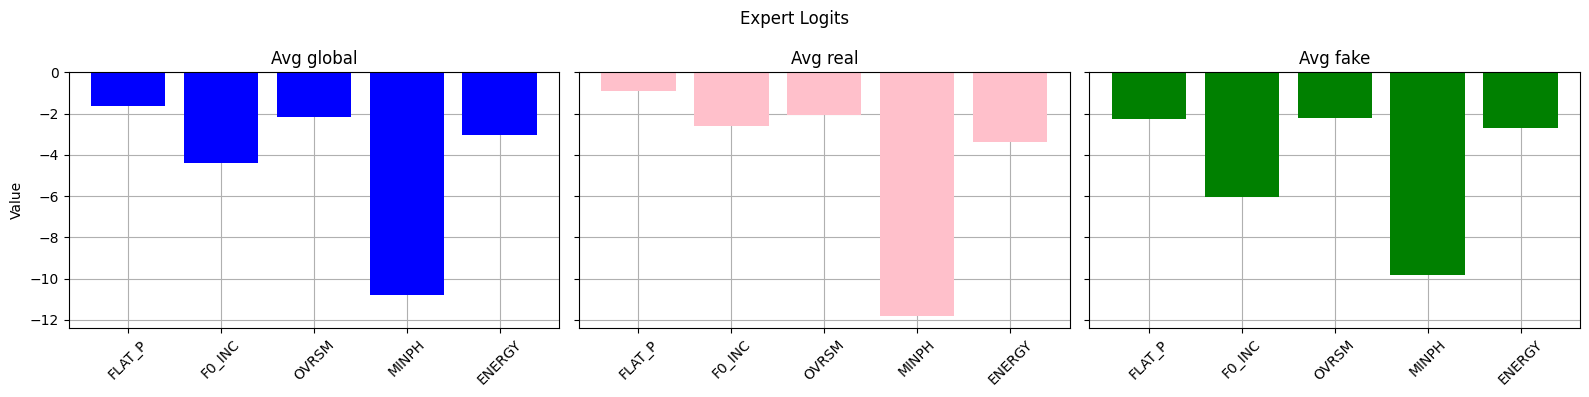

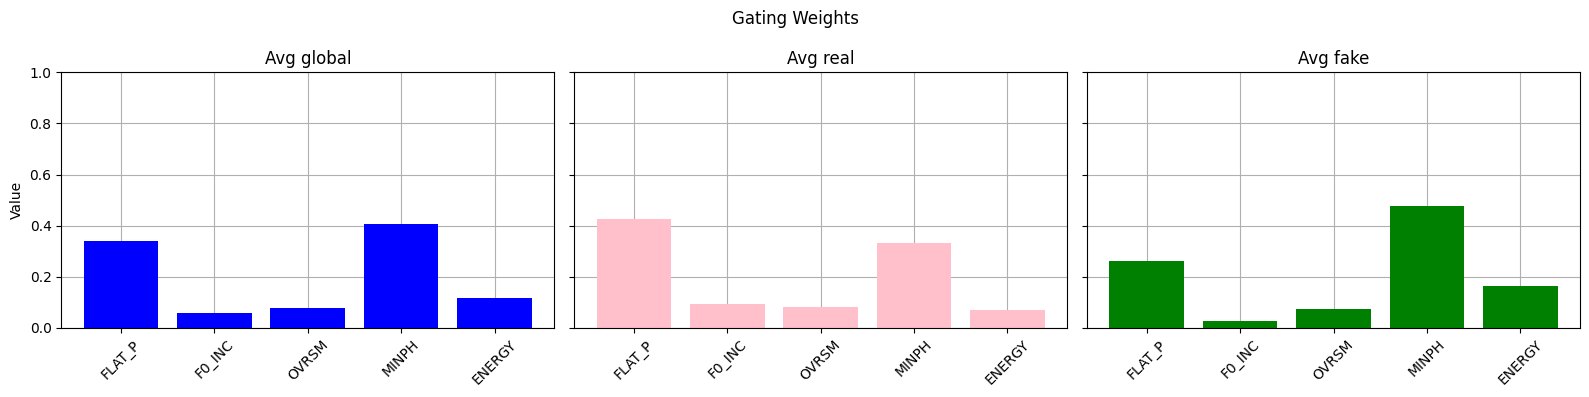

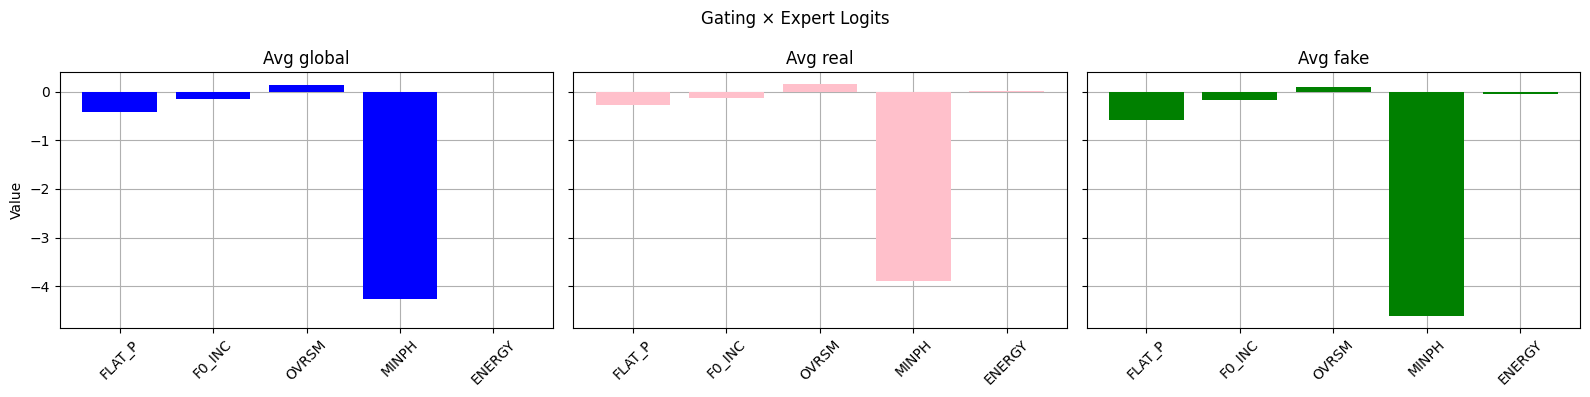

-----------------------------------
A08

Individual Experts' Performance:
AUC: 63.52%, EER: 39.64%
AUC: 26.31%, EER: 67.91%
AUC: 54.58%, EER: 48.78%
AUC: 97.17%, EER: 8.82%
AUC: 96.96%, EER: 8.40%

MoE Performance:
AUC: 92.62%, EER: 14.13%
Loaded 1933 samples
Real mean score: -4.0981
Fake mean score: 3.7455



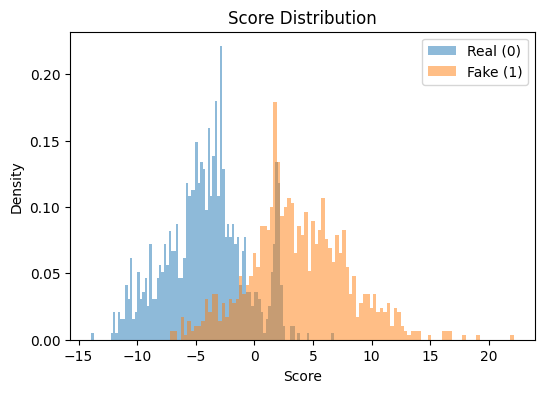

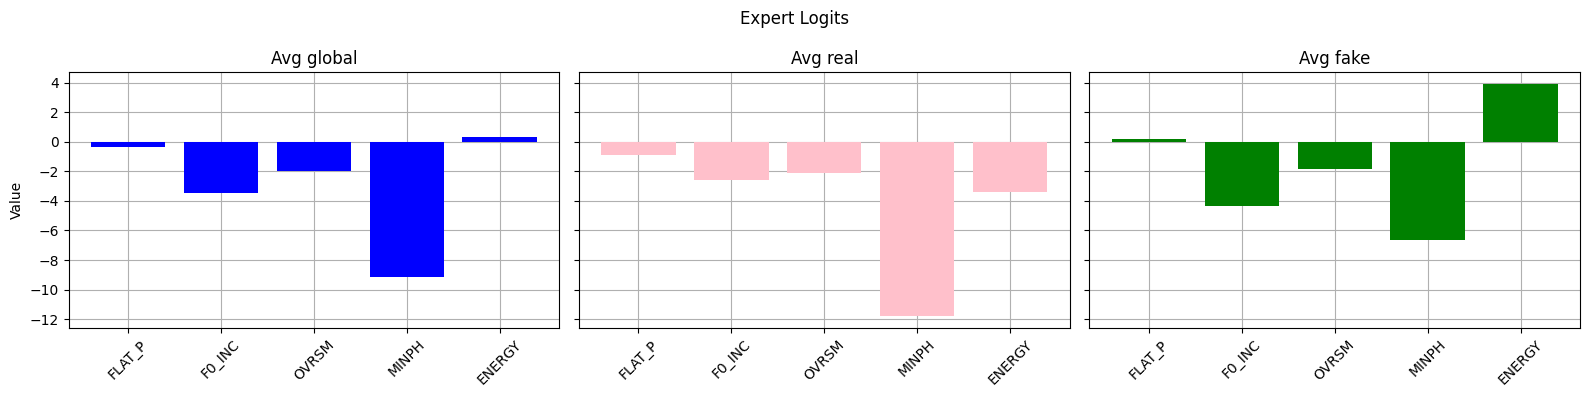

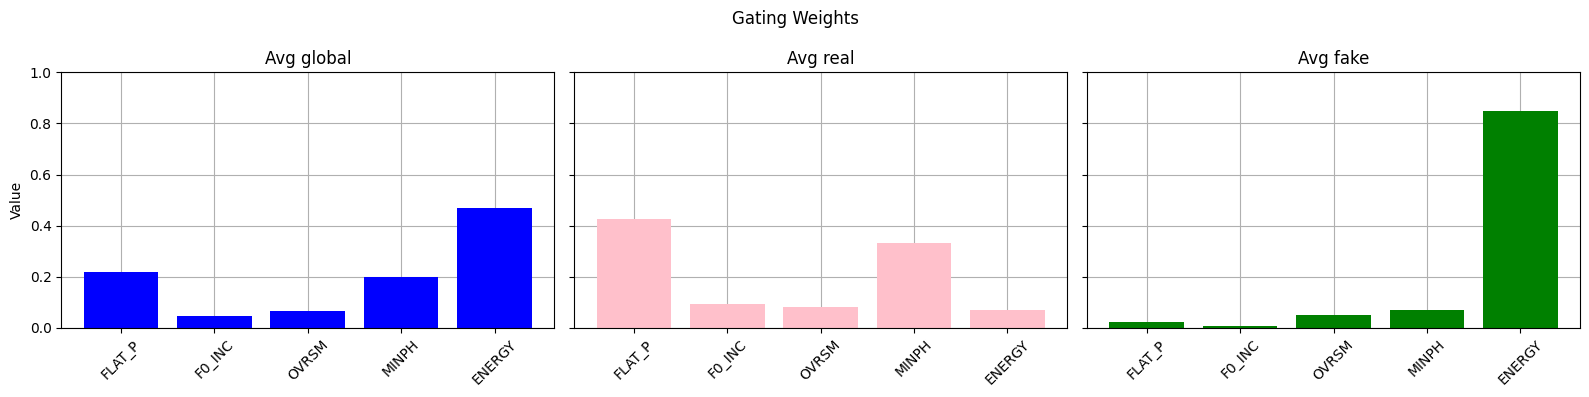

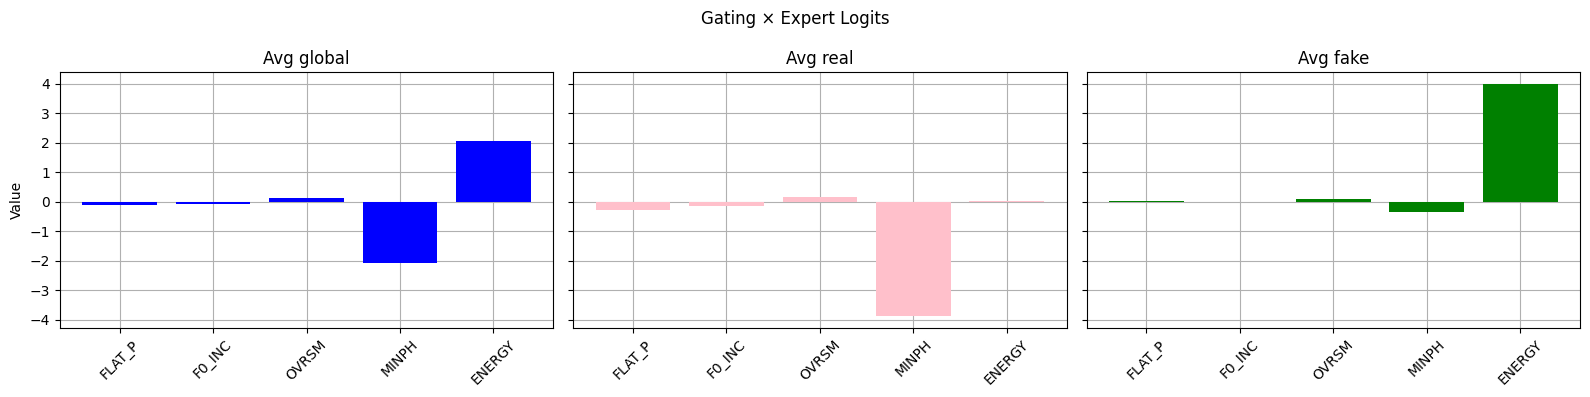

-----------------------------------
A09

Individual Experts' Performance:
AUC: 22.77%, EER: 70.46%
AUC: 15.13%, EER: 75.77%
AUC: 74.59%, EER: 33.90%
AUC: 98.97%, EER: 4.68%
AUC: 97.23%, EER: 8.61%

MoE Performance:
AUC: 94.63%, EER: 12.11%
Loaded 1939 samples
Real mean score: -4.0981
Fake mean score: 10.8509



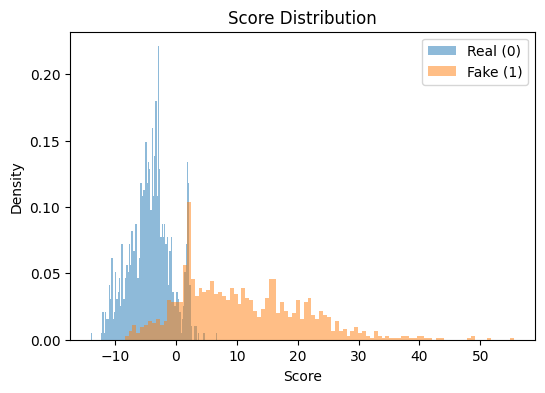

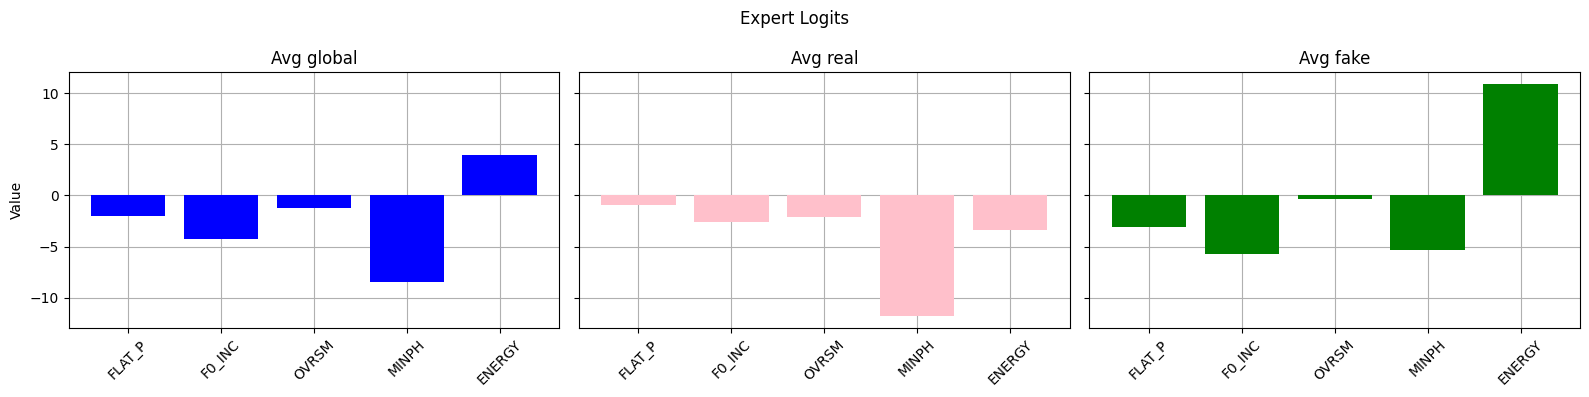

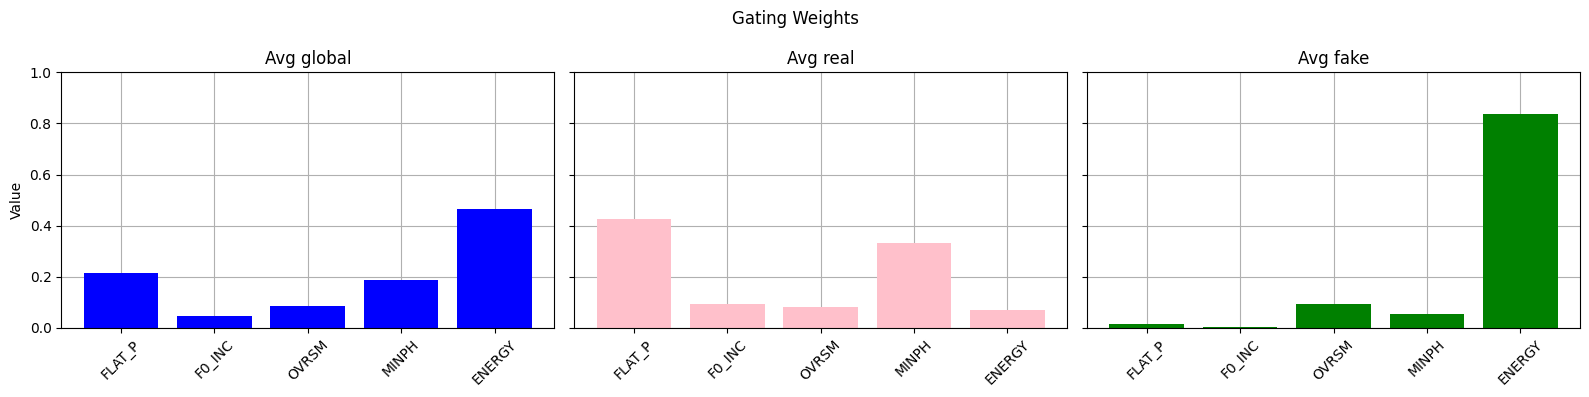

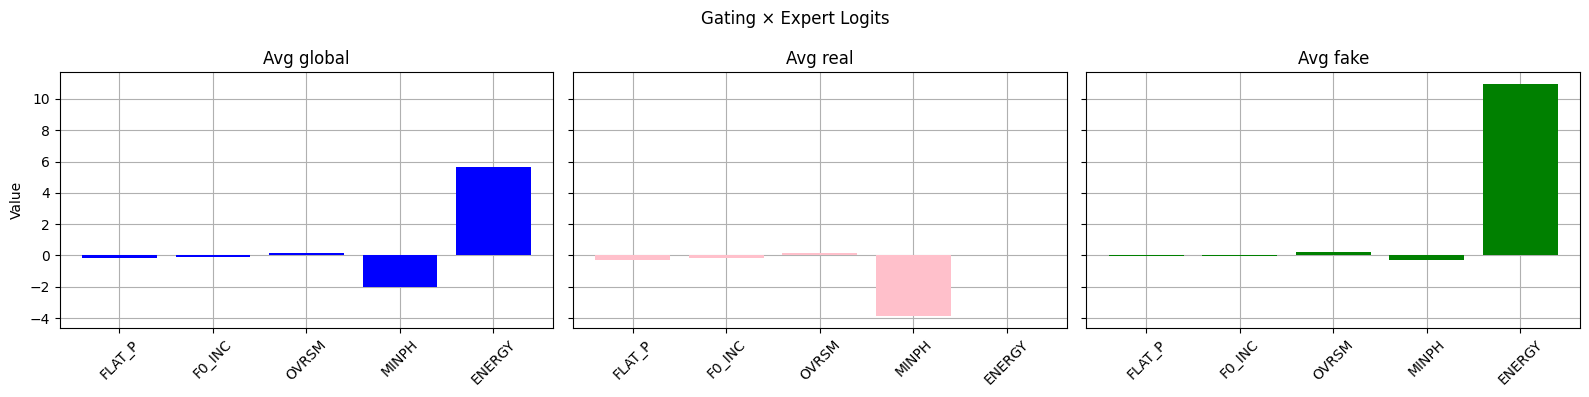

-----------------------------------
A10

Individual Experts' Performance:
AUC: 50.32%, EER: 48.99%
AUC: 38.14%, EER: 58.24%
AUC: 41.40%, EER: 57.60%
AUC: 68.30%, EER: 36.03%
AUC: 58.14%, EER: 43.89%

MoE Performance:
AUC: 50.32%, EER: 49.52%
Loaded 1898 samples
Real mean score: -4.0981
Fake mean score: -4.0514



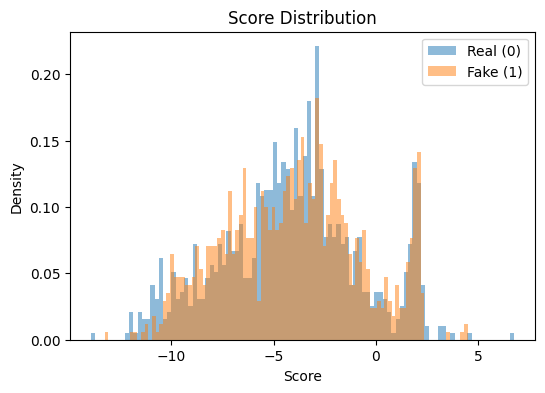

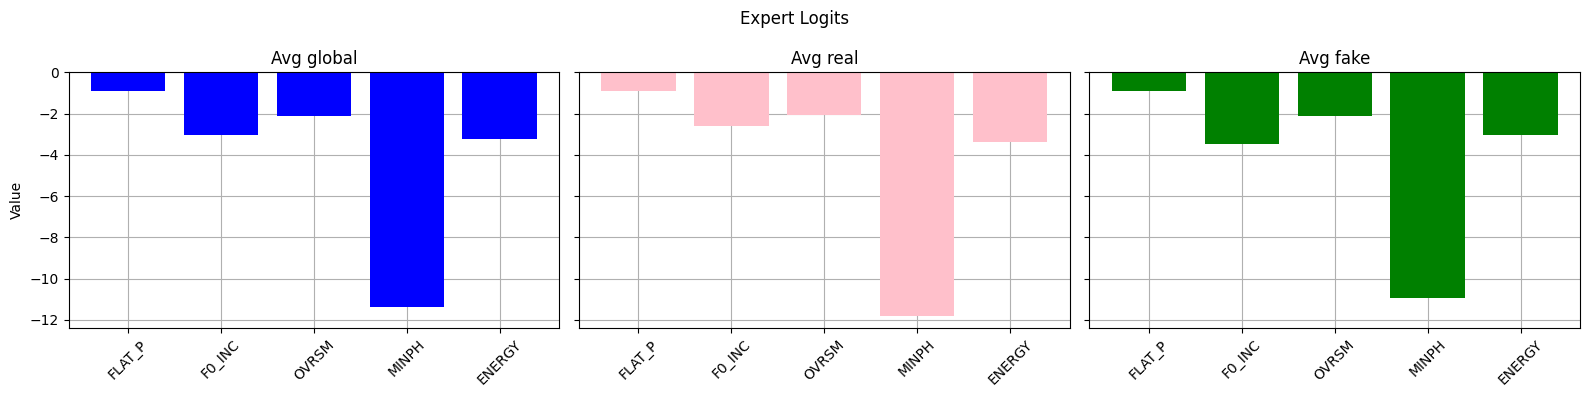

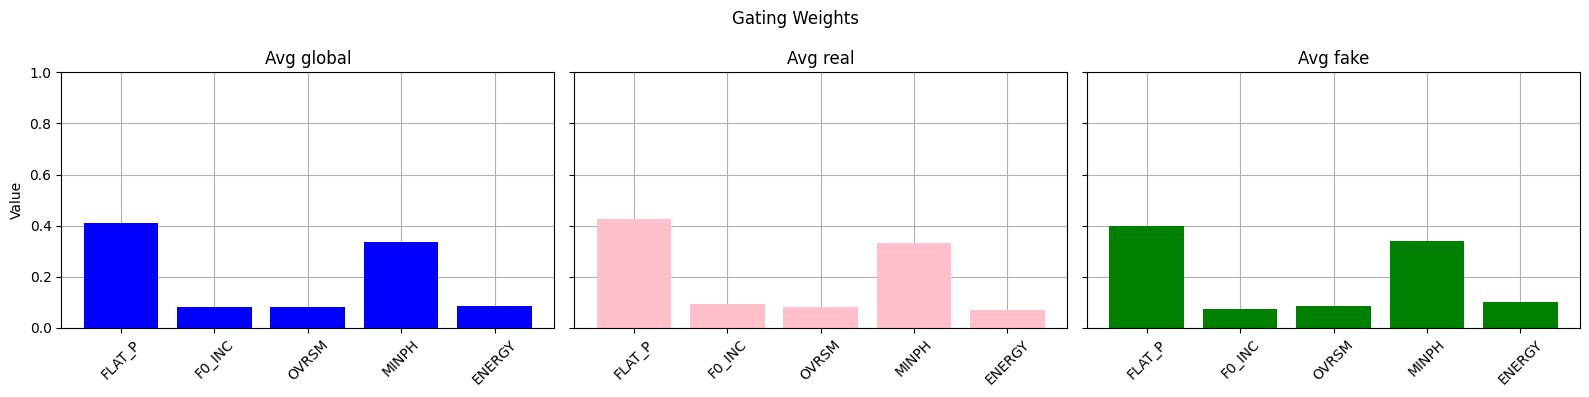

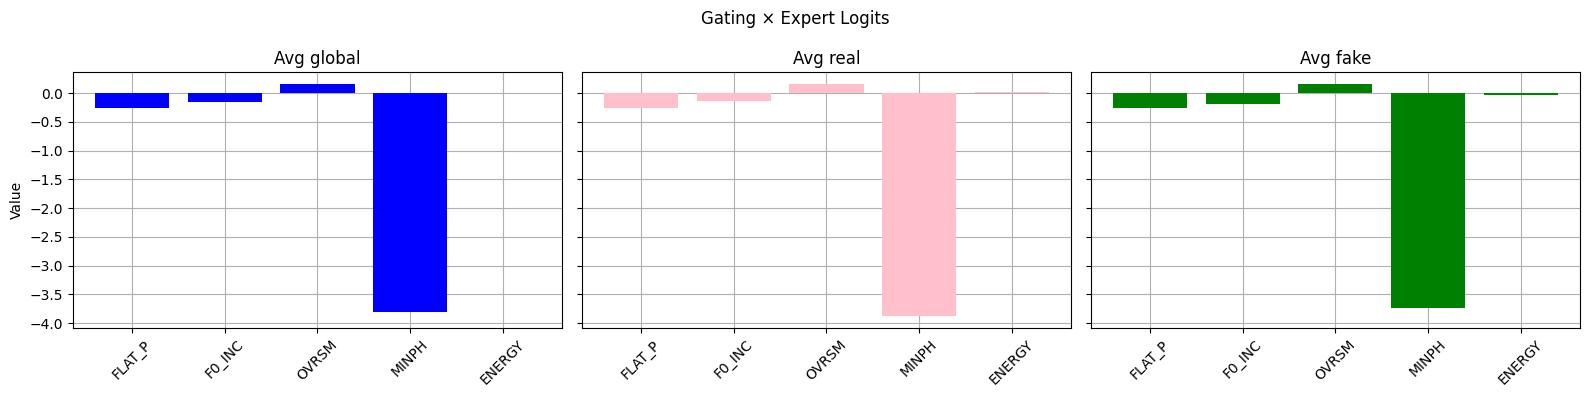

-----------------------------------
A11

Individual Experts' Performance:
AUC: 46.13%, EER: 52.39%
AUC: 35.13%, EER: 59.19%
AUC: 45.27%, EER: 56.11%
AUC: 78.28%, EER: 29.33%
AUC: 82.28%, EER: 25.19%

MoE Performance:
AUC: 78.17%, EER: 28.48%
Loaded 1902 samples
Real mean score: -4.0981
Fake mean score: 1.4695



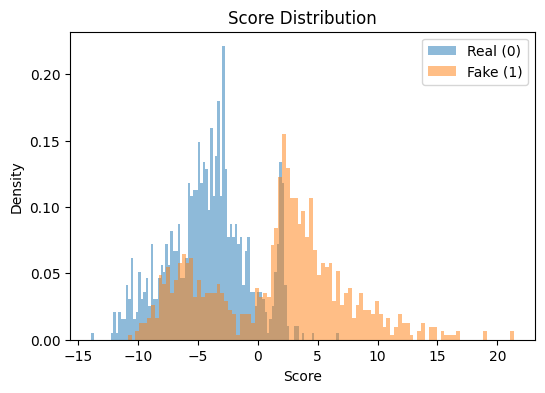

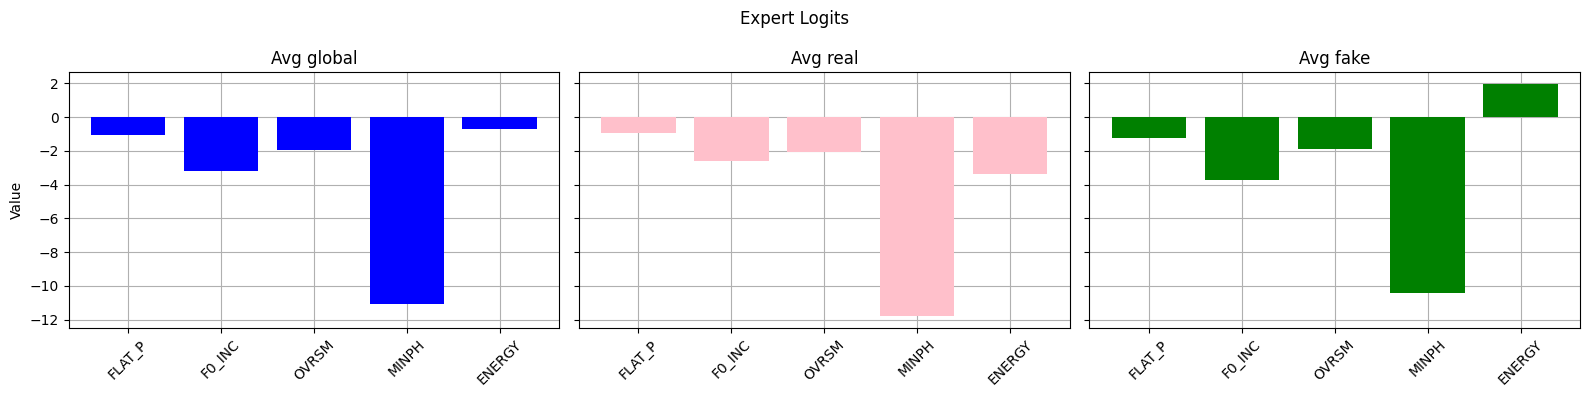

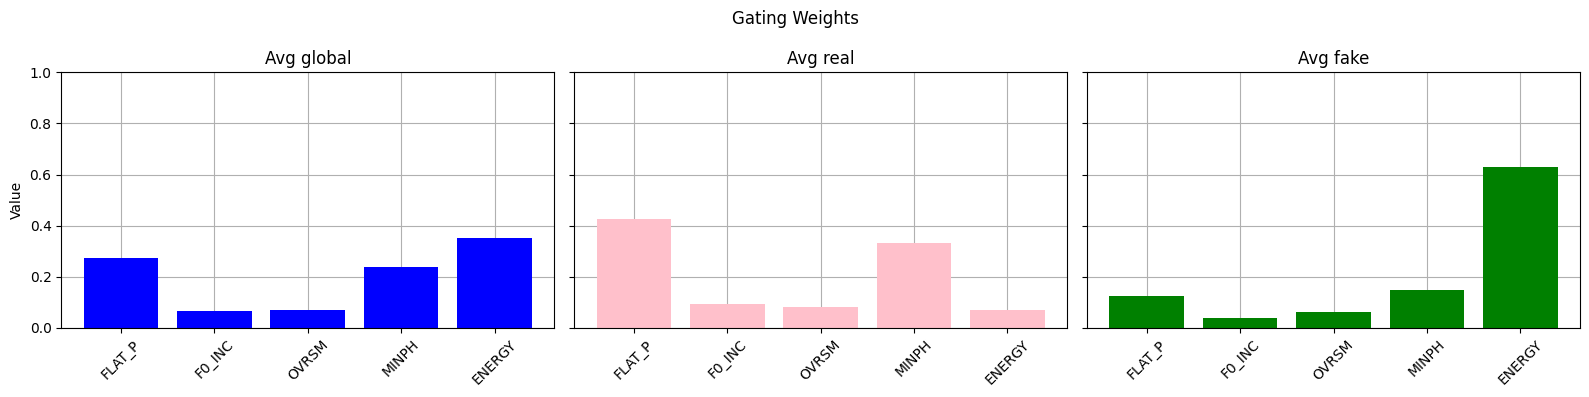

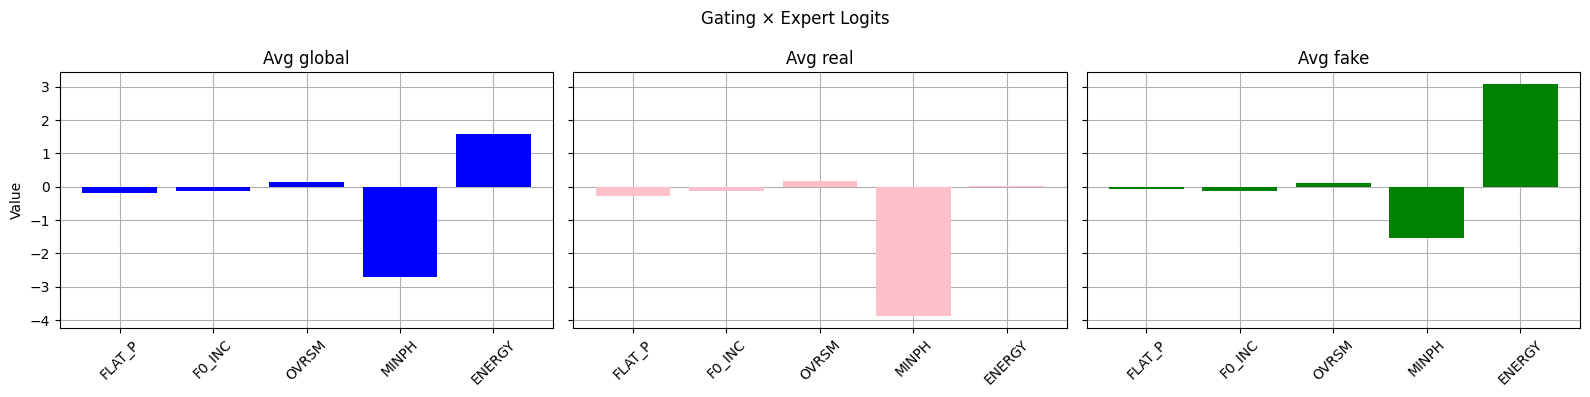

-----------------------------------
A12

Individual Experts' Performance:
AUC: 52.39%, EER: 48.14%
AUC: 39.70%, EER: 56.64%
AUC: 39.32%, EER: 58.45%
AUC: 59.22%, EER: 43.78%
AUC: 86.44%, EER: 18.92%

MoE Performance:
AUC: 85.74%, EER: 20.51%
Loaded 1876 samples
Real mean score: -4.0981
Fake mean score: 6.3197



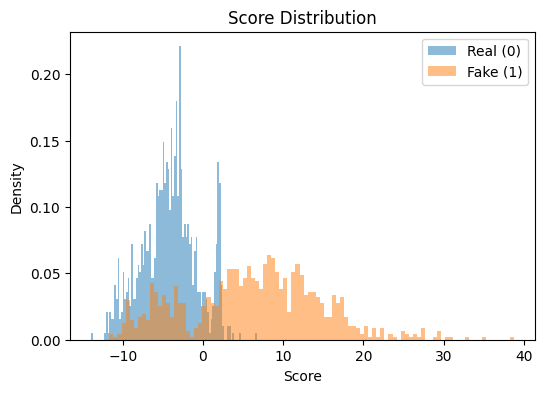

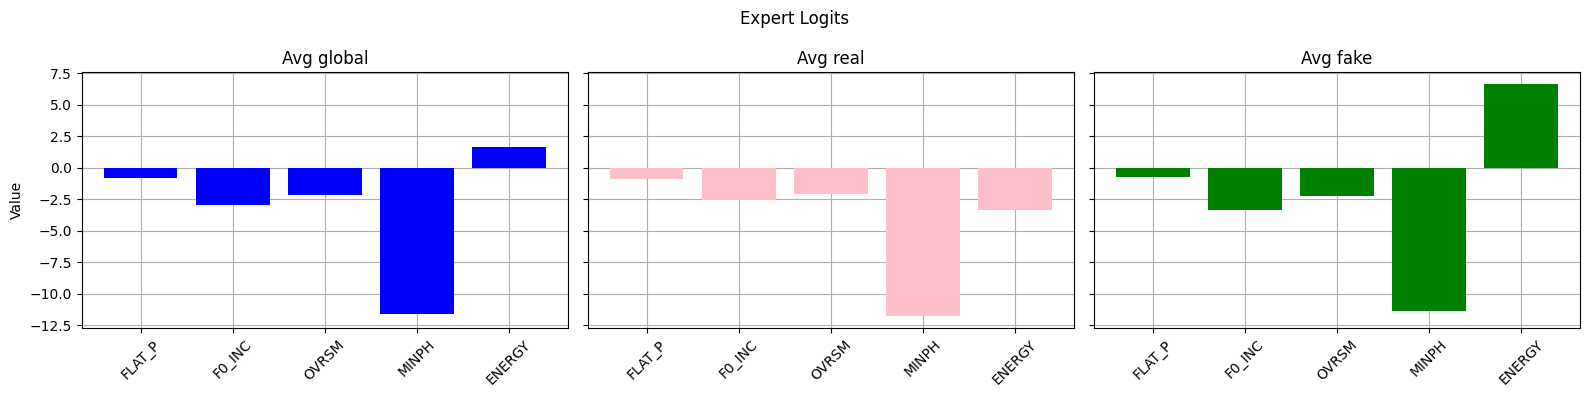

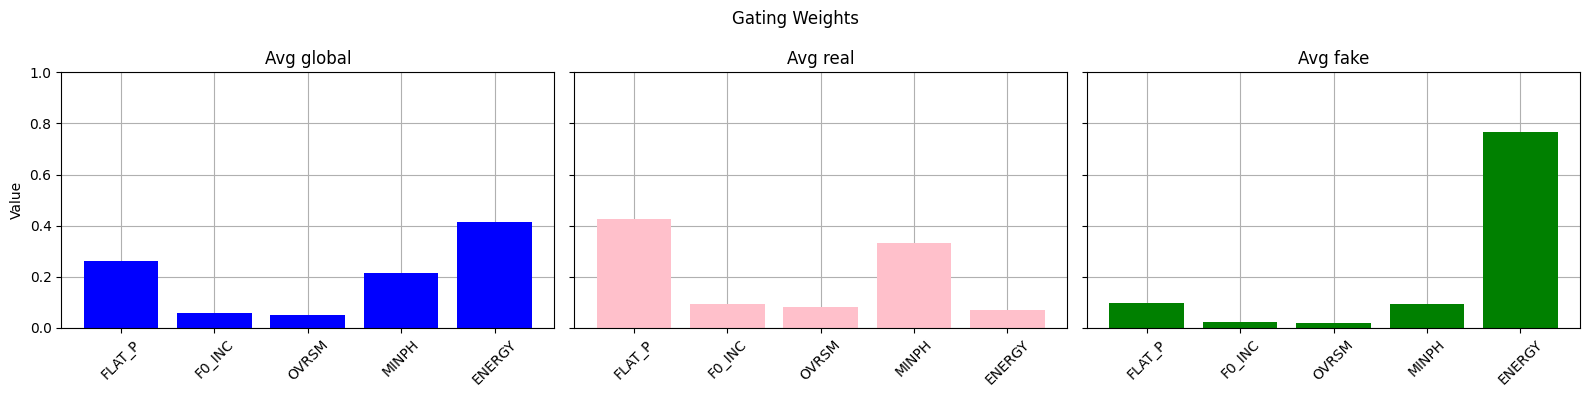

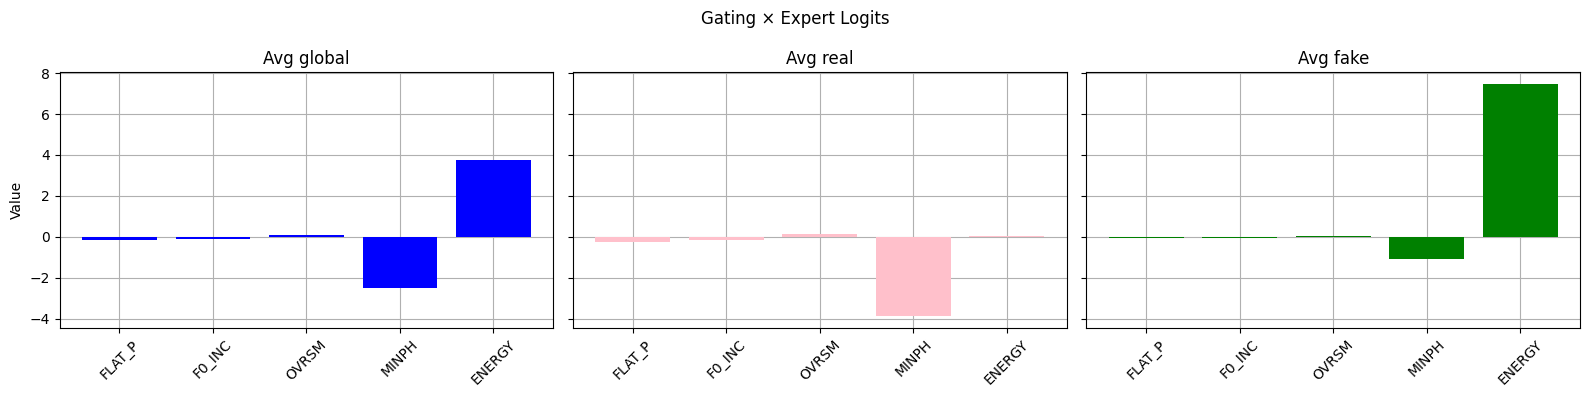

-----------------------------------


In [17]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07',  'A08', 'A09', 'A10', 'A11', 'A12']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/{g}"
    model_name = "best_frozen_5_exp_new"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True, plot=True)
    print("-----------------------------------")

# Sanity Checks (test on real + manipulated data)

## Individual Expert Performance (No MoE)
| Expert         | AUC (%) | EER (%) | Avg F | Avg R  |
|---------------|---------|---------|-------|--------|
| Flat Pitch    | 93.08   | 14.01   | 1.67  | -2.81  |
| F0 Incons.    | 91.54   | 15.19   | 1.85  | -1.94  |
| Oversmooth    | 93.60   | 10.70   | 2.23  | -1.84  |
| Min. Phase    | 100.00  | 0.00    | 11.85 | -11.83 |
| Energy Inc    | 98.67   | 4.50    | 11.13 | -3.13  |


## Experts within the MoE and MoE itself
NOTE: in this test when a fake sample is to be fed, every expert received a copy of the real sample with only its own manipulation applied (a fake is a fake for everyone, but modifications are not overlayed)  
### ALL manipulations applied:


Individual Experts' Performance:
AUC: 58.45%, EER: 43.32%
AUC: 67.47%, EER: 34.81%
AUC: 93.78%, EER: 10.56%
AUC: 100.00%, EER: 0.00%
AUC: 99.12%, EER: 3.77%

MoE Performance:
AUC: 99.89%, EER: 1.19%
Loaded 1926 samples
Real mean score: -3.6764
Fake mean score: 10.6533



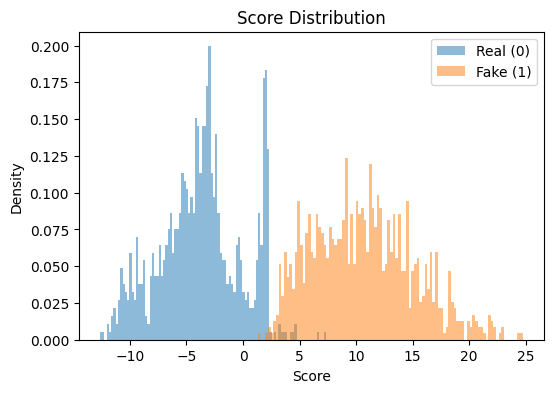

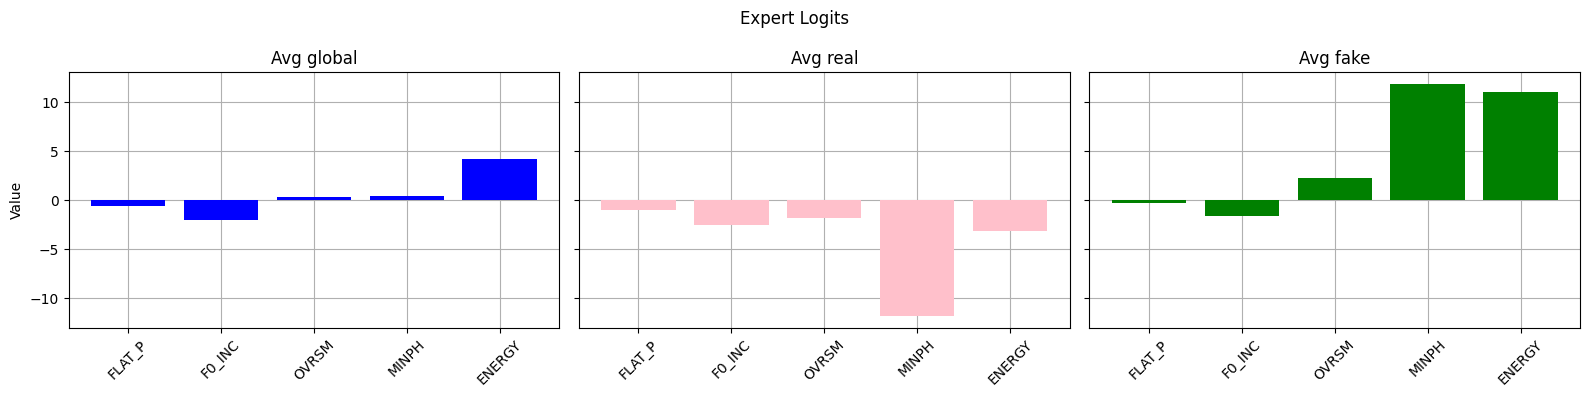

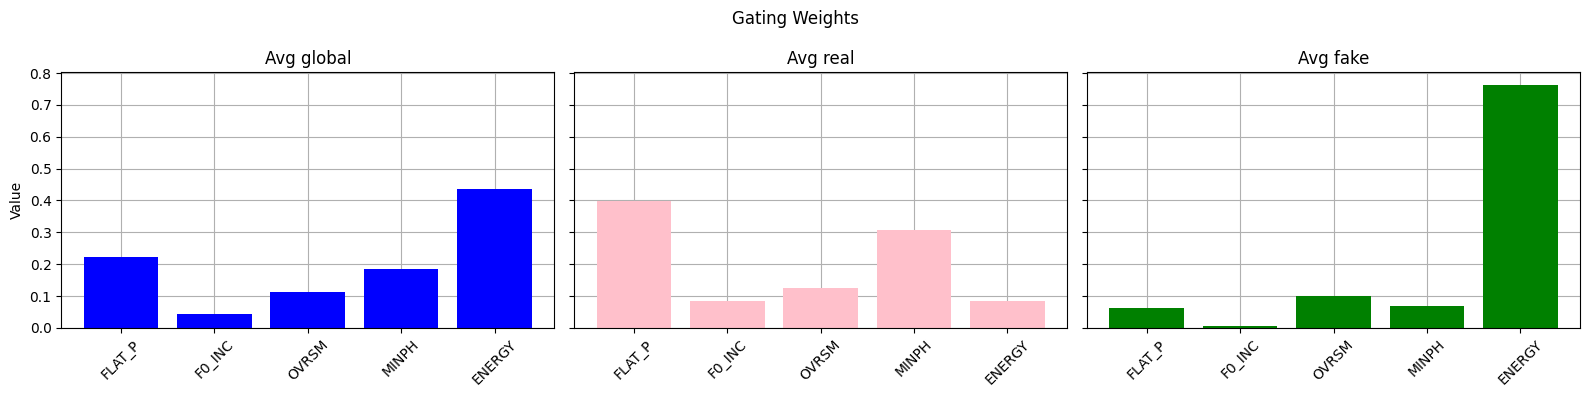

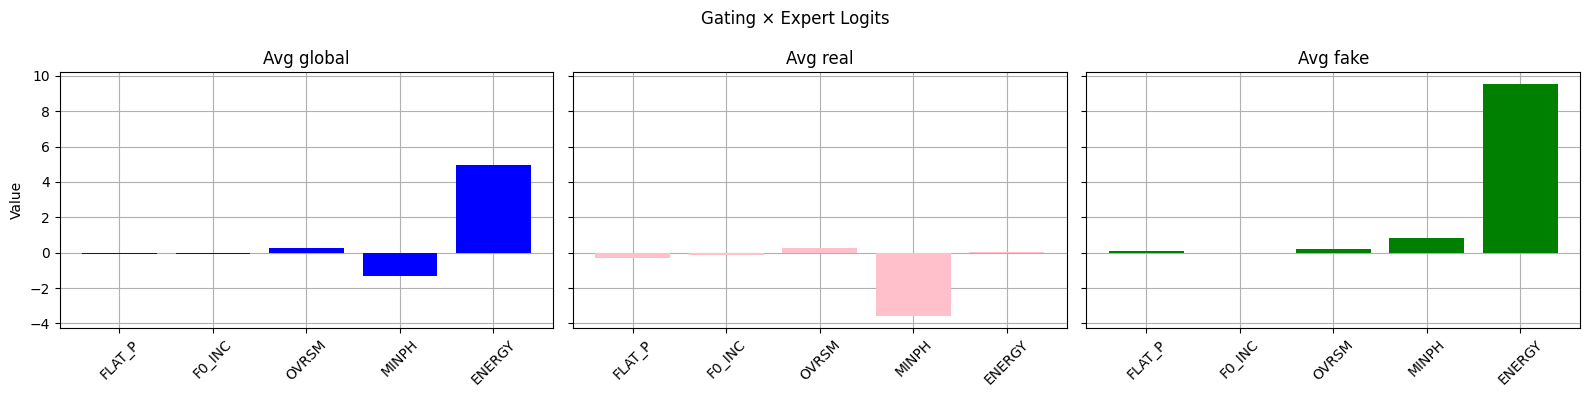

In [22]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/ALL"
model_name = "best_frozen_5_exp_new"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

## One by one


Individual Experts' Performance:
AUC: 51.07%, EER: 34.70%
AUC: 67.47%, EER: 34.81%
AUC: 49.72%, EER: 50.32%
AUC: 50.24%, EER: 51.51%
AUC: 50.40%, EER: 50.54%

MoE Performance:
AUC: 59.40%, EER: 41.70%
Loaded 1926 samples
Real mean score: -3.6764
Fake mean score: -2.4980



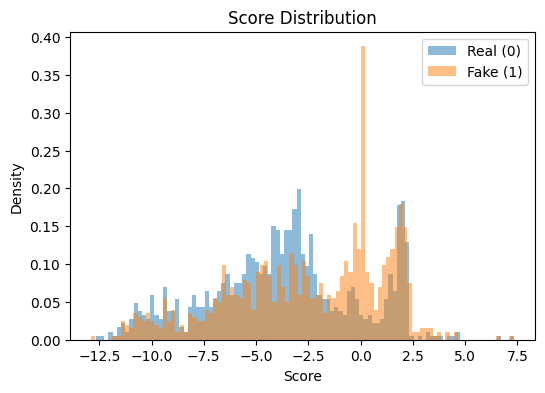

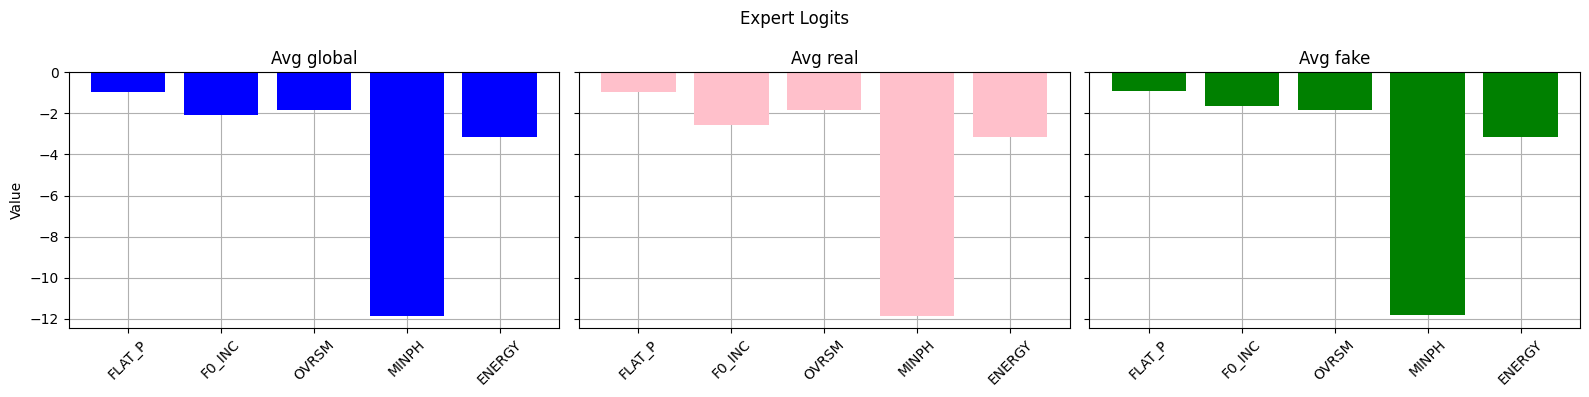

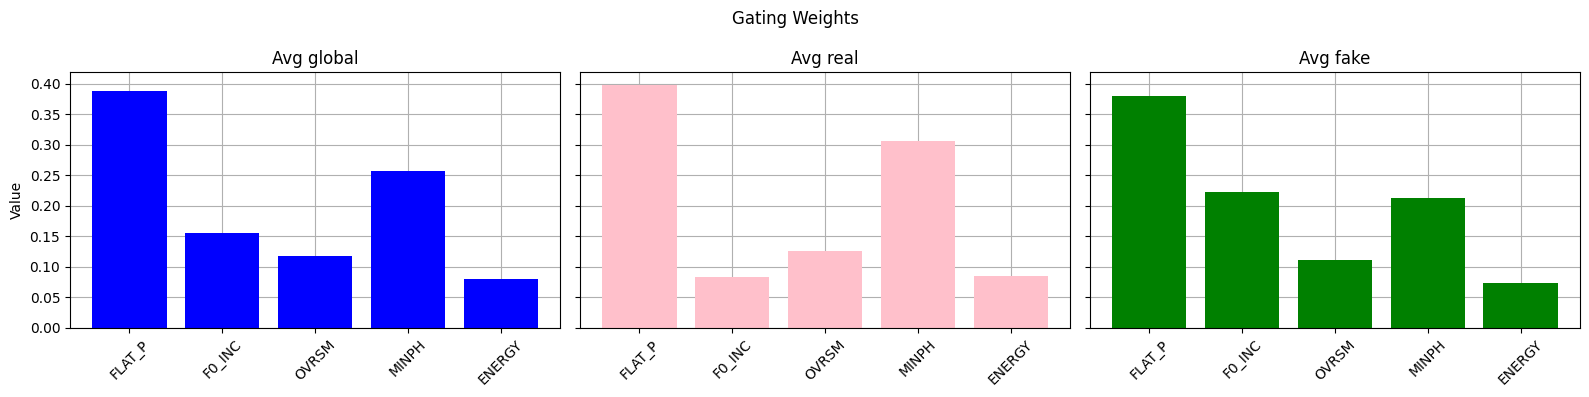

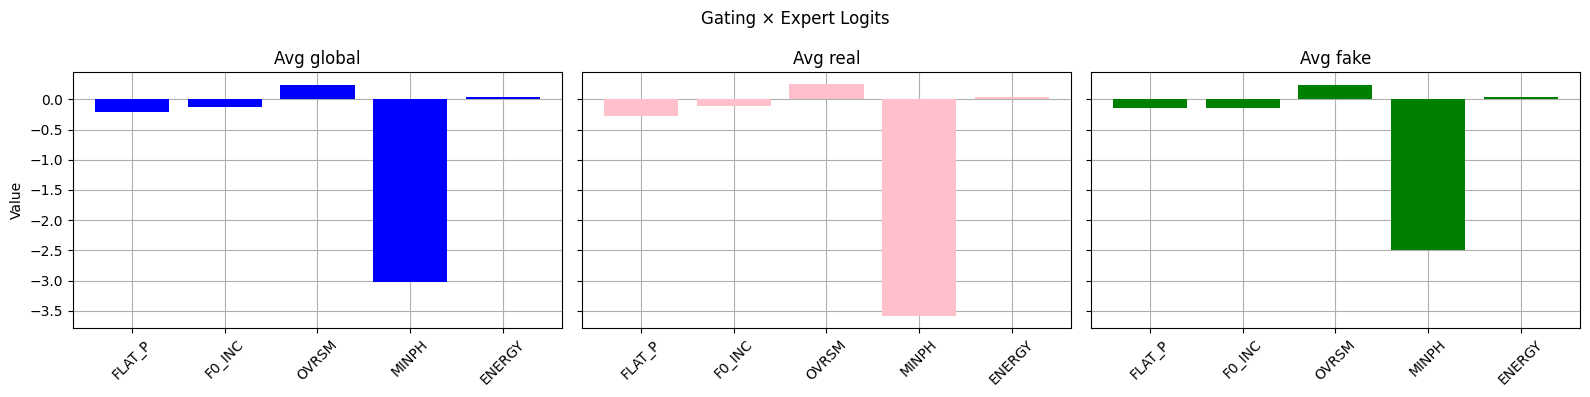

In [23]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/flat_pitch"
model_name = "best_frozen_5_exp_new"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)


Individual Experts' Performance:
AUC: 59.01%, EER: 43.97%
AUC: 53.14%, EER: 48.18%
AUC: 49.84%, EER: 50.20%
AUC: 49.74%, EER: 50.05%
AUC: 51.08%, EER: 49.14%

MoE Performance:
AUC: 79.42%, EER: 23.06%
Loaded 1926 samples
Real mean score: -3.7767
Fake mean score: -0.6082



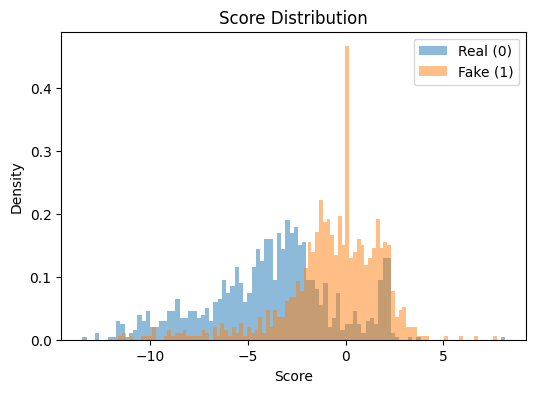

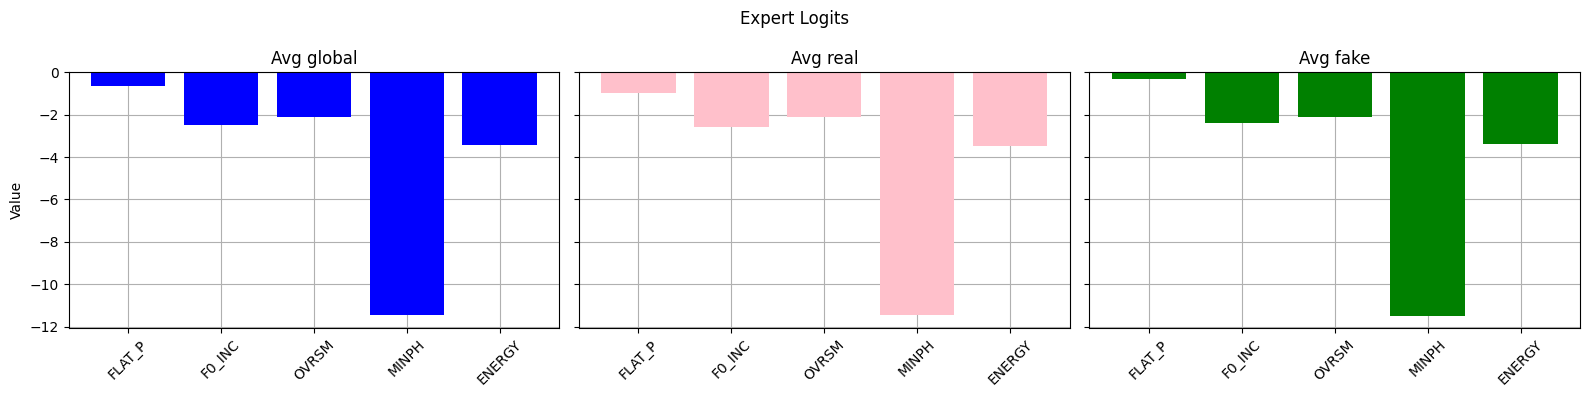

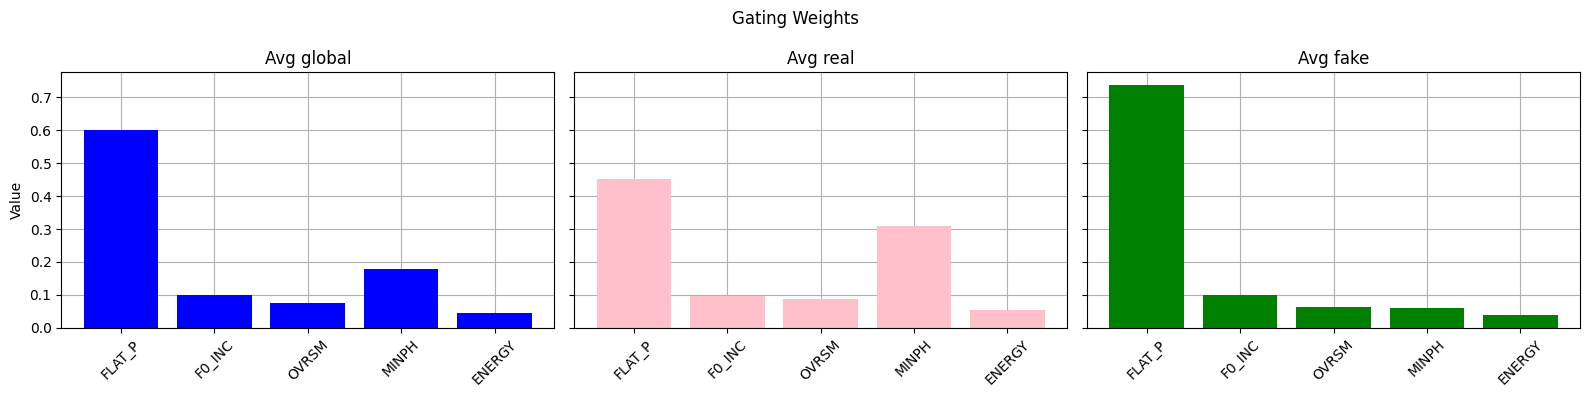

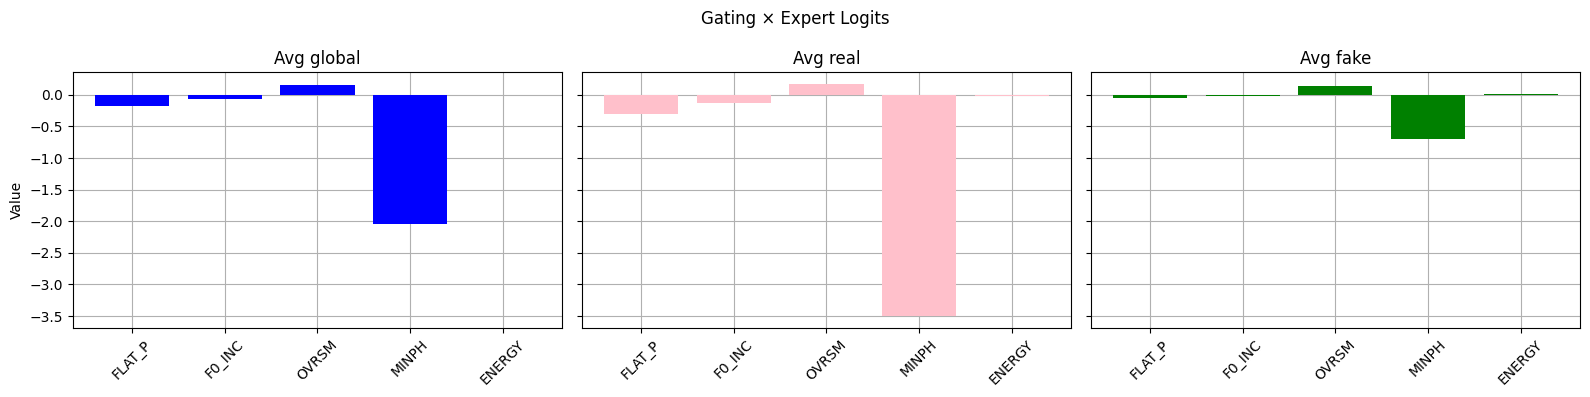

In [31]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/f0_incons"
model_name = "best_frozen_5_exp_new"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)


Individual Experts' Performance:
AUC: 51.07%, EER: 34.70%
AUC: 53.14%, EER: 5.28%
AUC: 93.78%, EER: 10.56%
AUC: 50.24%, EER: 51.51%
AUC: 50.40%, EER: 50.54%

MoE Performance:
AUC: 92.43%, EER: 11.96%
Loaded 1926 samples
Real mean score: -3.6764
Fake mean score: 1.9263



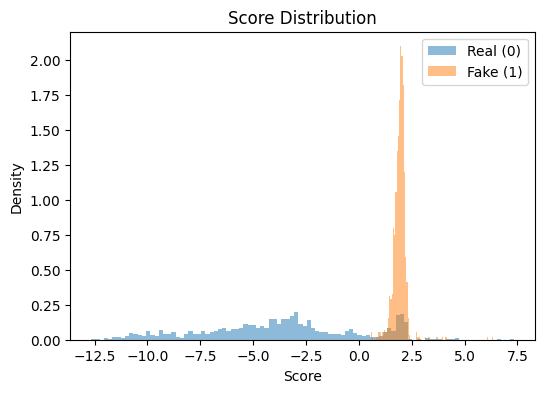

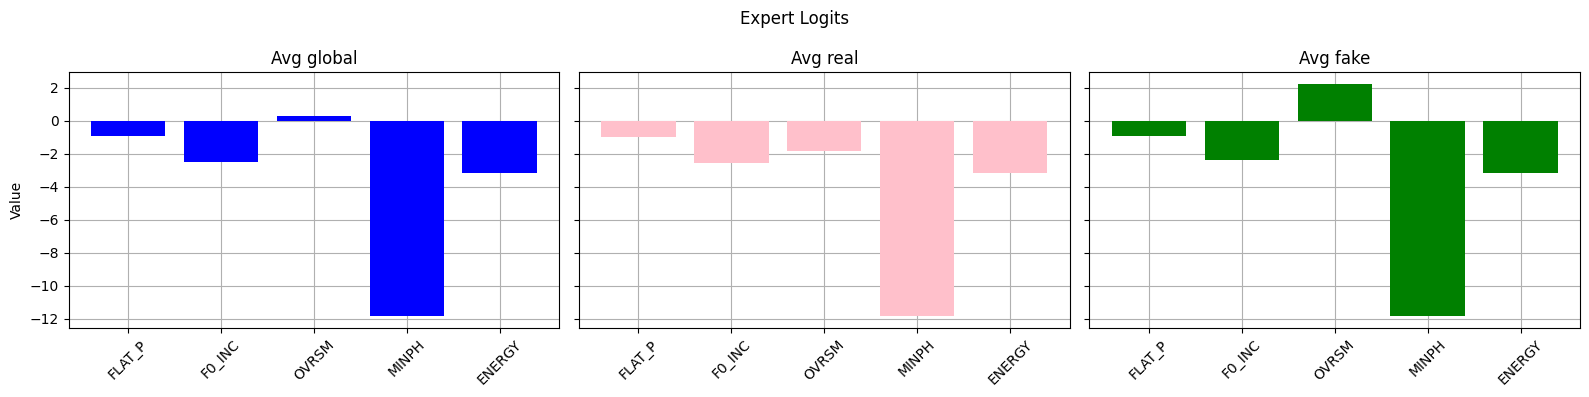

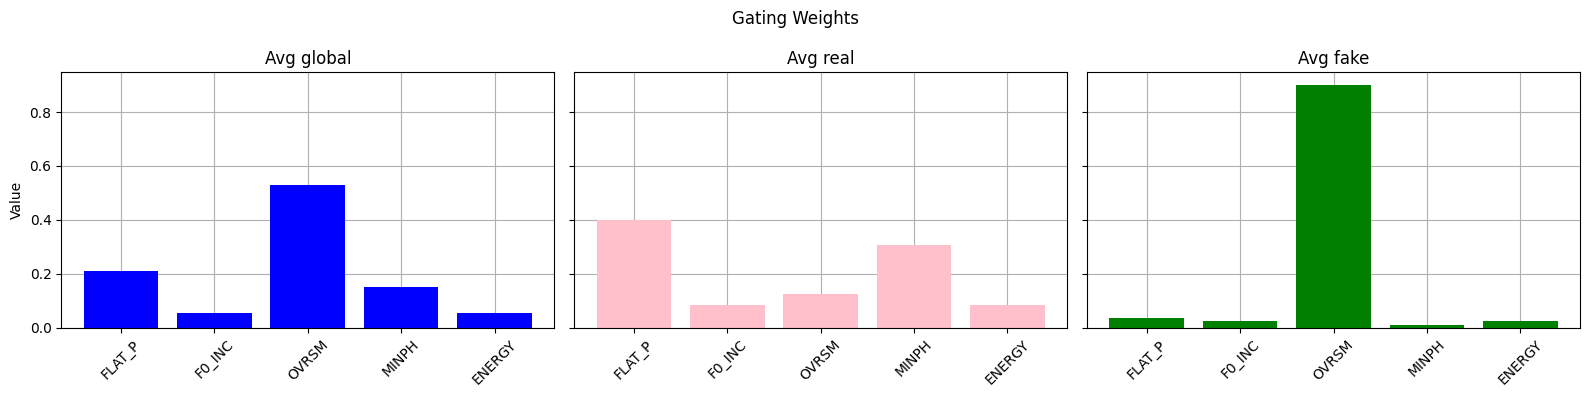

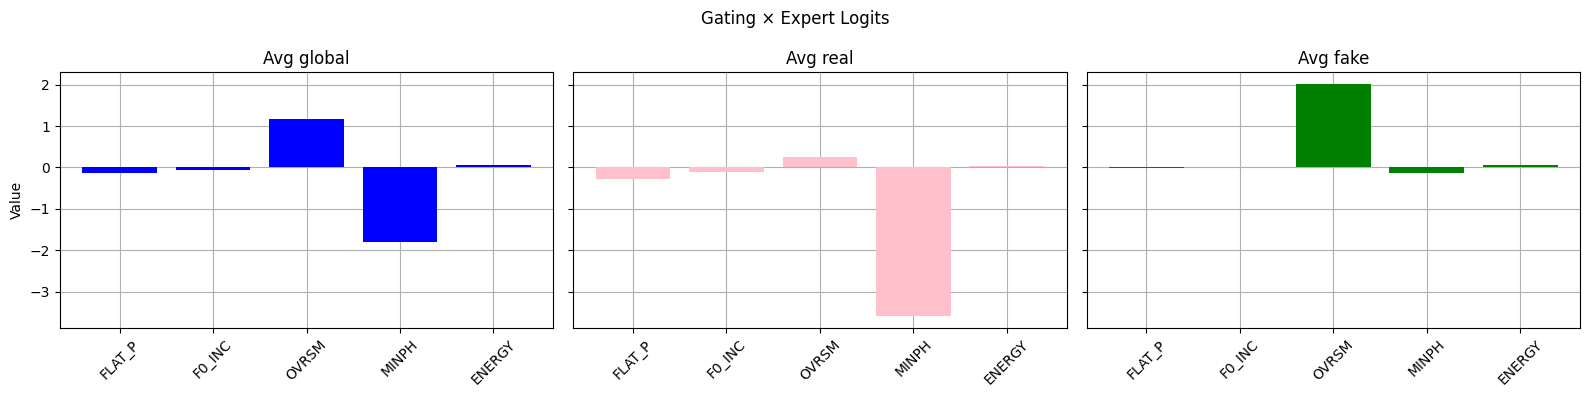

In [25]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/oversmooth"
model_name = "best_frozen_5_exp_new"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)


Individual Experts' Performance:
AUC: 51.07%, EER: 34.70%
AUC: 53.14%, EER: 5.28%
AUC: 49.72%, EER: 50.32%
AUC: 100.00%, EER: 0.00%
AUC: 50.40%, EER: 50.54%

MoE Performance:
AUC: 99.94%, EER: 0.75%
Loaded 1926 samples
Real mean score: -3.6764
Fake mean score: 10.1212



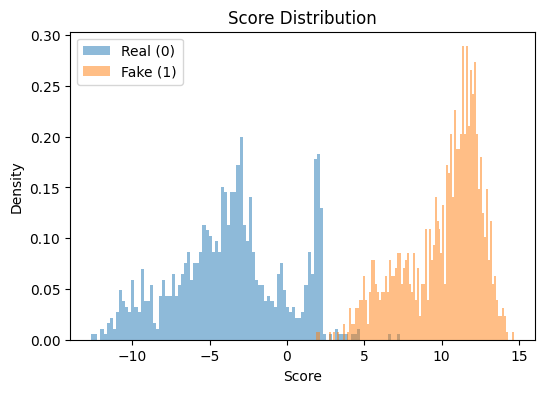

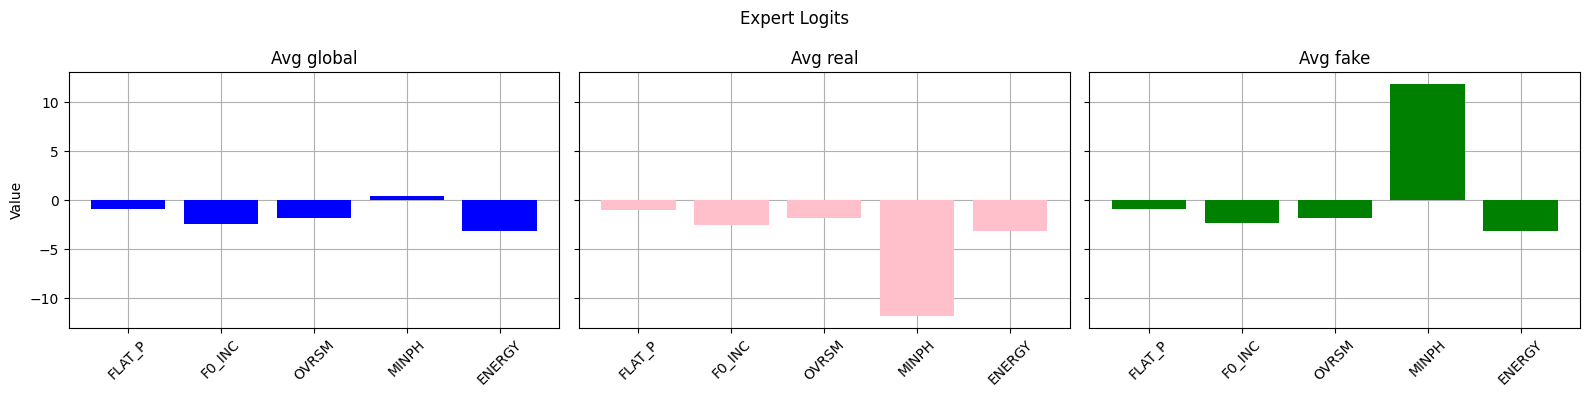

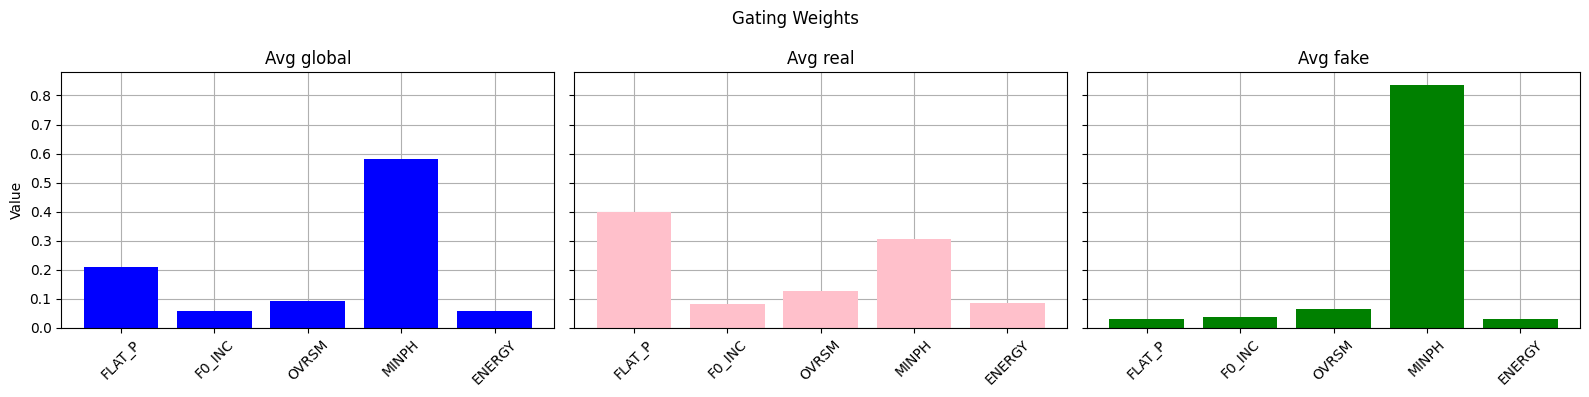

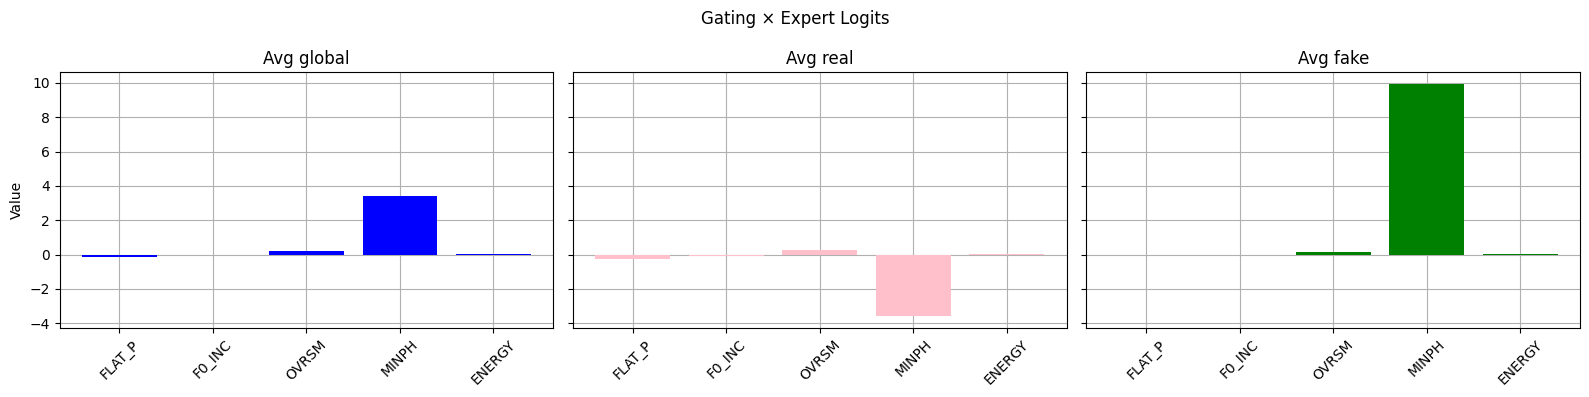

In [26]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/min_phase"
model_name = "best_frozen_5_exp_new"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)


Individual Experts' Performance:
AUC: 51.07%, EER: 34.70%
AUC: 53.14%, EER: 5.28%
AUC: 49.72%, EER: 50.32%
AUC: 50.24%, EER: 51.51%
AUC: 98.69%, EER: 4.53%

MoE Performance:
AUC: 97.85%, EER: 6.47%
Loaded 1926 samples
Real mean score: -3.6764
Fake mean score: 11.0465



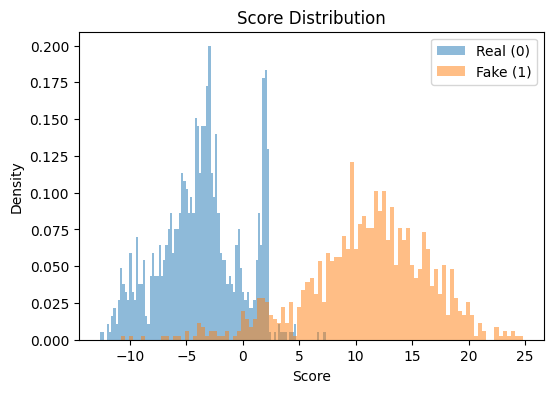

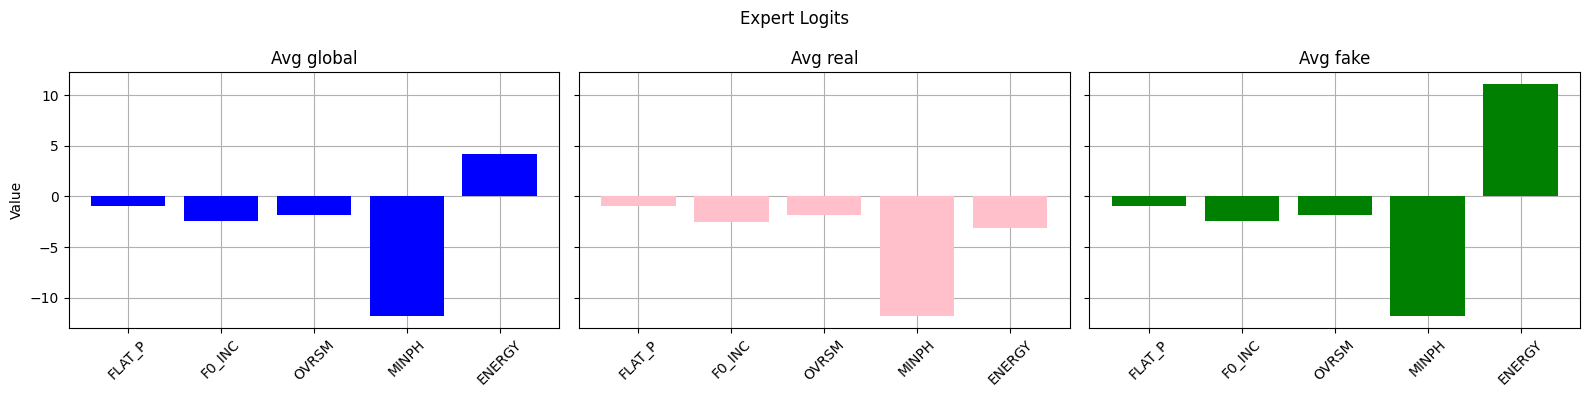

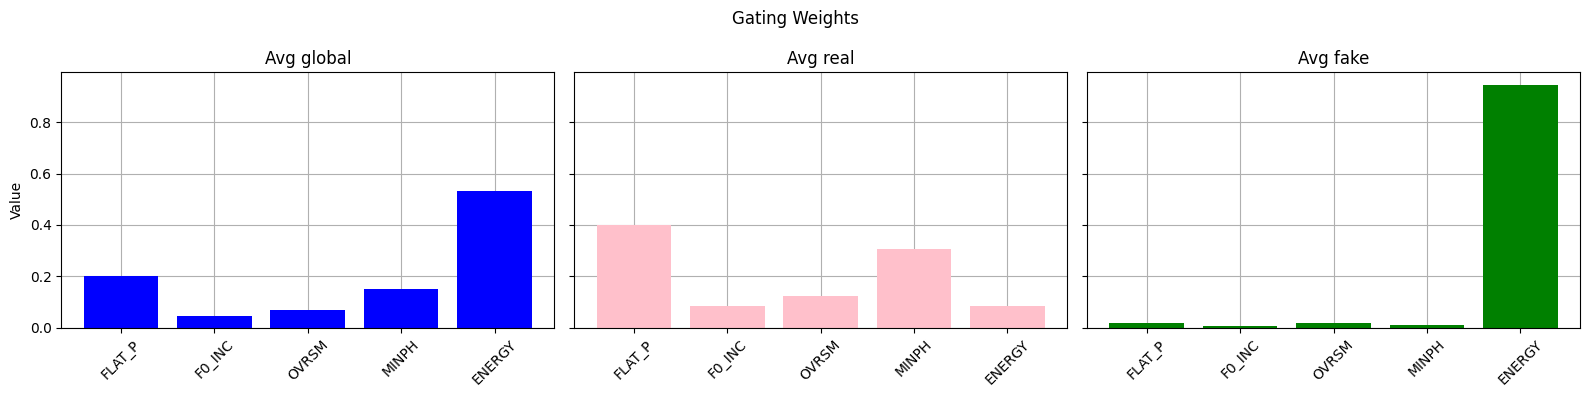

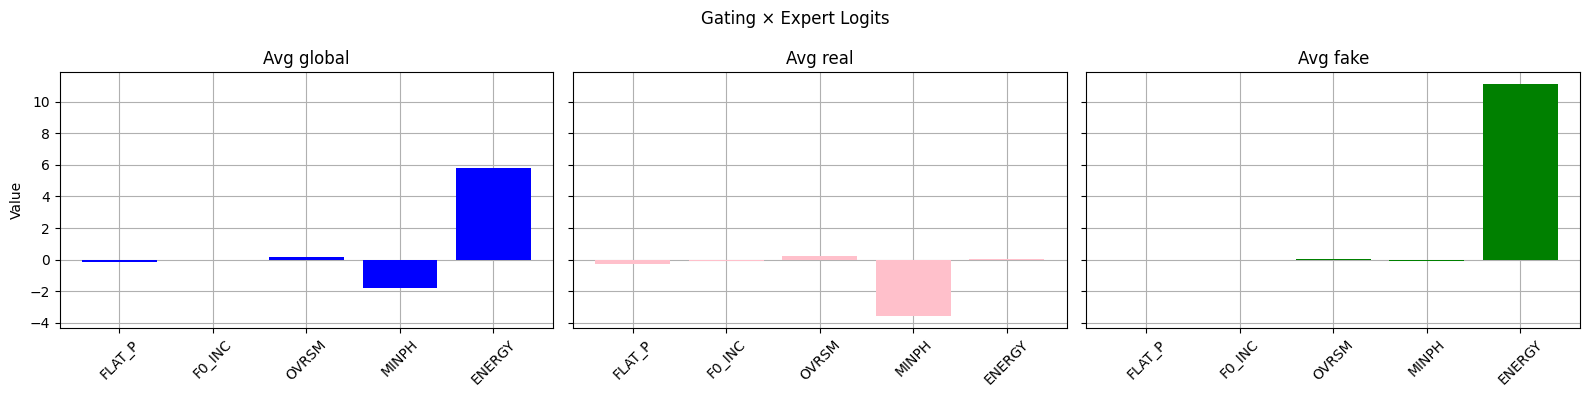

In [27]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/energy"
model_name = "best_frozen_5_exp_new"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

# New trials to address calibration issue

## 1. [Good, but no better than above] STILL SOFTMAX ON WEIGHTS, BUT LEARNED TEMPERATURES FOR SCALING


Individual Experts' Performance:
AUC: 47.59%, EER: 51.90%
AUC: 30.90%, EER: 64.03%
AUC: 52.68%, EER: 50.01%
AUC: 77.23%, EER: 30.35%
AUC: 82.19%, EER: 25.04%

MoE Performance:
AUC: 75.36%, EER: 32.56%
Loaded 19171 samples
Real mean score: -3.3153
Fake mean score: 2.0414



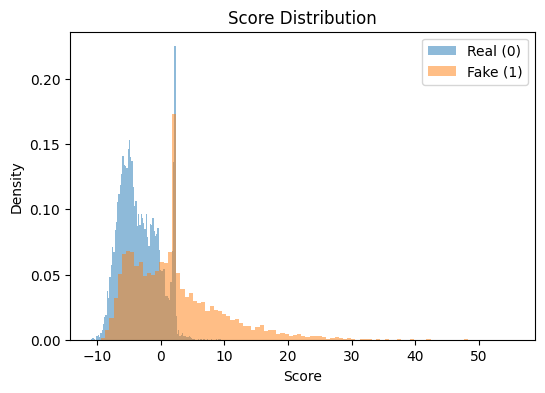

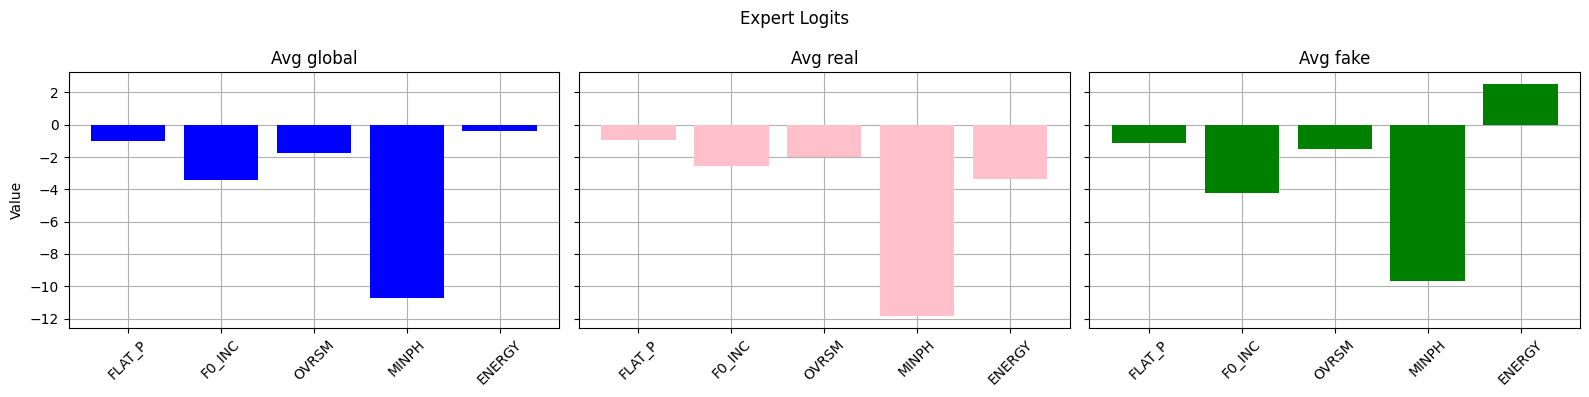

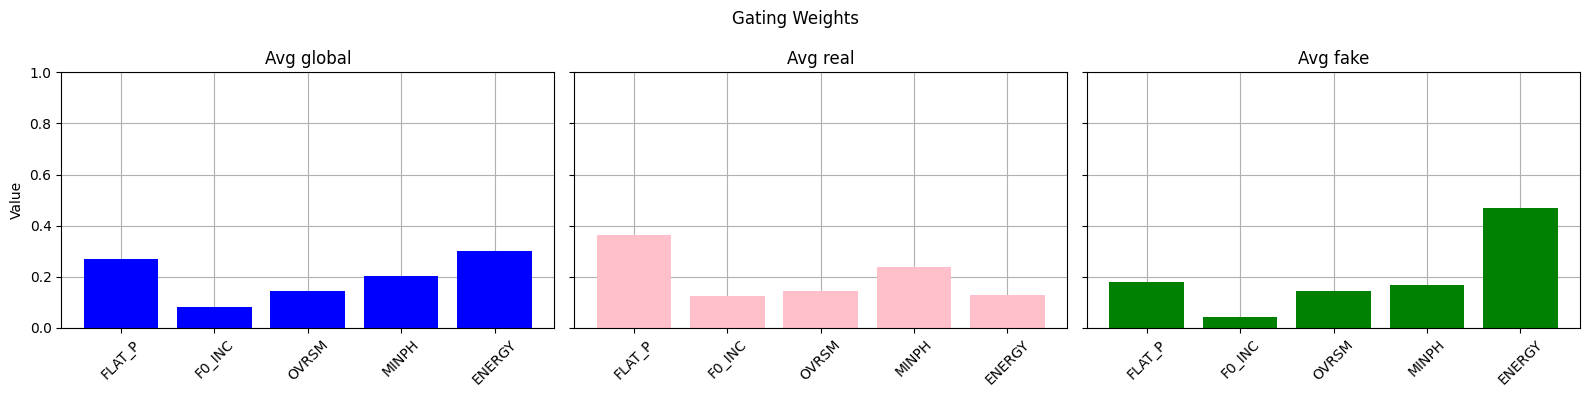

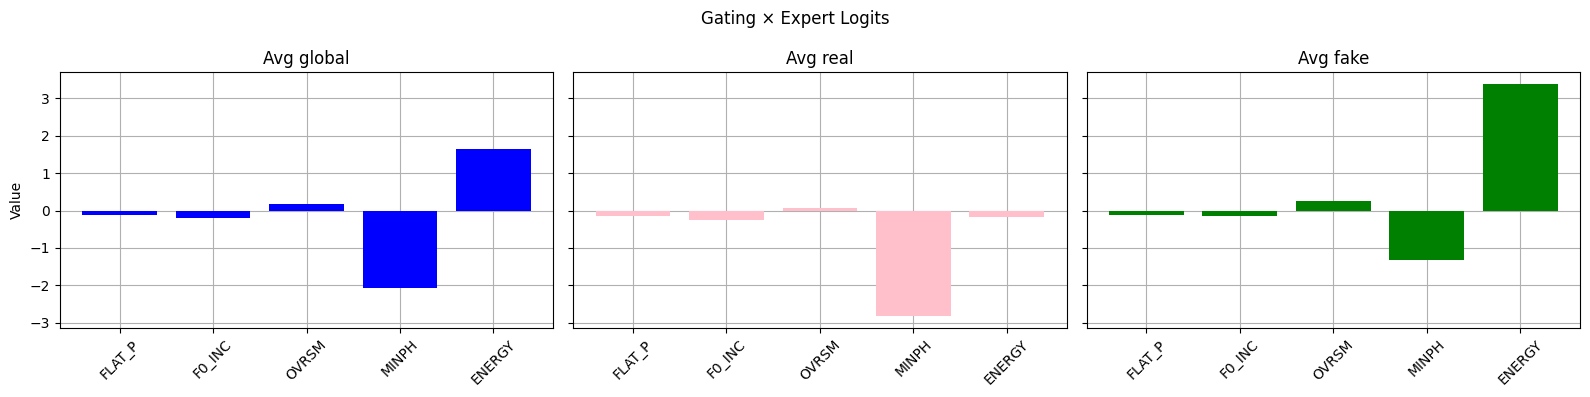

In [11]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/ALL"
model_name = "frozen_5_exp_new_temp"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

#### Per generator (praticamente come prima, stessi problemi)

A01

Individual Experts' Performance:
AUC: 72.92%, EER: 31.99%
AUC: 32.78%, EER: 62.91%
AUC: 79.52%, EER: 30.07%
AUC: 73.13%, EER: 33.37%
AUC: 79.96%, EER: 25.29%

MoE Performance:
AUC: 84.41%, EER: 23.17%
Loaded 1898 samples
Real mean score: -3.4430
Fake mean score: 0.5971



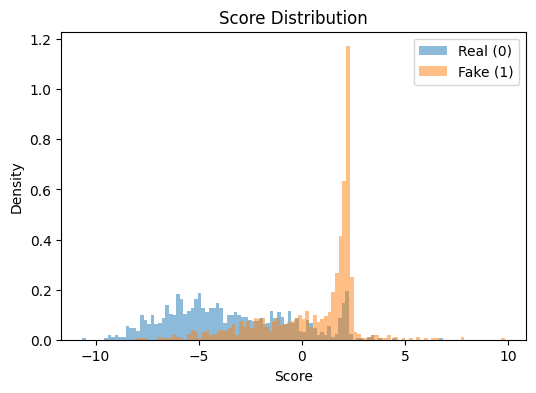

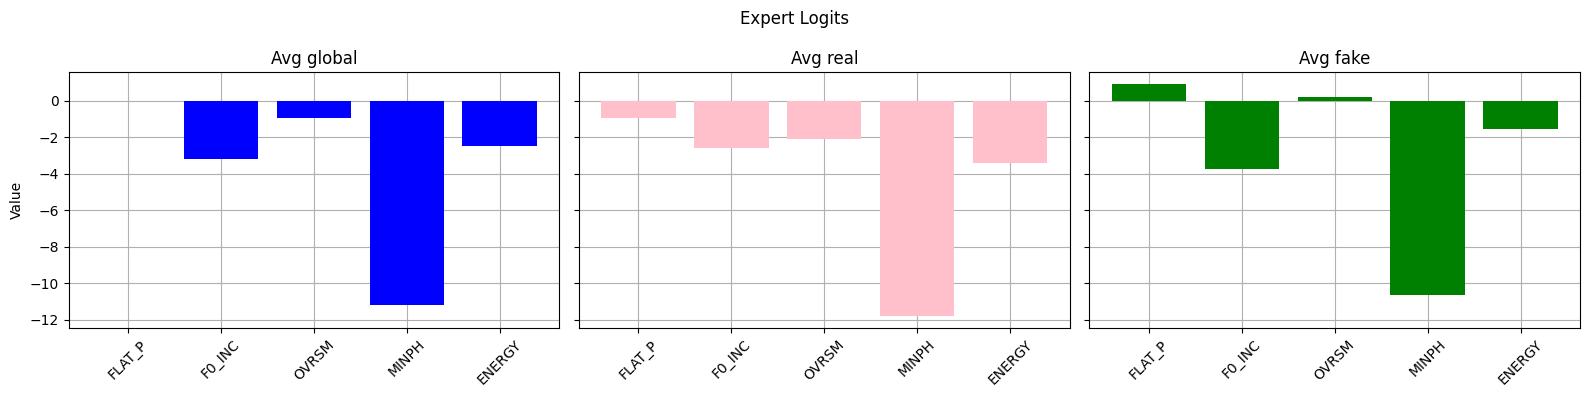

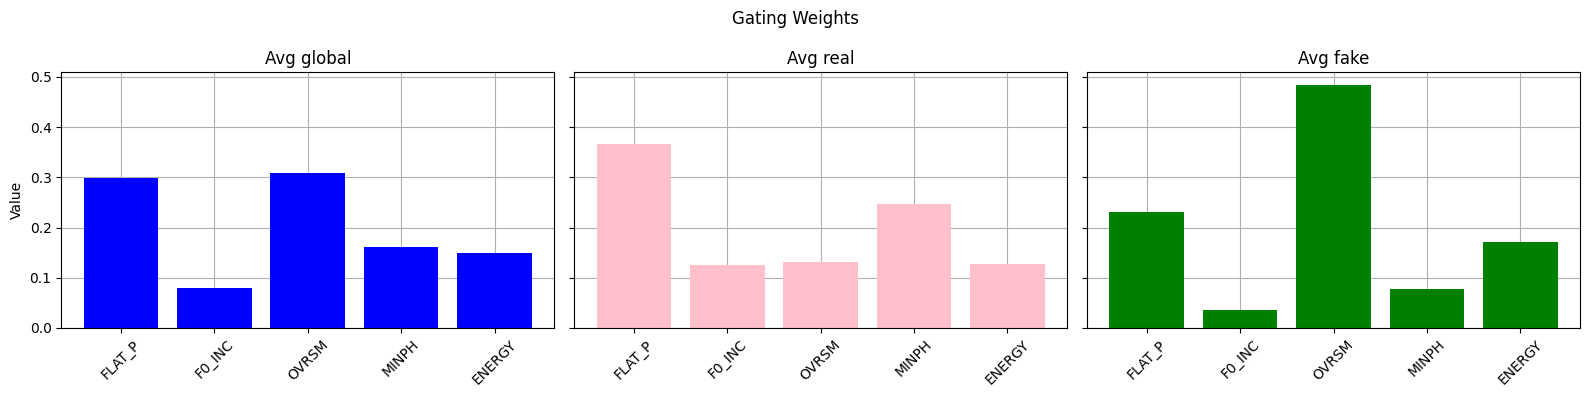

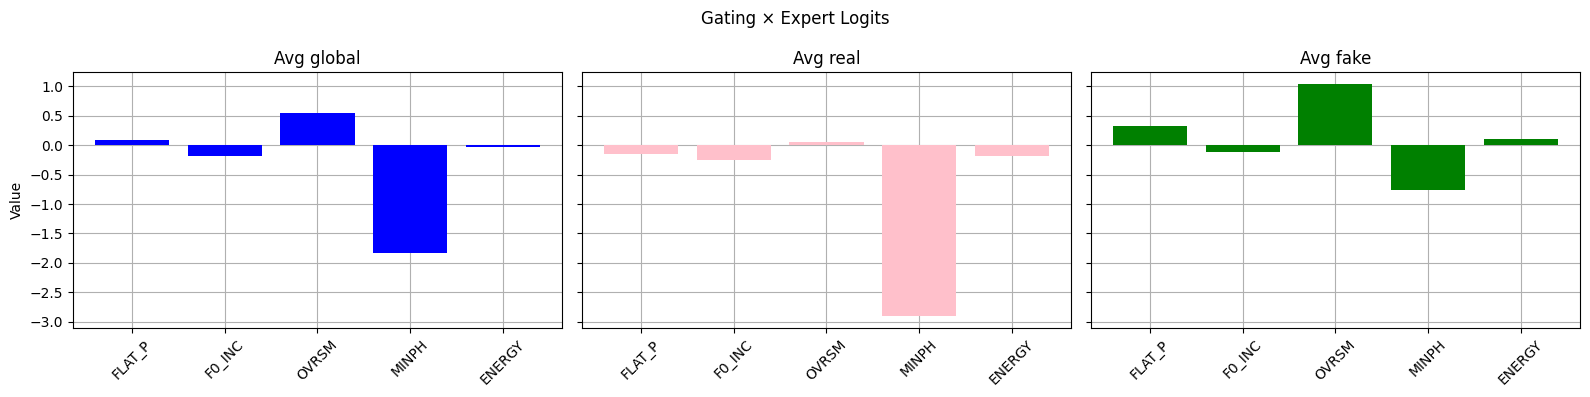

-----------------------------------
A02

Individual Experts' Performance:
AUC: 31.26%, EER: 63.02%
AUC: 17.31%, EER: 73.75%
AUC: 66.08%, EER: 39.43%
AUC: 72.41%, EER: 34.75%
AUC: 71.92%, EER: 32.20%

MoE Performance:
AUC: 67.38%, EER: 39.11%
Loaded 1926 samples
Real mean score: -3.4430
Fake mean score: -0.0856



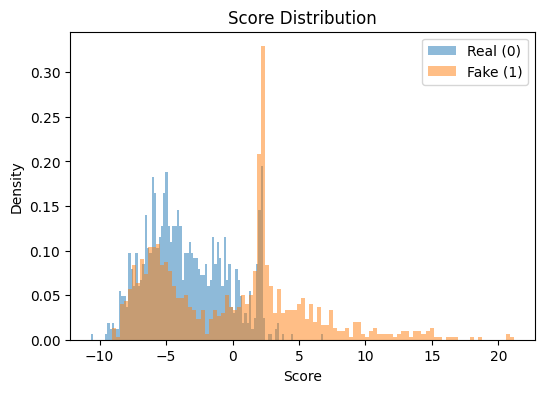

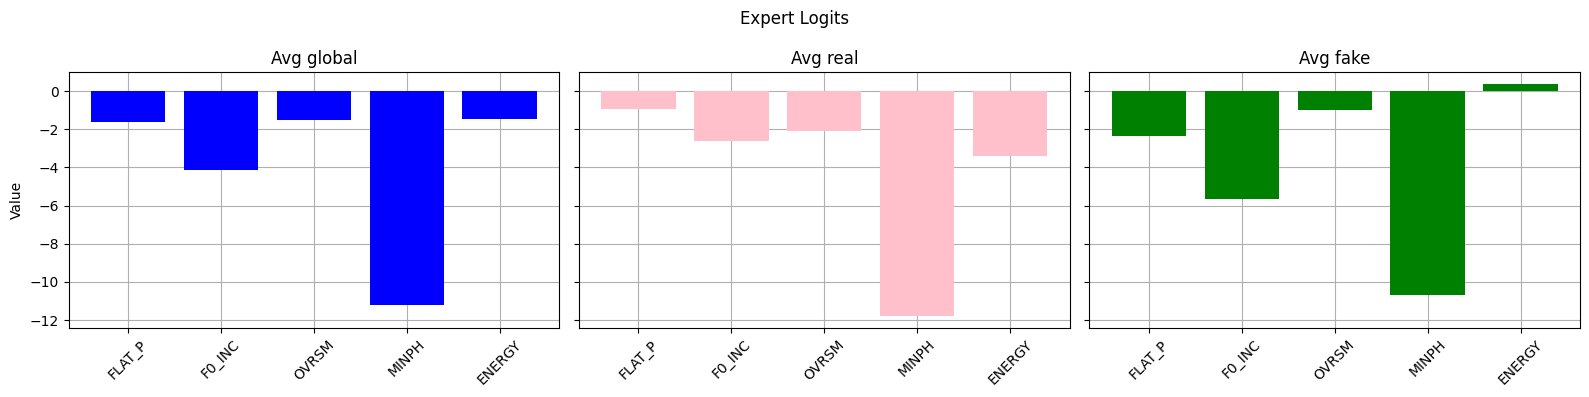

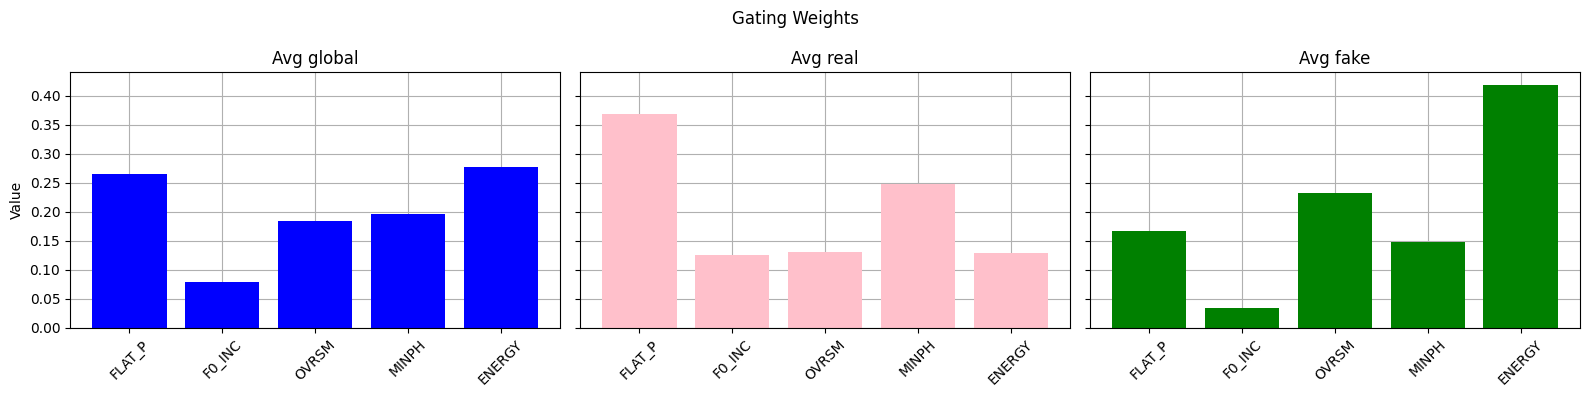

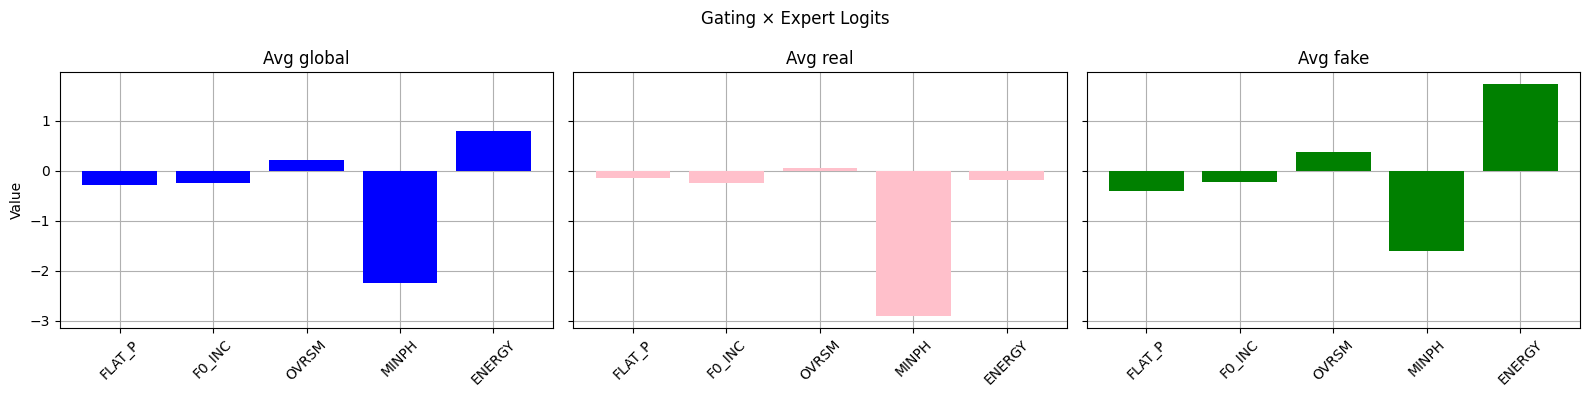

-----------------------------------
A03

Individual Experts' Performance:
AUC: 42.46%, EER: 56.11%
AUC: 22.00%, EER: 69.71%
AUC: 63.72%, EER: 40.60%
AUC: 88.08%, EER: 19.98%
AUC: 96.54%, EER: 9.14%

MoE Performance:
AUC: 80.44%, EER: 26.99%
Loaded 1931 samples
Real mean score: -3.4430
Fake mean score: 1.1644



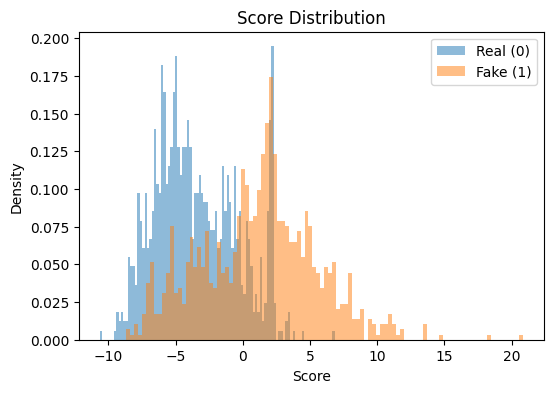

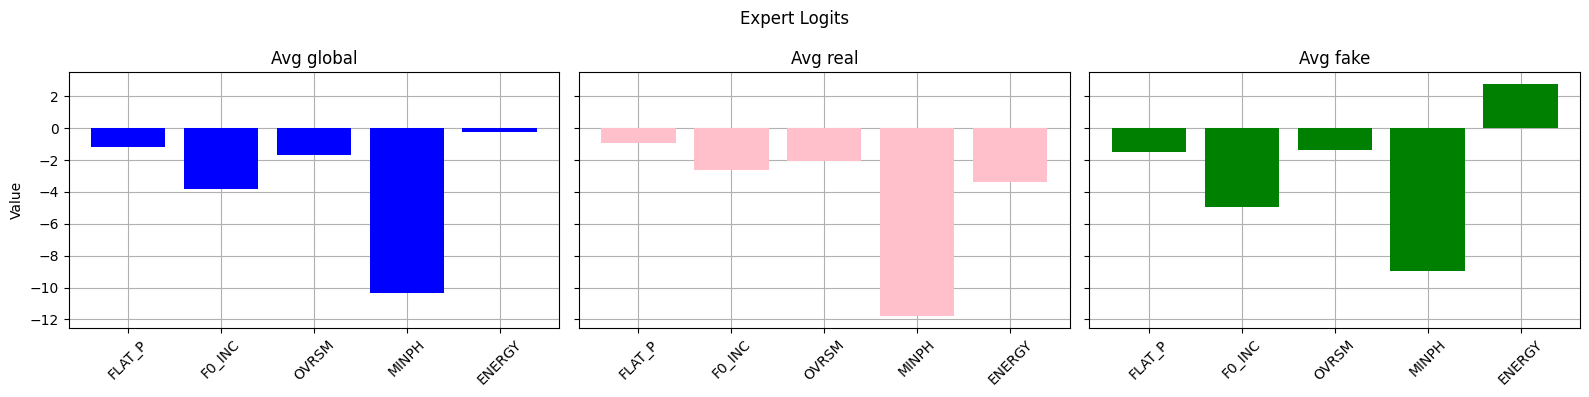

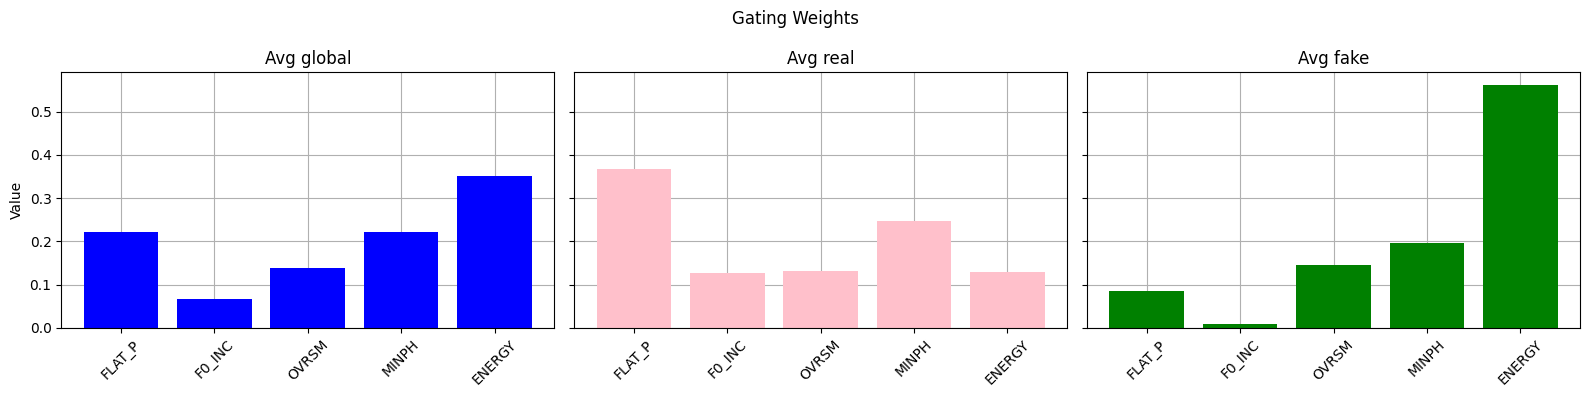

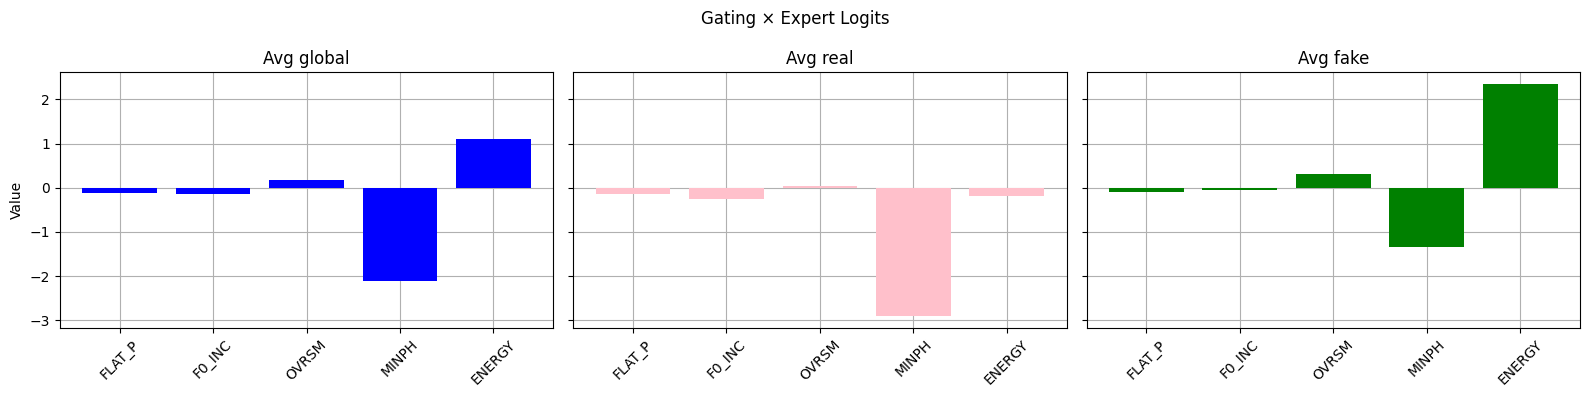

-----------------------------------
A04

Individual Experts' Performance:
AUC: 63.55%, EER: 40.70%
AUC: 72.36%, EER: 34.43%
AUC: 41.74%, EER: 57.60%
AUC: 41.26%, EER: 56.11%
AUC: 89.75%, EER: 19.34%

MoE Performance:
AUC: 90.18%, EER: 21.04%
Loaded 1880 samples
Real mean score: -3.4430
Fake mean score: 6.0079



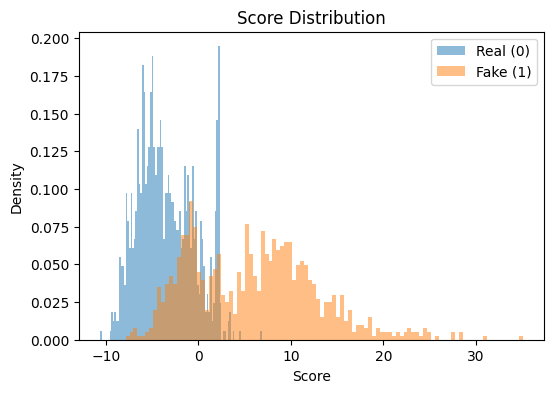

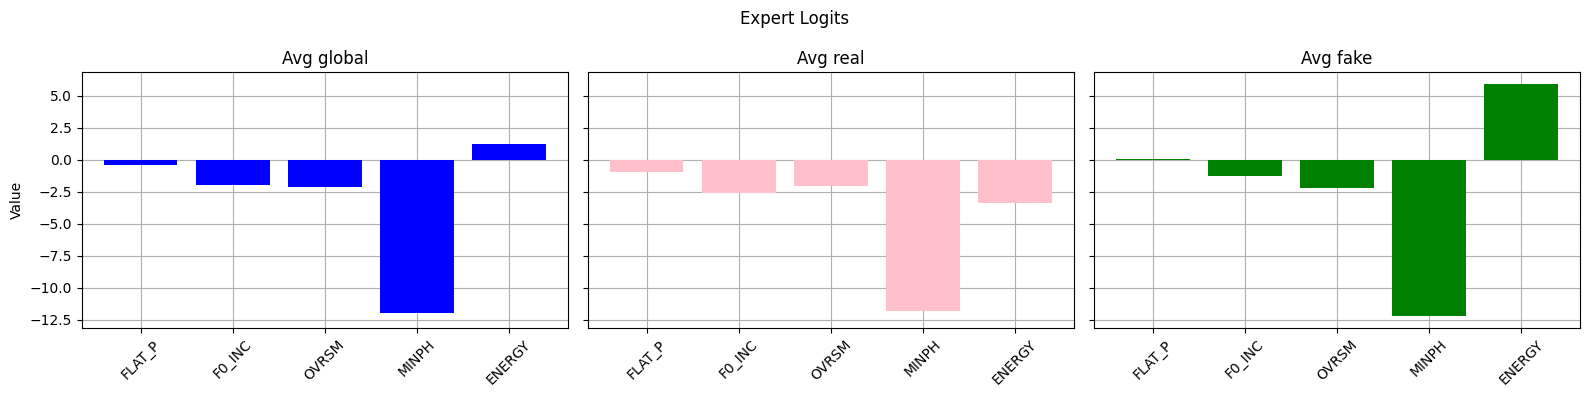

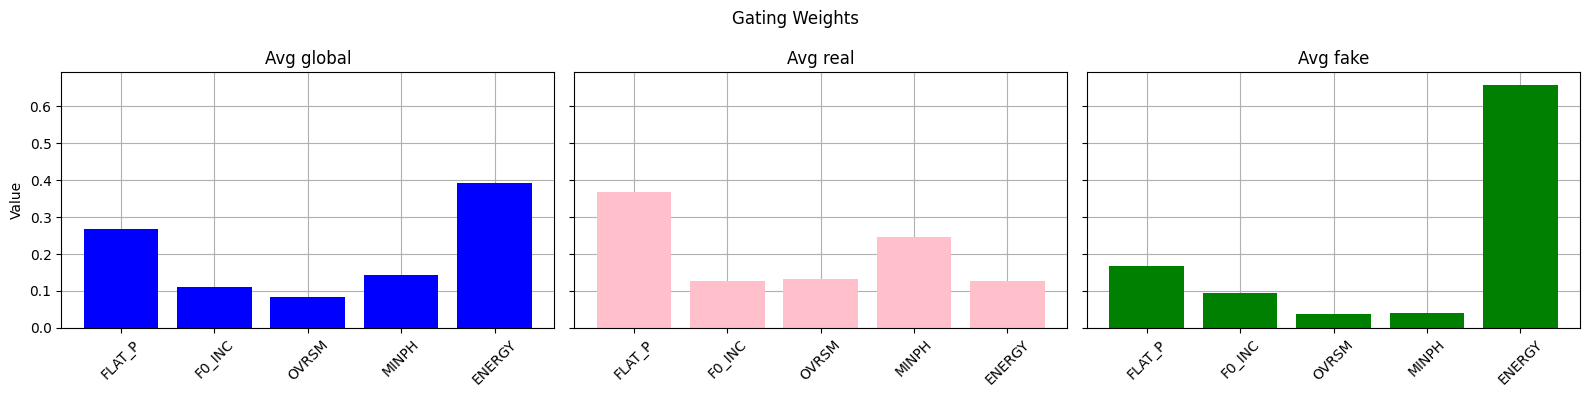

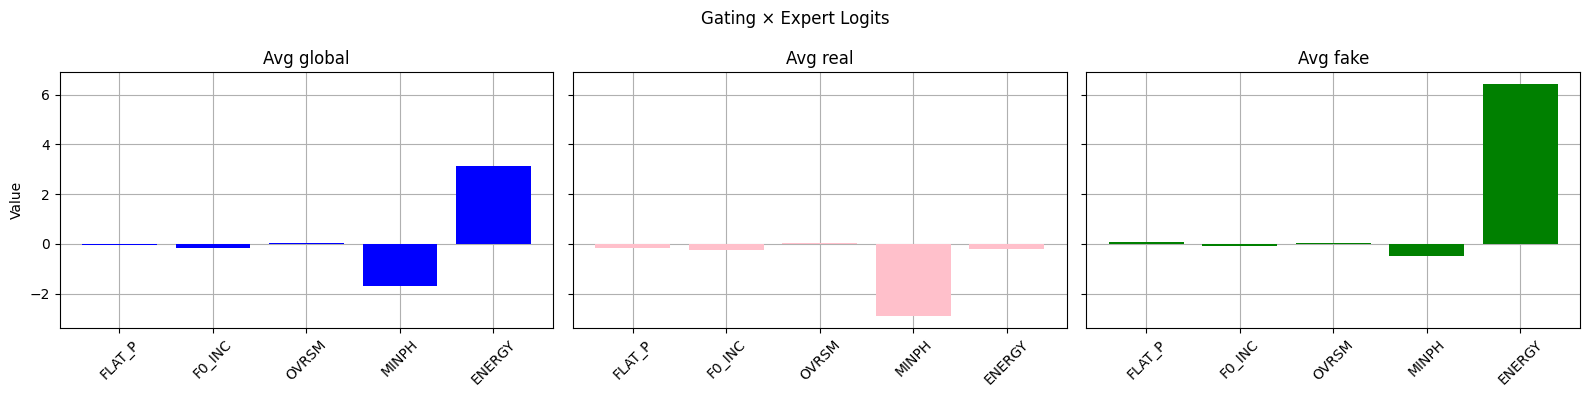

-----------------------------------
A07

Individual Experts' Performance:
AUC: 31.75%, EER: 63.55%
AUC: 13.62%, EER: 76.41%
AUC: 38.91%, EER: 58.77%
AUC: 83.97%, EER: 24.02%
AUC: 63.86%, EER: 38.79%

MoE Performance:
AUC: 43.44%, EER: 56.75%
Loaded 1940 samples
Real mean score: -3.4430
Fake mean score: -4.0588



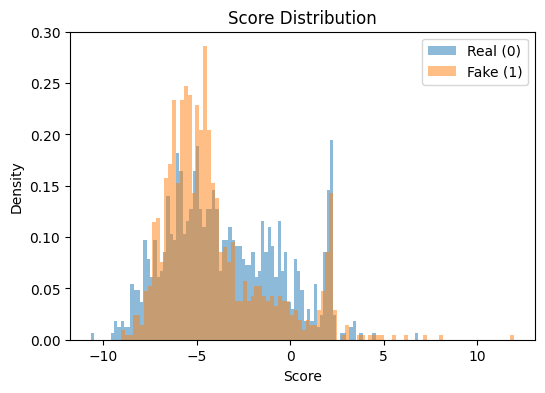

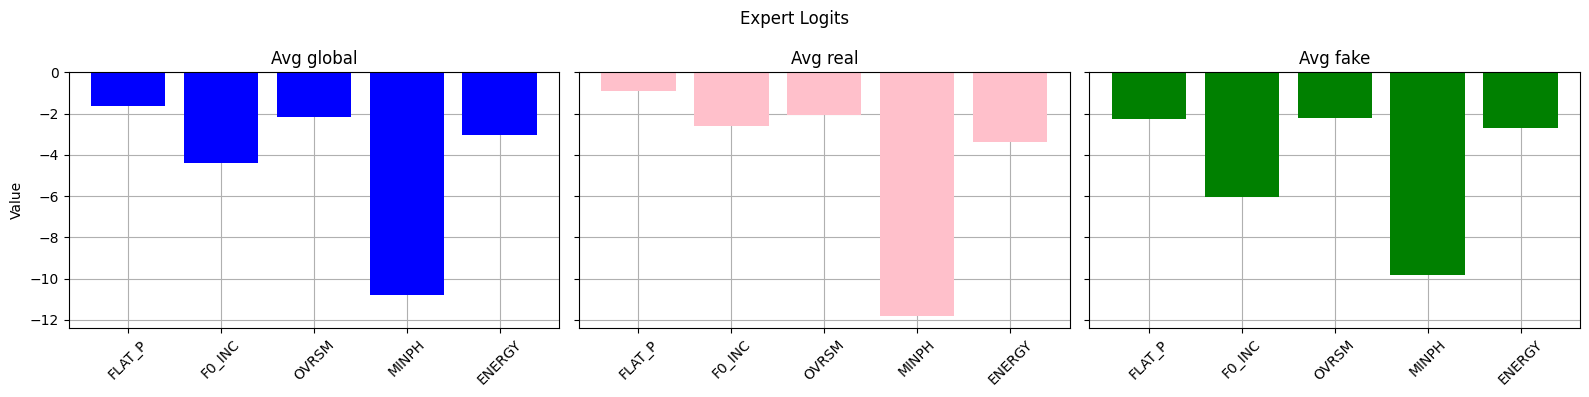

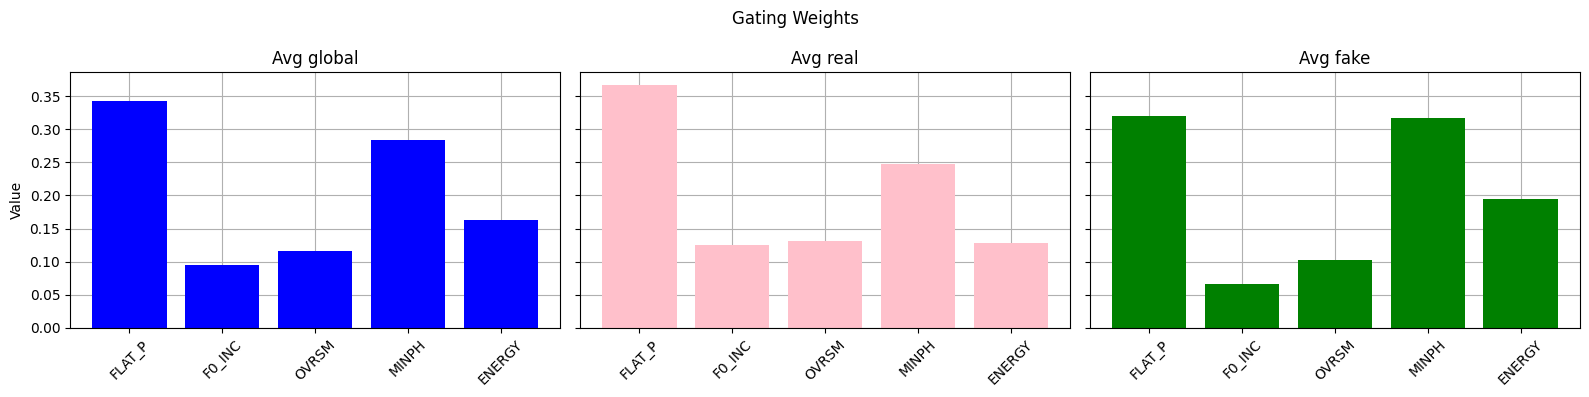

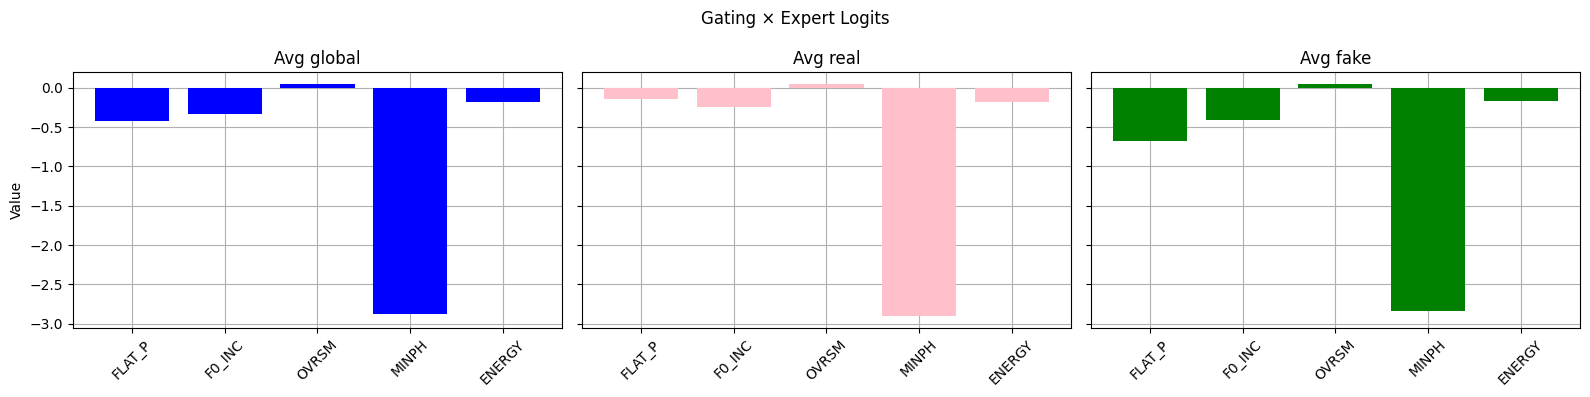

-----------------------------------
A08

Individual Experts' Performance:
AUC: 63.52%, EER: 39.64%
AUC: 26.31%, EER: 67.91%
AUC: 54.58%, EER: 48.78%
AUC: 97.17%, EER: 8.82%
AUC: 96.96%, EER: 8.40%

MoE Performance:
AUC: 78.82%, EER: 29.22%
Loaded 1933 samples
Real mean score: -3.4430
Fake mean score: 1.5991



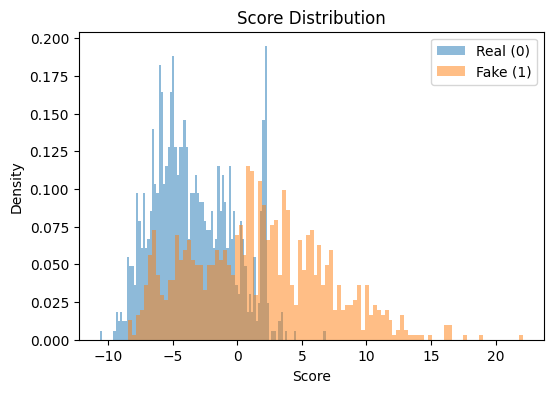

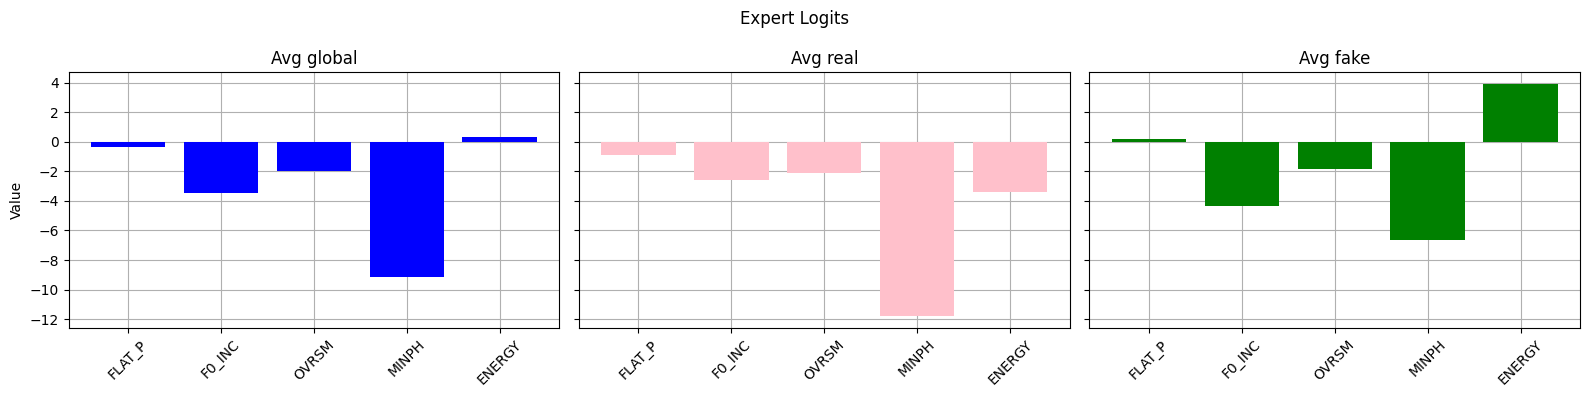

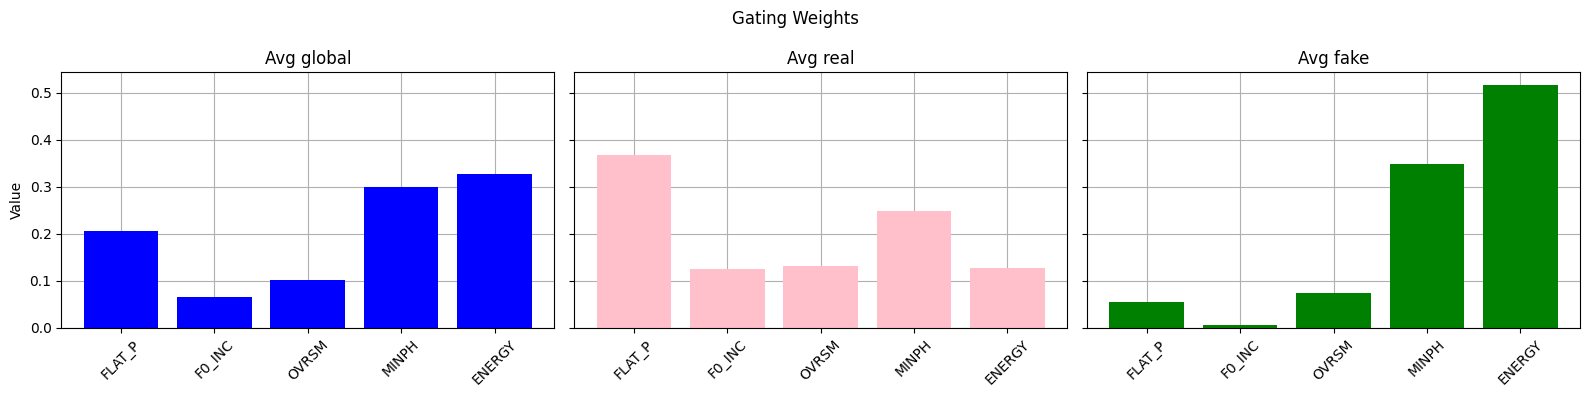

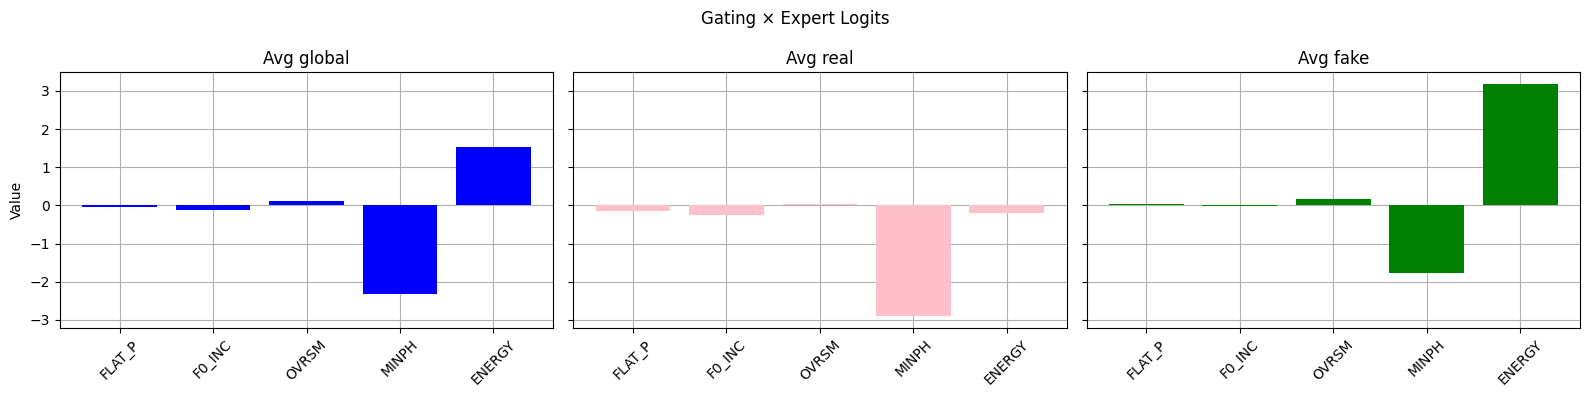

-----------------------------------
A09

Individual Experts' Performance:
AUC: 22.77%, EER: 70.46%
AUC: 15.13%, EER: 75.77%
AUC: 74.59%, EER: 33.90%
AUC: 98.97%, EER: 4.68%
AUC: 97.23%, EER: 8.61%

MoE Performance:
AUC: 89.68%, EER: 15.94%
Loaded 1939 samples
Real mean score: -3.4430
Fake mean score: 9.7951



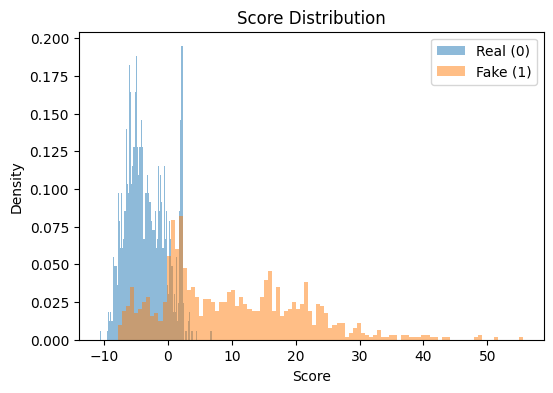

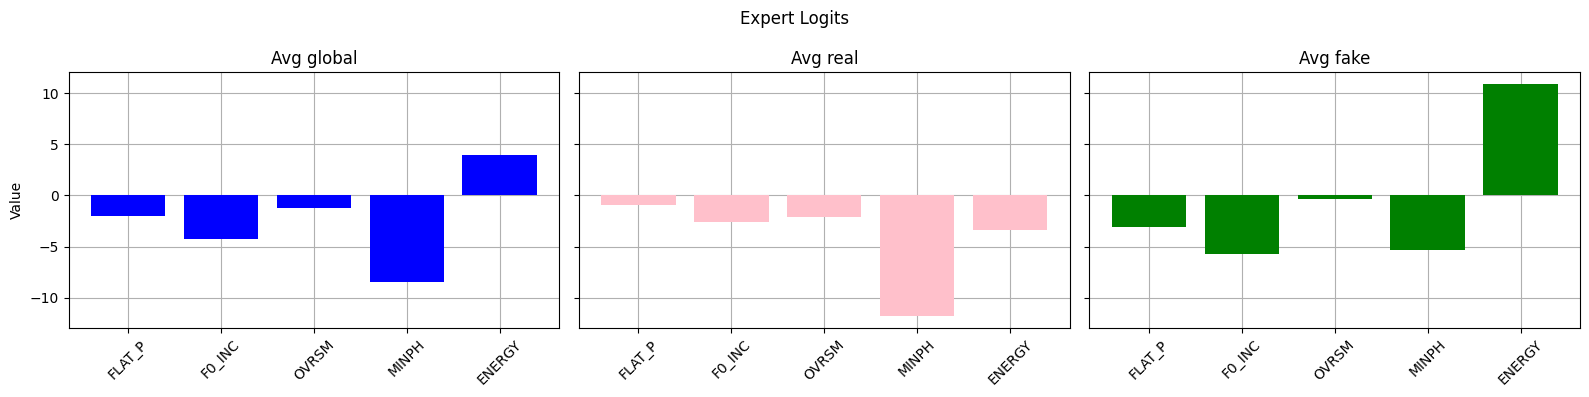

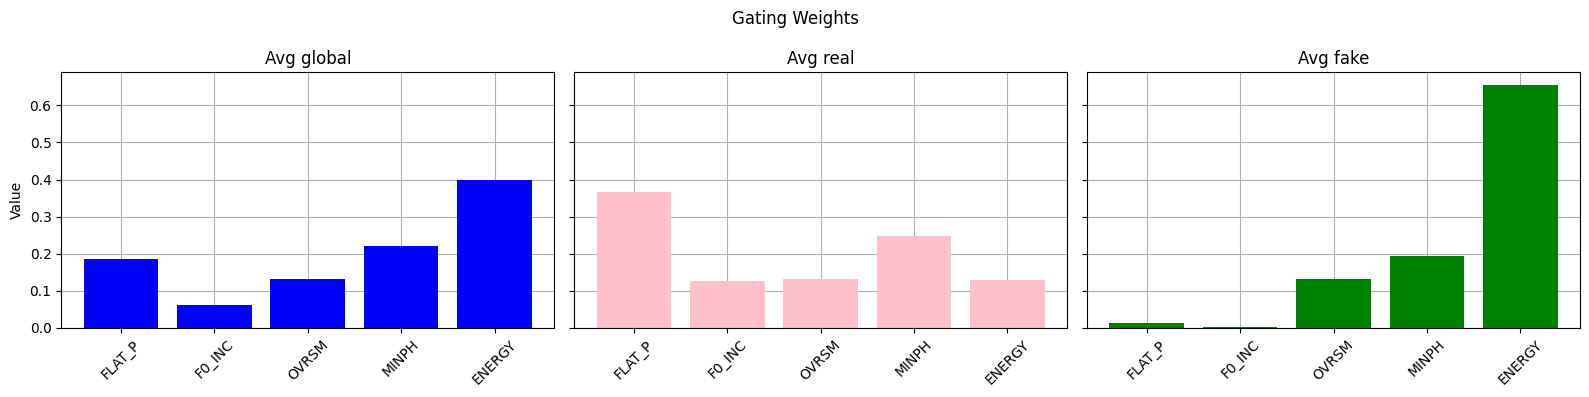

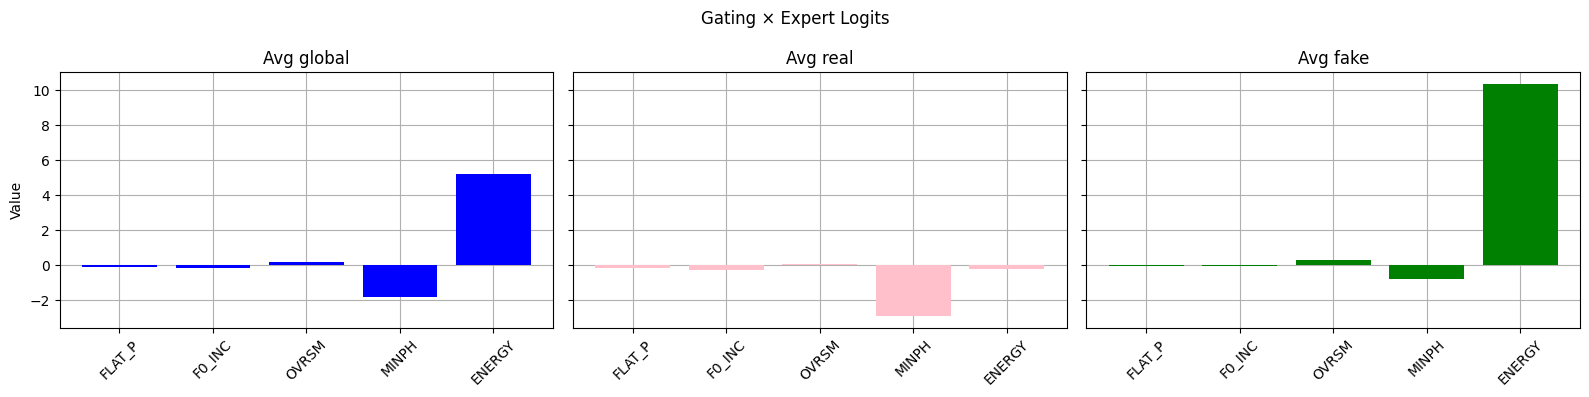

-----------------------------------
A10

Individual Experts' Performance:
AUC: 50.32%, EER: 48.99%
AUC: 38.14%, EER: 58.24%
AUC: 41.40%, EER: 57.60%
AUC: 68.30%, EER: 36.03%
AUC: 58.14%, EER: 43.89%

MoE Performance:
AUC: 53.89%, EER: 47.40%
Loaded 1898 samples
Real mean score: -3.4430
Fake mean score: -3.1152



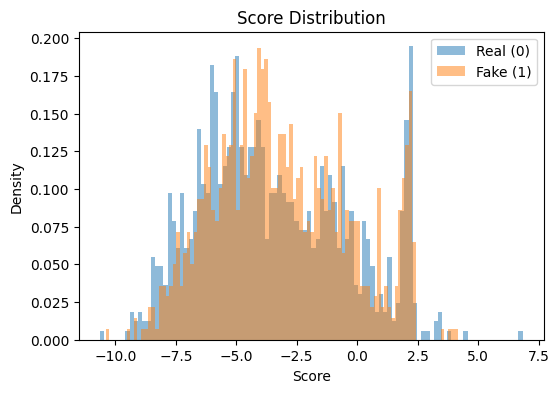

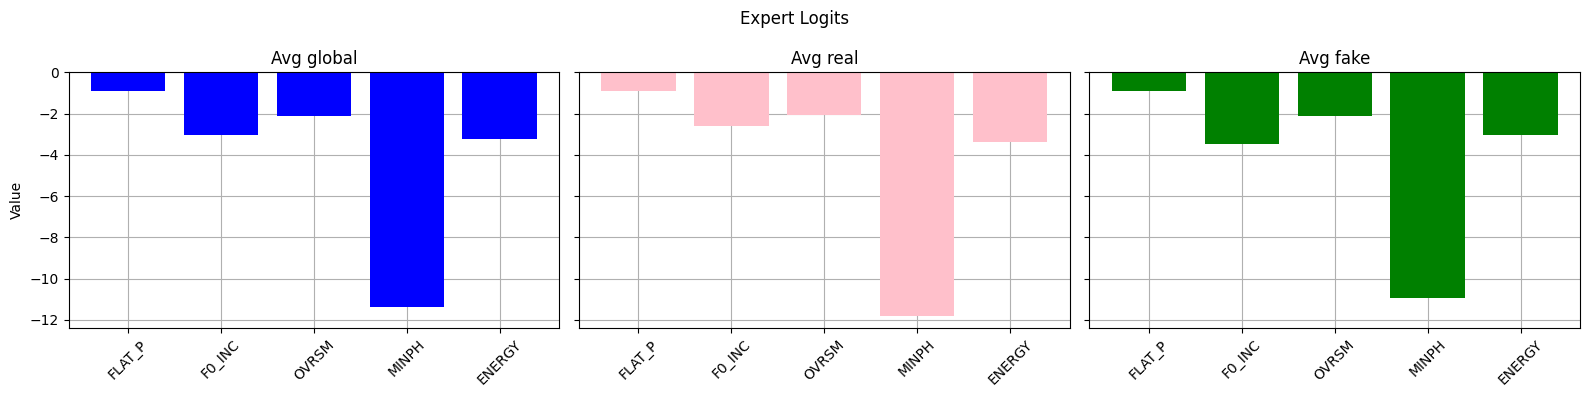

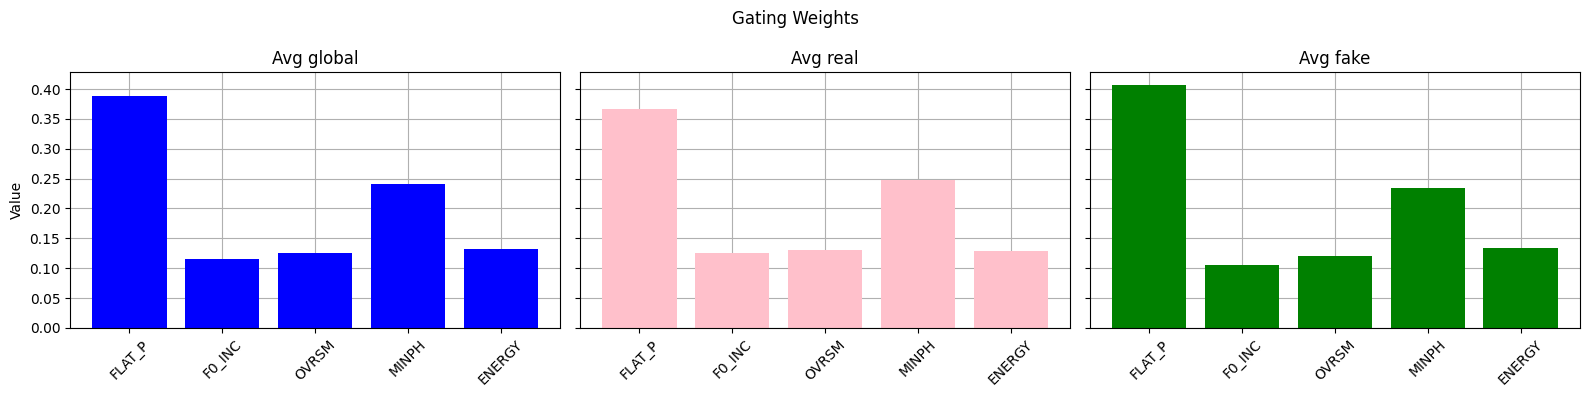

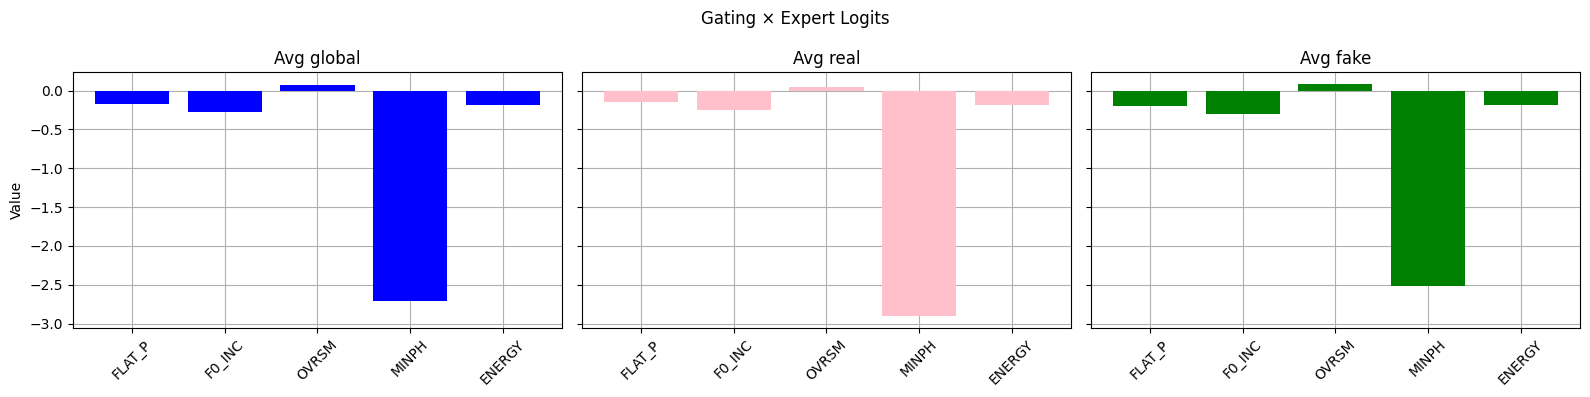

-----------------------------------
A11

Individual Experts' Performance:
AUC: 46.13%, EER: 52.39%
AUC: 35.13%, EER: 59.19%
AUC: 45.27%, EER: 56.11%
AUC: 78.28%, EER: 29.33%
AUC: 82.28%, EER: 25.19%

MoE Performance:
AUC: 82.20%, EER: 28.06%
Loaded 1902 samples
Real mean score: -3.4430
Fake mean score: 1.8878



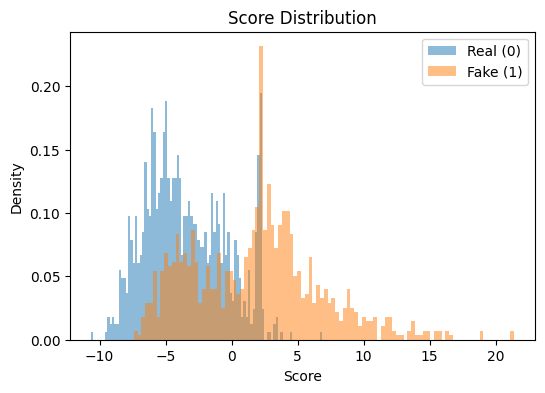

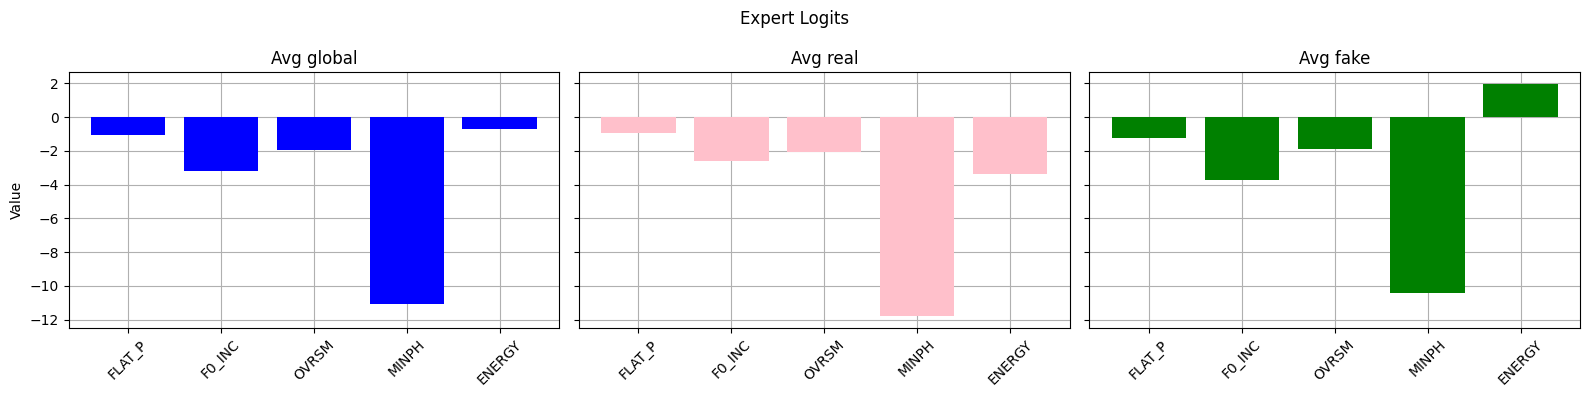

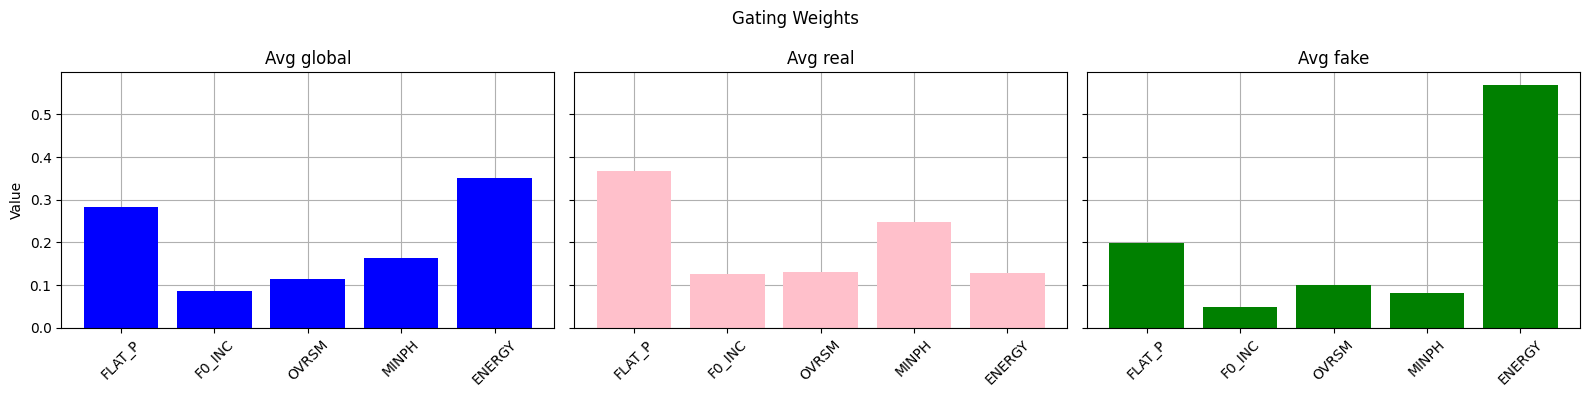

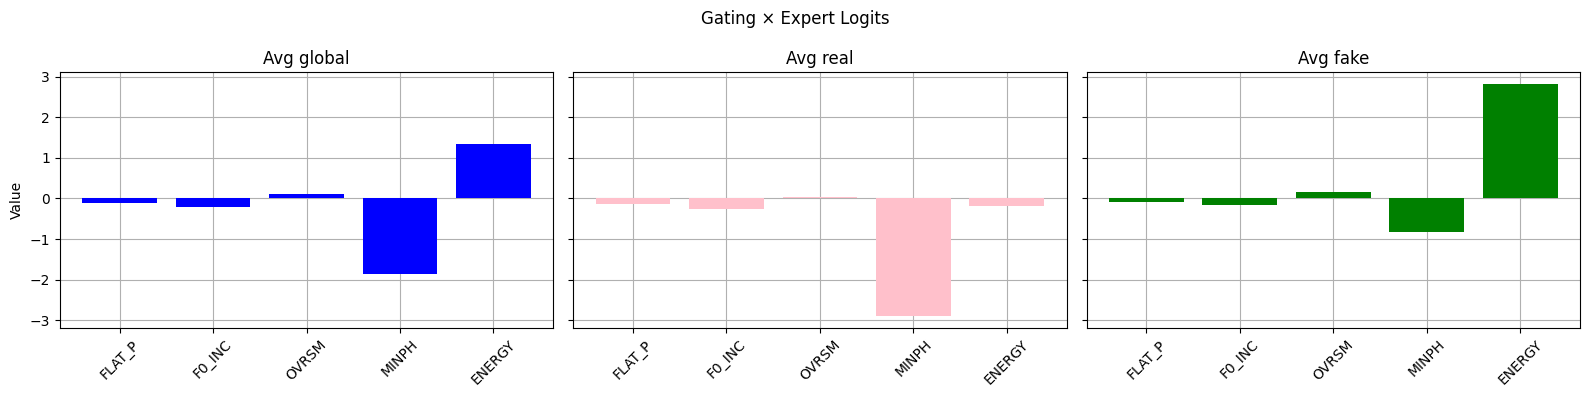

-----------------------------------
A12

Individual Experts' Performance:
AUC: 52.39%, EER: 48.14%
AUC: 39.70%, EER: 56.64%
AUC: 39.32%, EER: 58.45%
AUC: 59.22%, EER: 43.78%
AUC: 86.44%, EER: 18.92%

MoE Performance:
AUC: 87.43%, EER: 20.94%
Loaded 1876 samples
Real mean score: -3.4430
Fake mean score: 6.5185



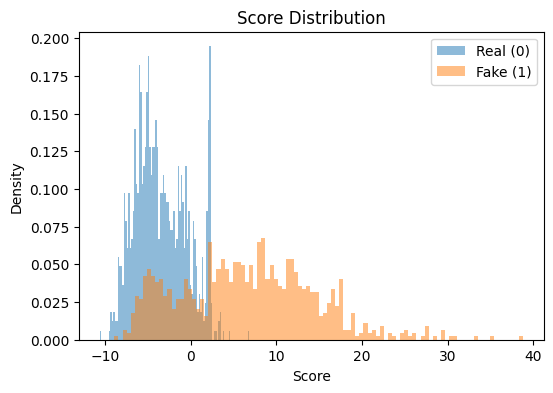

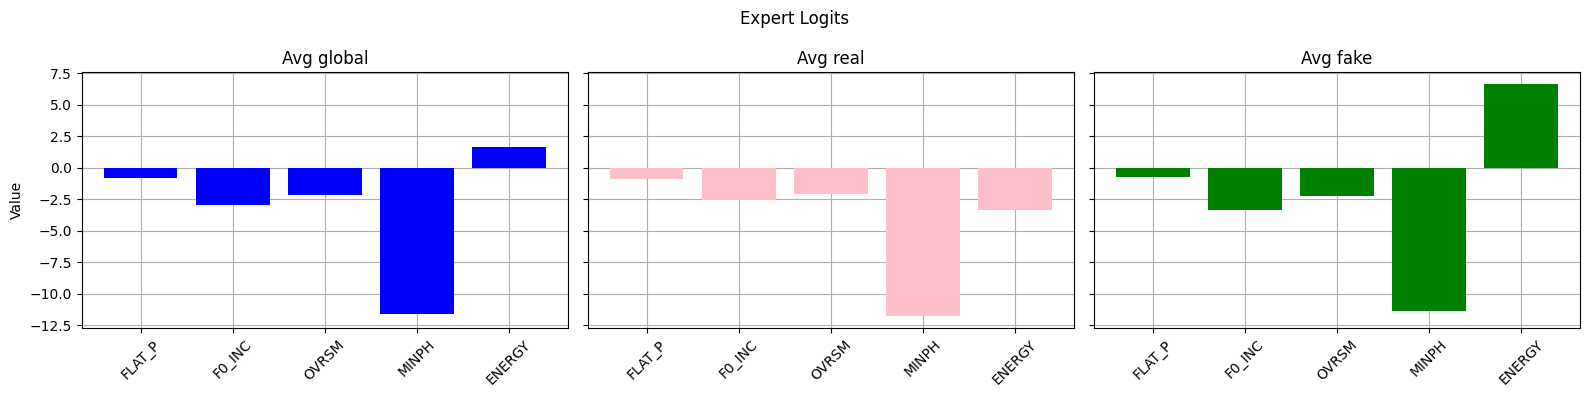

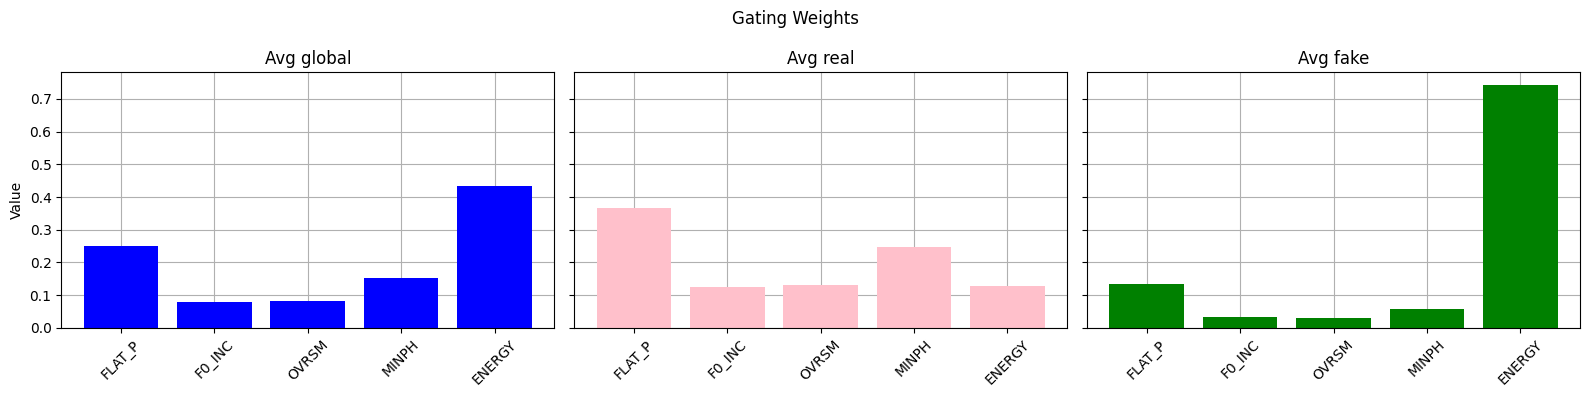

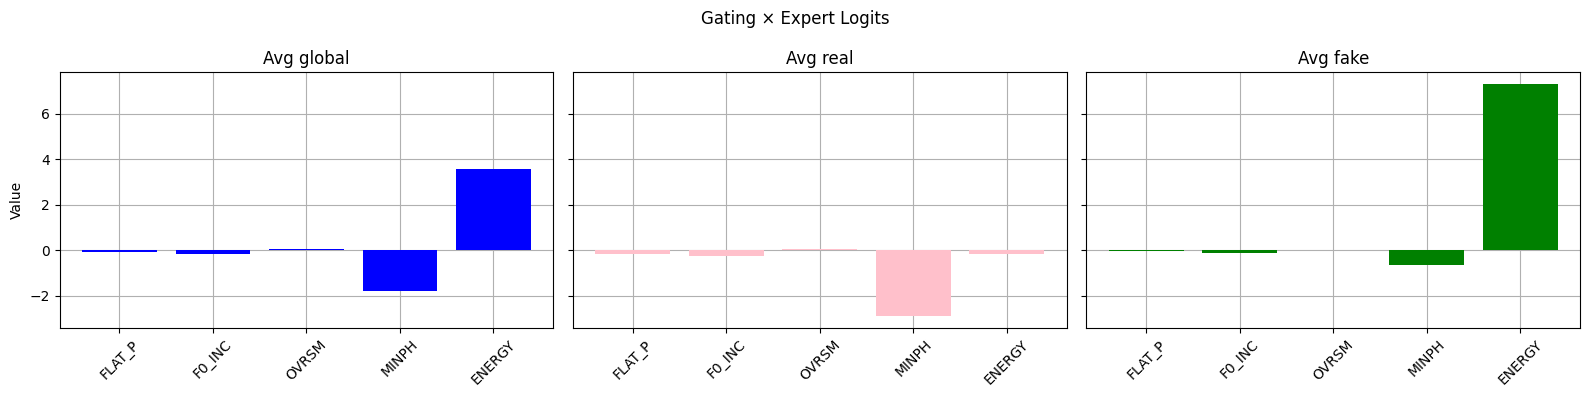

-----------------------------------


In [14]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07',  'A08', 'A09', 'A10', 'A11', 'A12']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/{g}"
    model_name = "frozen_5_exp_new_temp"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True, plot=True)
    print("-----------------------------------")

## 2. [Better than above on overall metrics!] REMOVED SOFTMAX ON WEIGHTS, NO TEMPERATURE


Individual Experts' Performance:
AUC: 47.59%, EER: 51.90%
AUC: 30.90%, EER: 64.03%
AUC: 52.68%, EER: 50.01%
AUC: 77.23%, EER: 30.35%
AUC: 82.19%, EER: 25.04%

MoE Performance:
AUC: 78.52%, EER: 26.36%
Loaded 19171 samples
Real mean score: -72.9831
Fake mean score: 29.5772



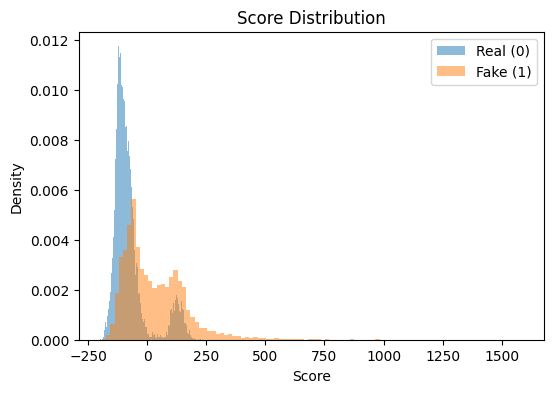

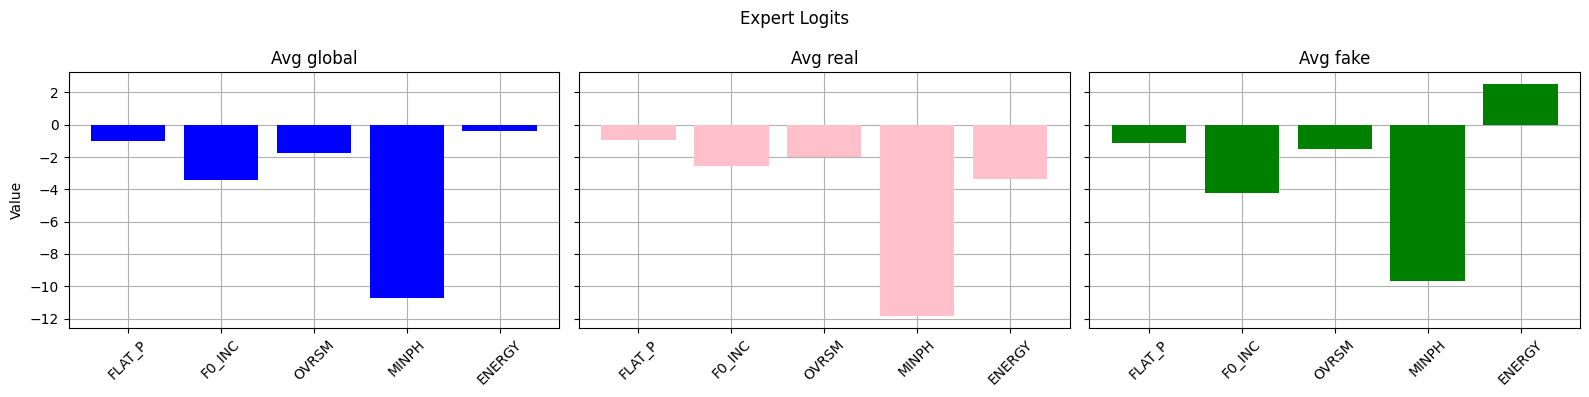

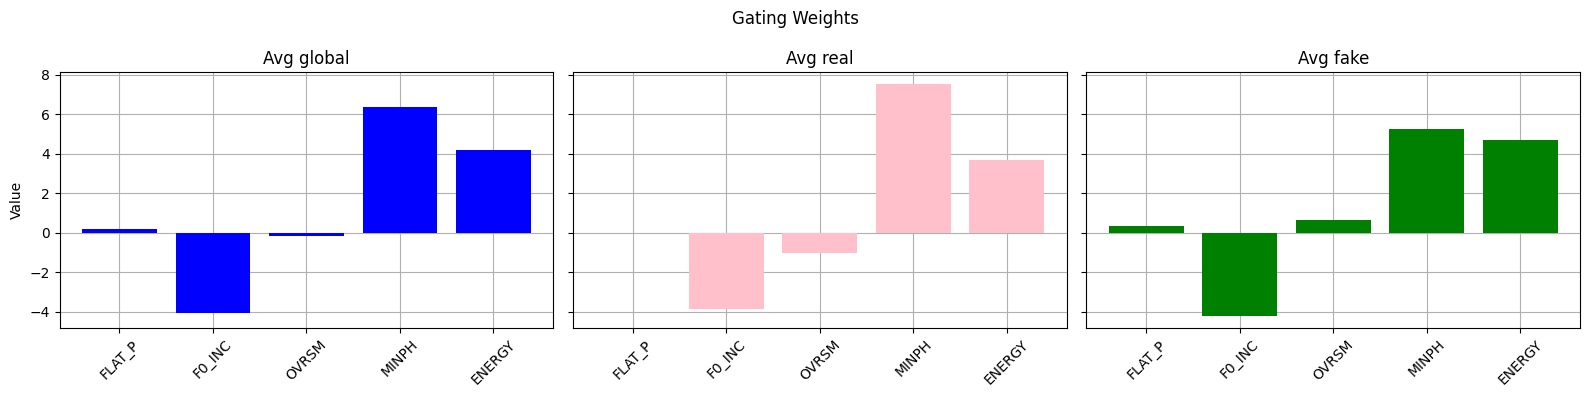

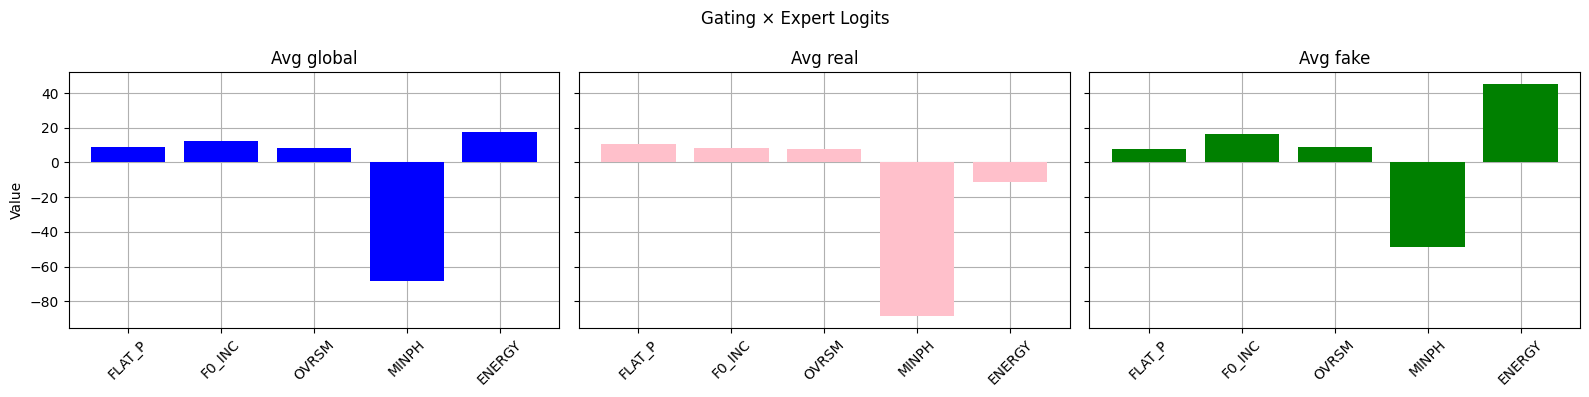

In [17]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/ALL"
model_name = "frozen_5_exp_new_w_unbound"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

### Per generator (better on A07 but same on A10, rest is the same more or less)

A01

Individual Experts' Performance:
AUC: 72.92%, EER: 31.99%
AUC: 32.78%, EER: 62.91%
AUC: 79.52%, EER: 30.07%
AUC: 73.13%, EER: 33.37%
AUC: 79.96%, EER: 25.29%

MoE Performance:
AUC: 86.84%, EER: 20.09%
Loaded 1898 samples
Real mean score: -76.7023
Fake mean score: 45.6902



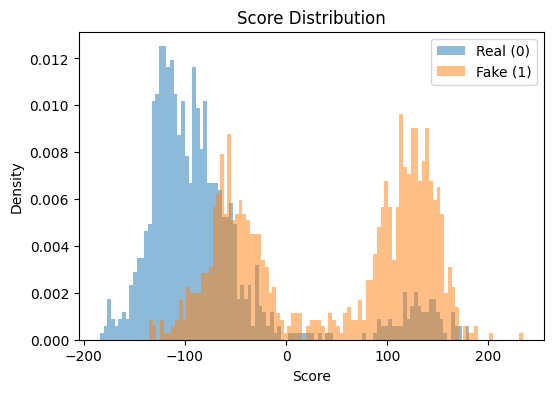

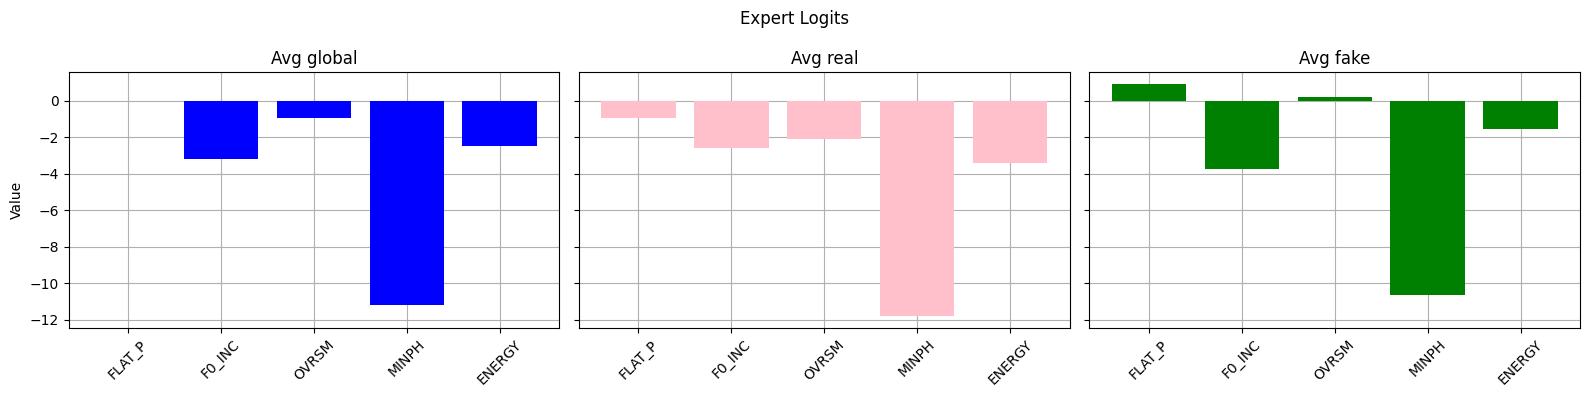

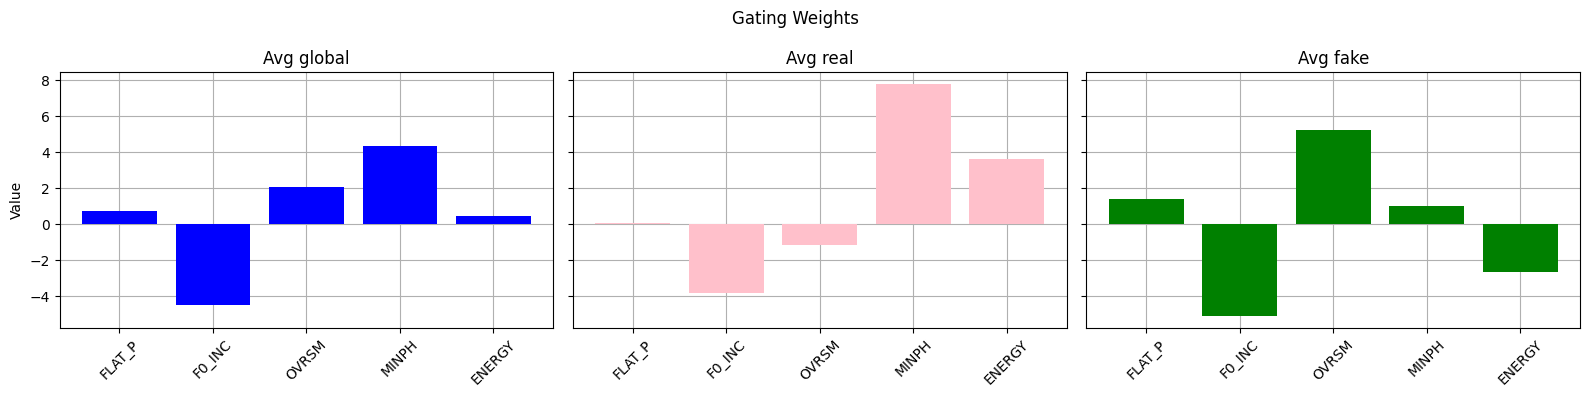

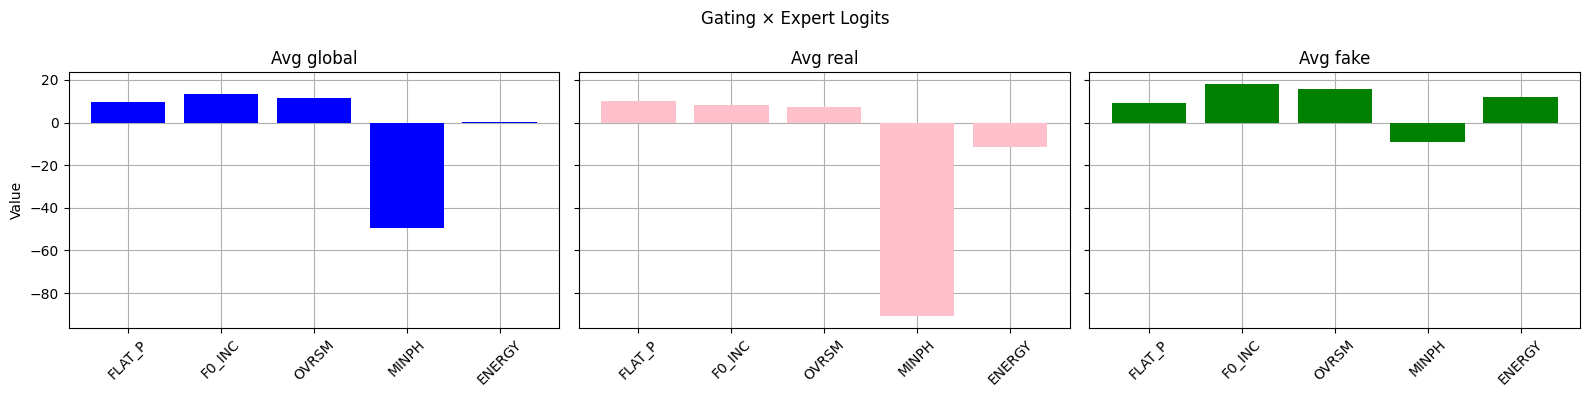

-----------------------------------
A02

Individual Experts' Performance:
AUC: 31.26%, EER: 63.02%
AUC: 17.31%, EER: 73.75%
AUC: 66.08%, EER: 39.43%
AUC: 72.41%, EER: 34.75%
AUC: 71.92%, EER: 32.20%

MoE Performance:
AUC: 77.81%, EER: 27.31%
Loaded 1926 samples
Real mean score: -76.7023
Fake mean score: 20.9103



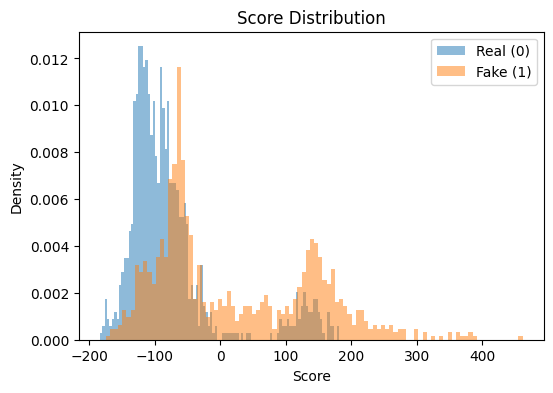

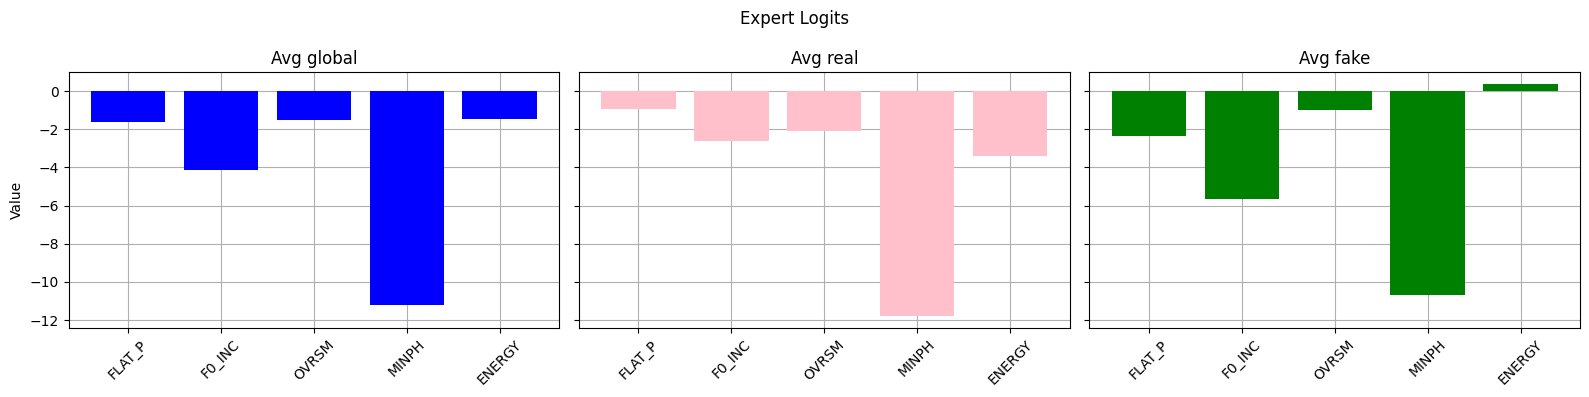

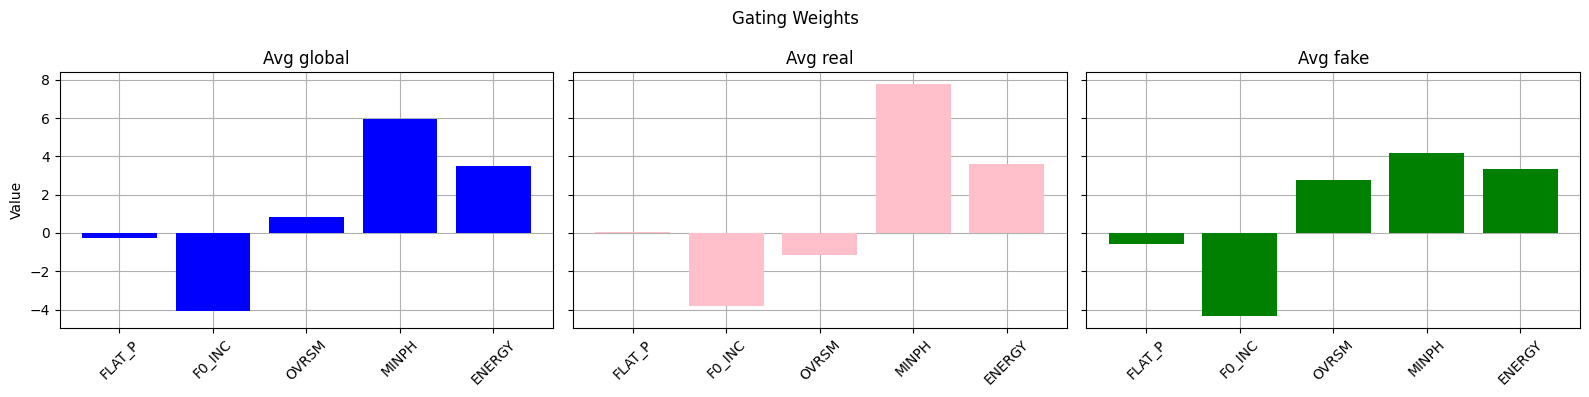

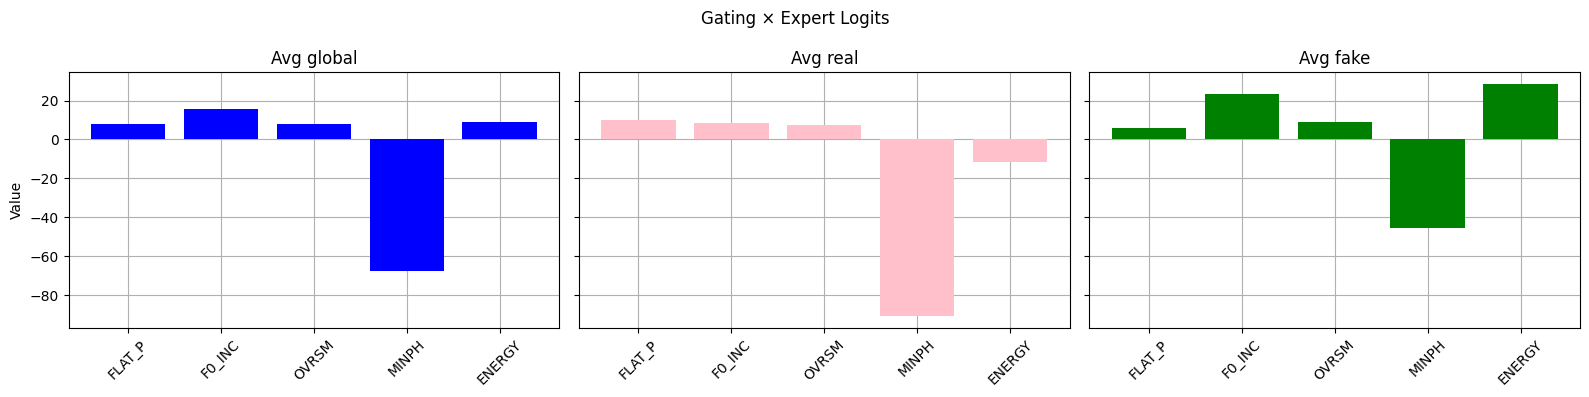

-----------------------------------
A03

Individual Experts' Performance:
AUC: 42.46%, EER: 56.11%
AUC: 22.00%, EER: 69.71%
AUC: 63.72%, EER: 40.60%
AUC: 88.08%, EER: 19.98%
AUC: 96.54%, EER: 9.14%

MoE Performance:
AUC: 86.53%, EER: 19.45%
Loaded 1931 samples
Real mean score: -76.7023
Fake mean score: 19.9633



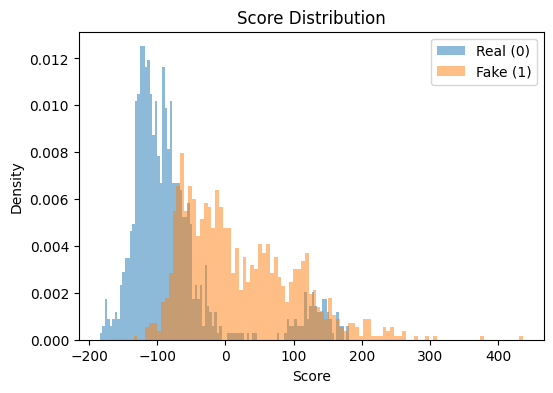

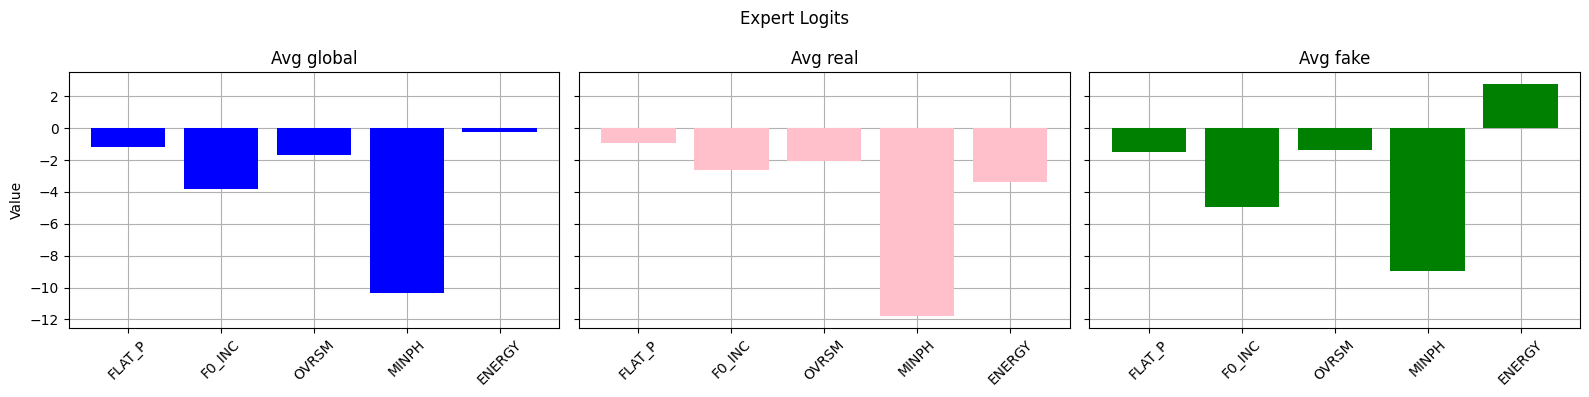

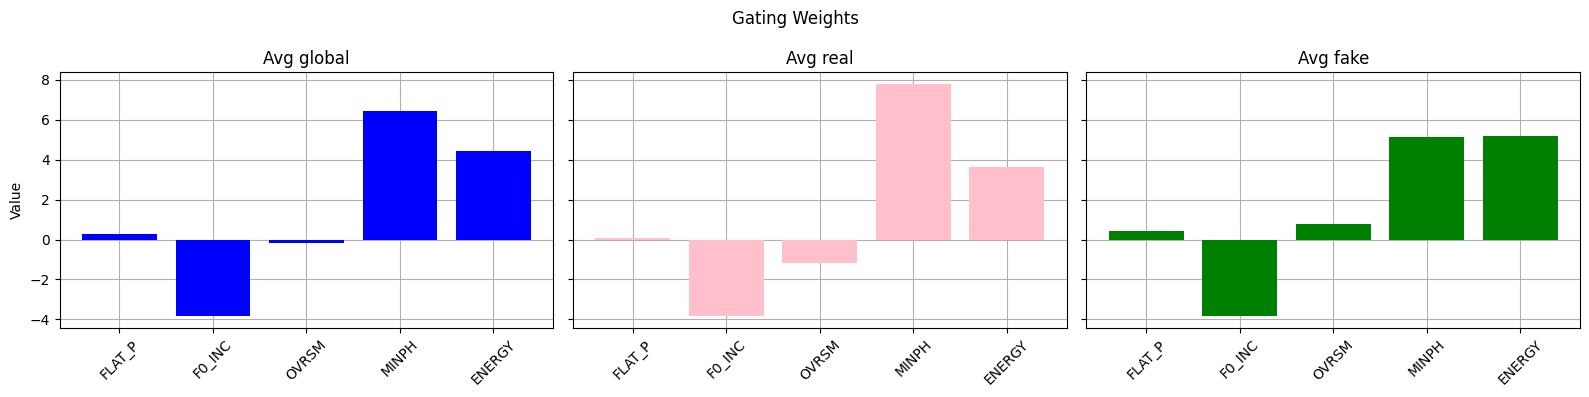

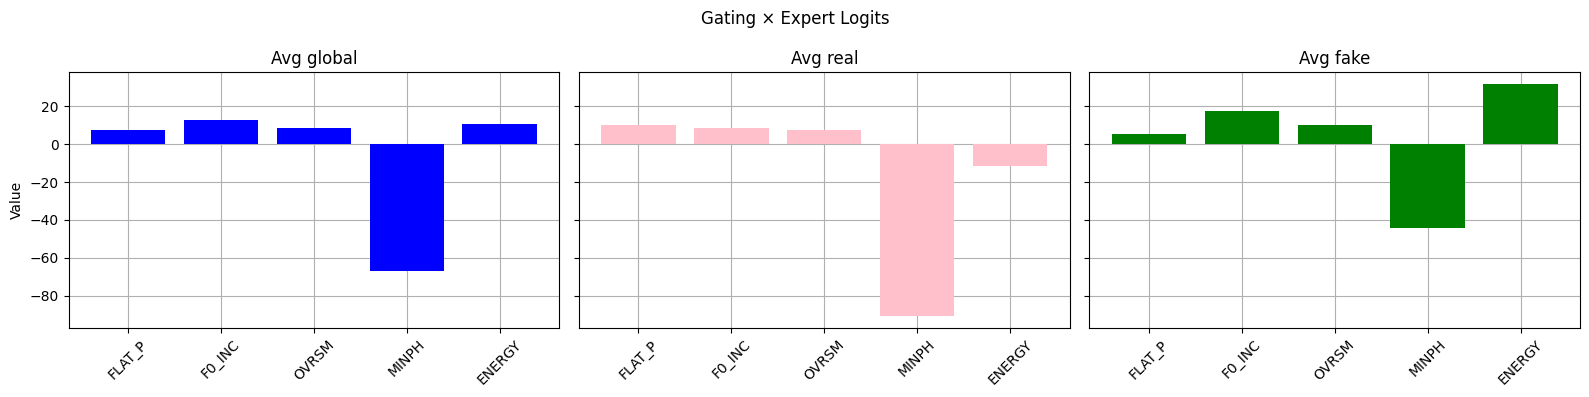

-----------------------------------
A04

Individual Experts' Performance:
AUC: 63.55%, EER: 40.70%
AUC: 72.36%, EER: 34.43%
AUC: 41.74%, EER: 57.60%
AUC: 41.26%, EER: 56.11%
AUC: 89.75%, EER: 19.34%

MoE Performance:
AUC: 86.47%, EER: 19.55%
Loaded 1880 samples
Real mean score: -76.7023
Fake mean score: 65.6806



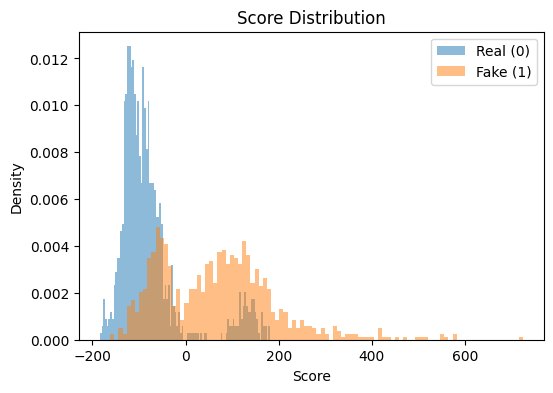

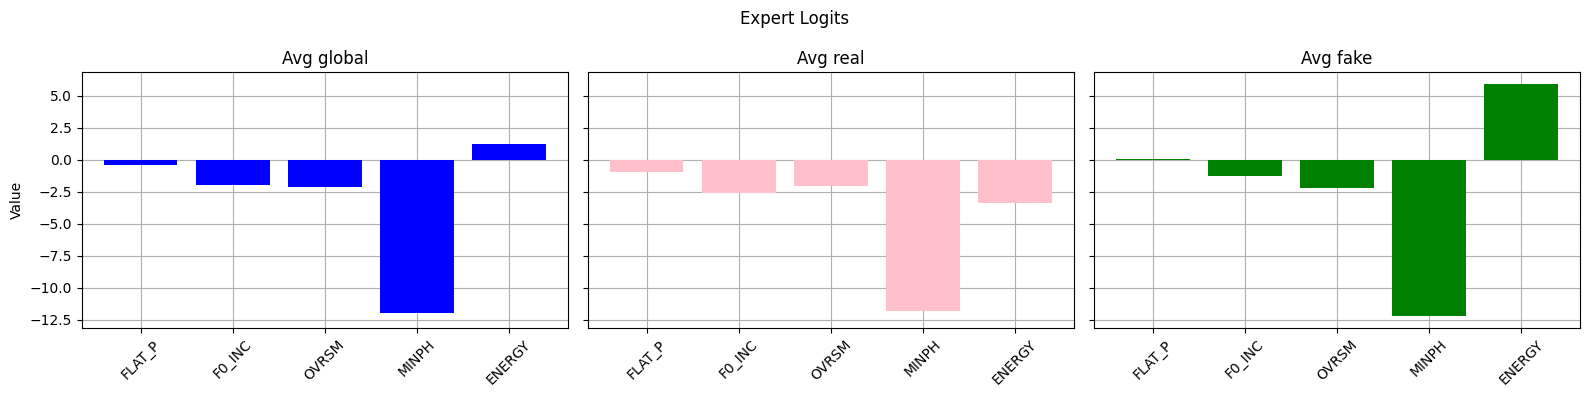

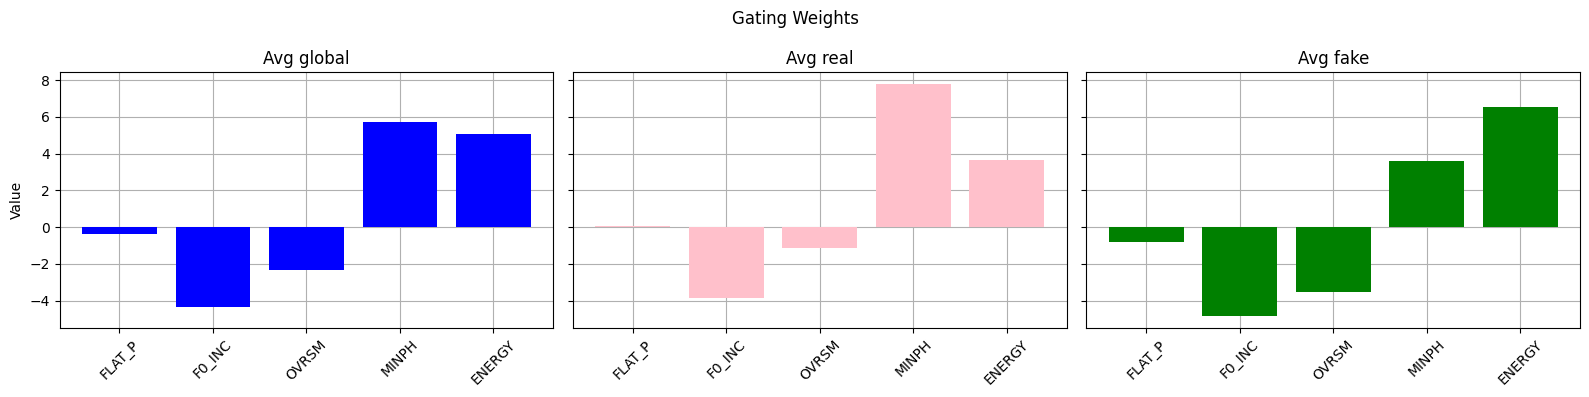

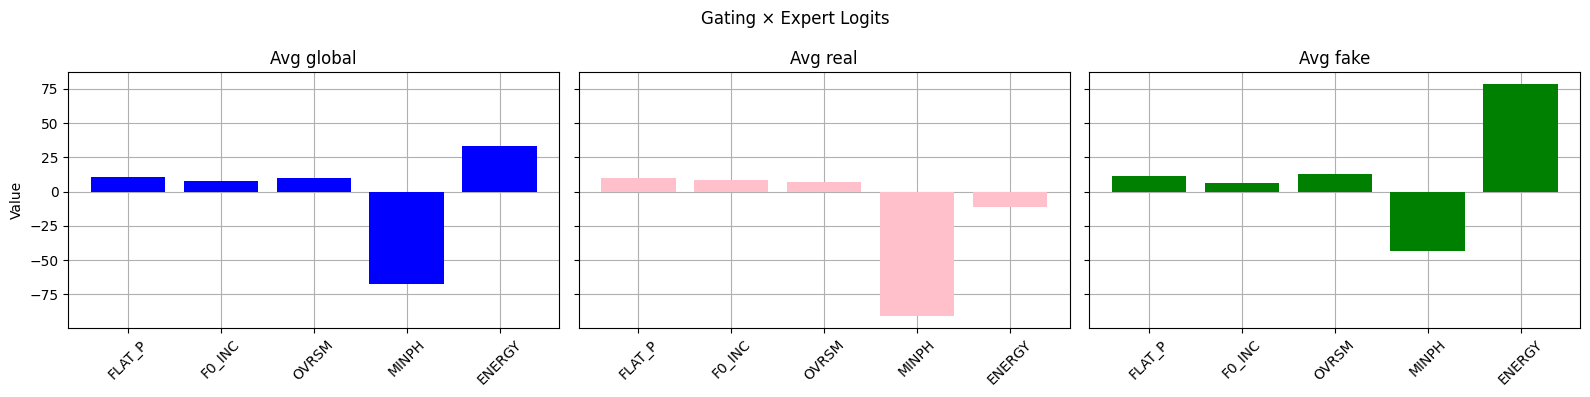

-----------------------------------
A07

Individual Experts' Performance:
AUC: 31.75%, EER: 63.55%
AUC: 13.62%, EER: 76.41%
AUC: 38.91%, EER: 58.77%
AUC: 83.97%, EER: 24.02%
AUC: 63.86%, EER: 38.79%

MoE Performance:
AUC: 66.00%, EER: 36.66%
Loaded 1940 samples
Real mean score: -76.7024
Fake mean score: -59.1923



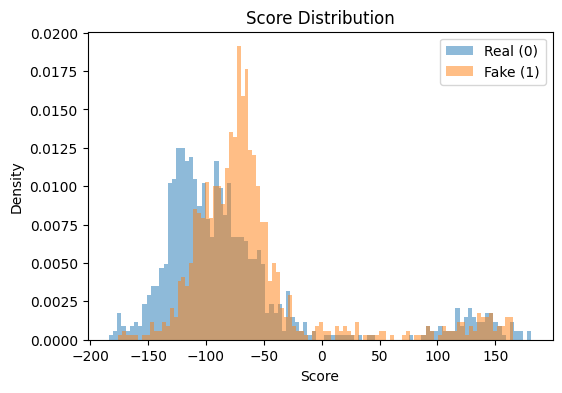

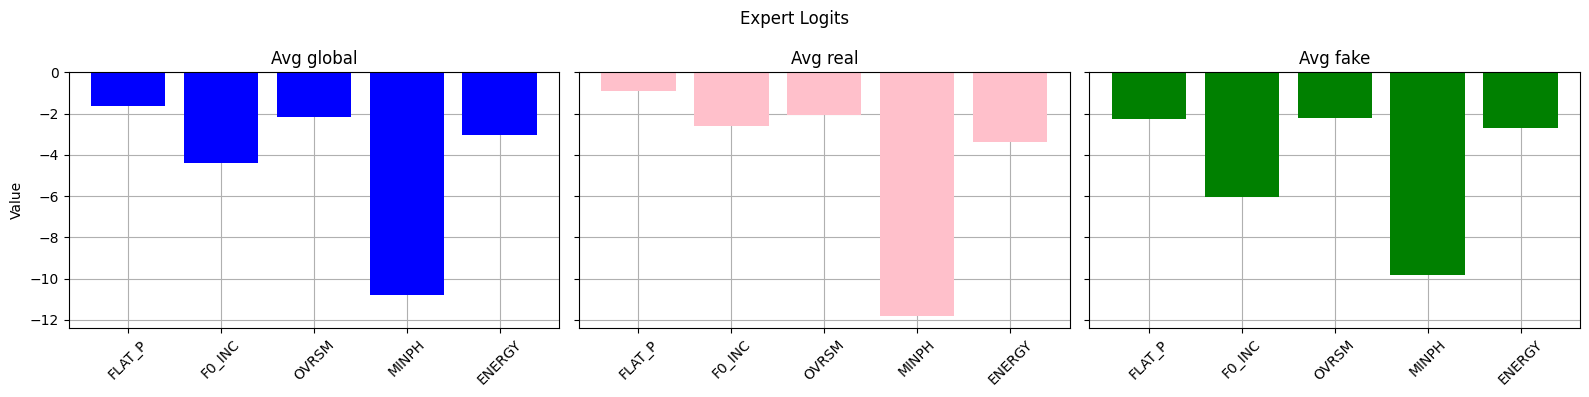

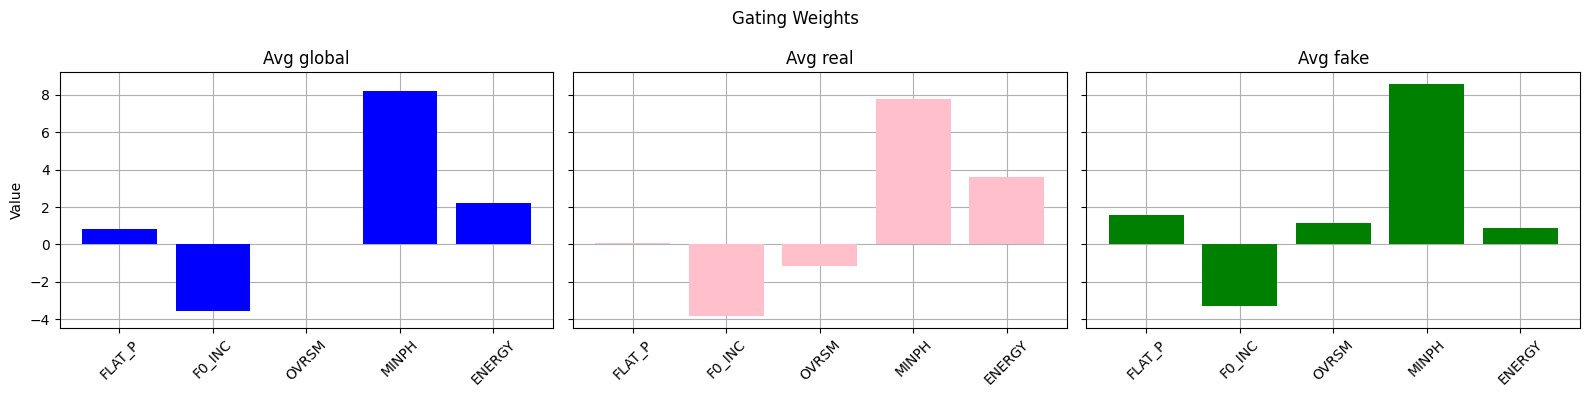

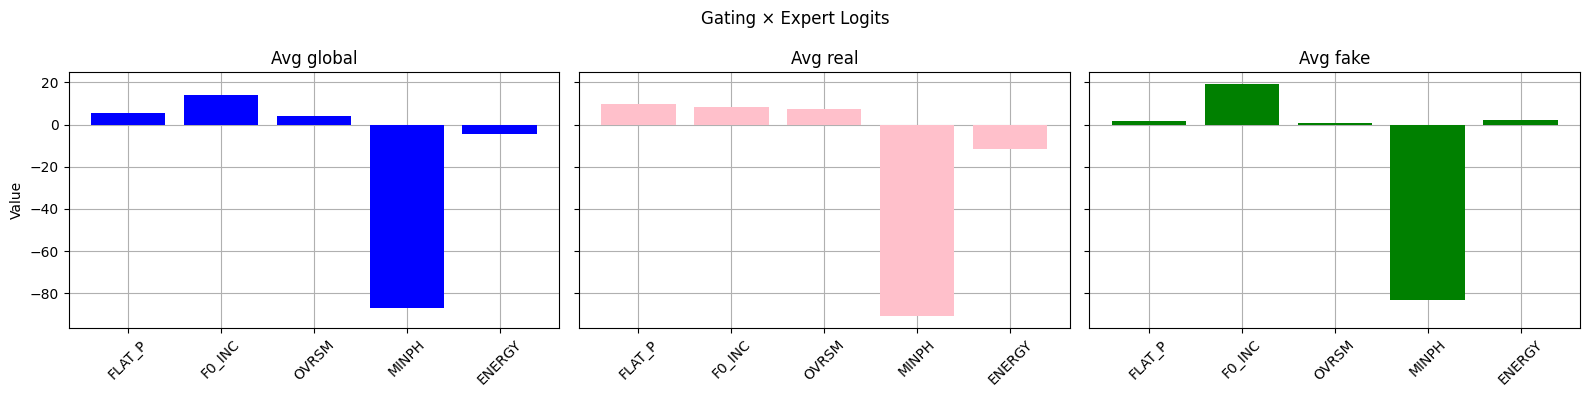

-----------------------------------
A08

Individual Experts' Performance:
AUC: 63.52%, EER: 39.64%
AUC: 26.31%, EER: 67.91%
AUC: 54.58%, EER: 48.78%
AUC: 97.17%, EER: 8.82%
AUC: 96.96%, EER: 8.40%

MoE Performance:
AUC: 89.39%, EER: 13.82%
Loaded 1933 samples
Real mean score: -76.7023
Fake mean score: 26.5794



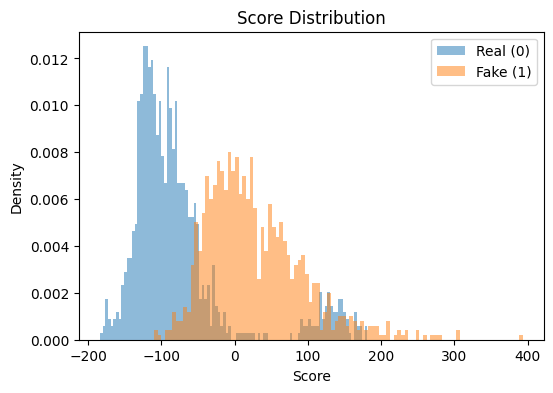

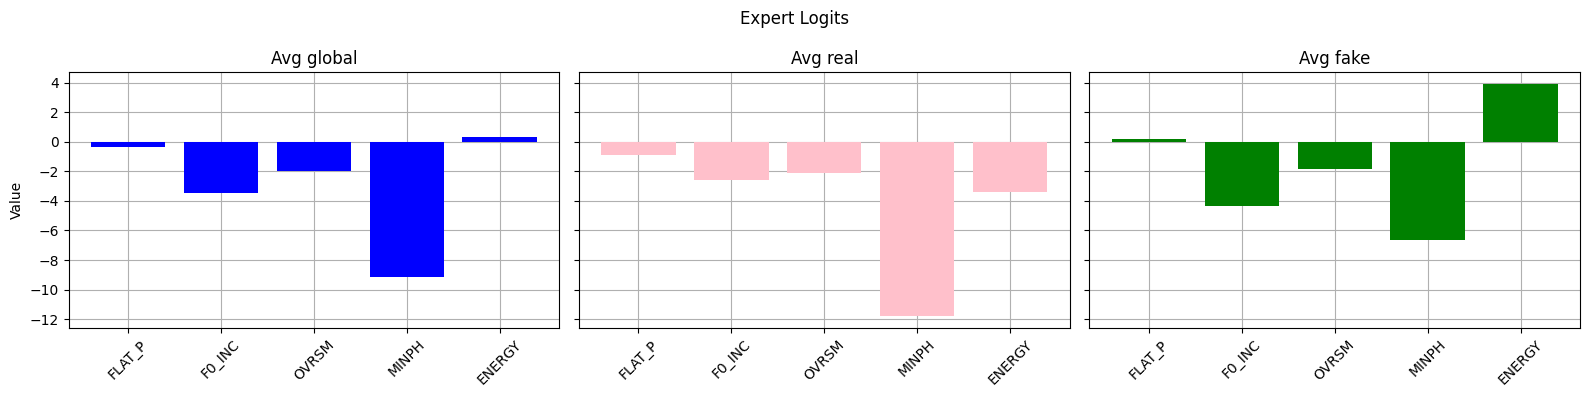

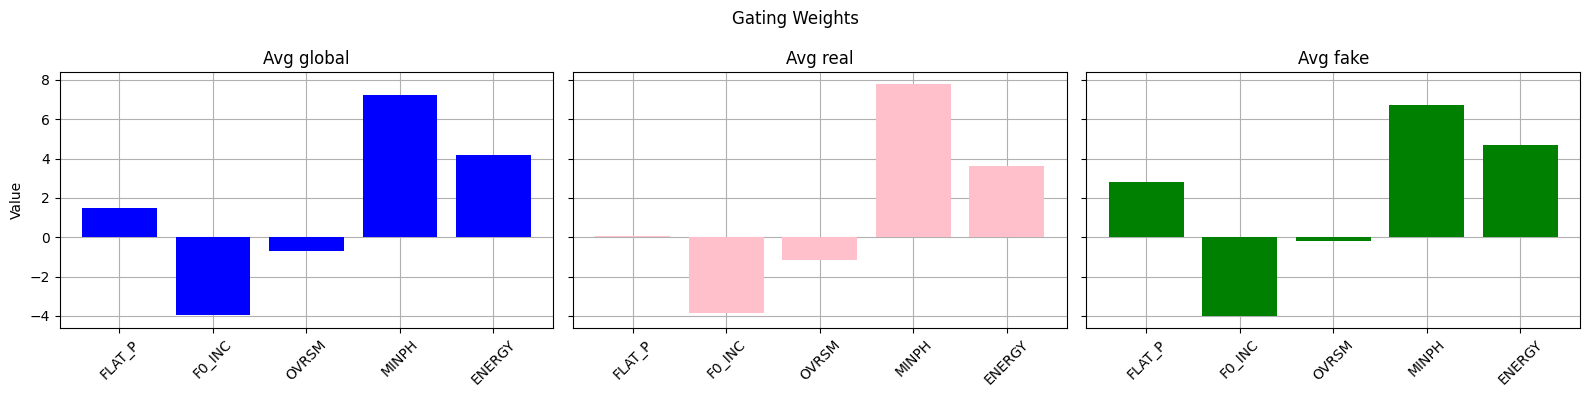

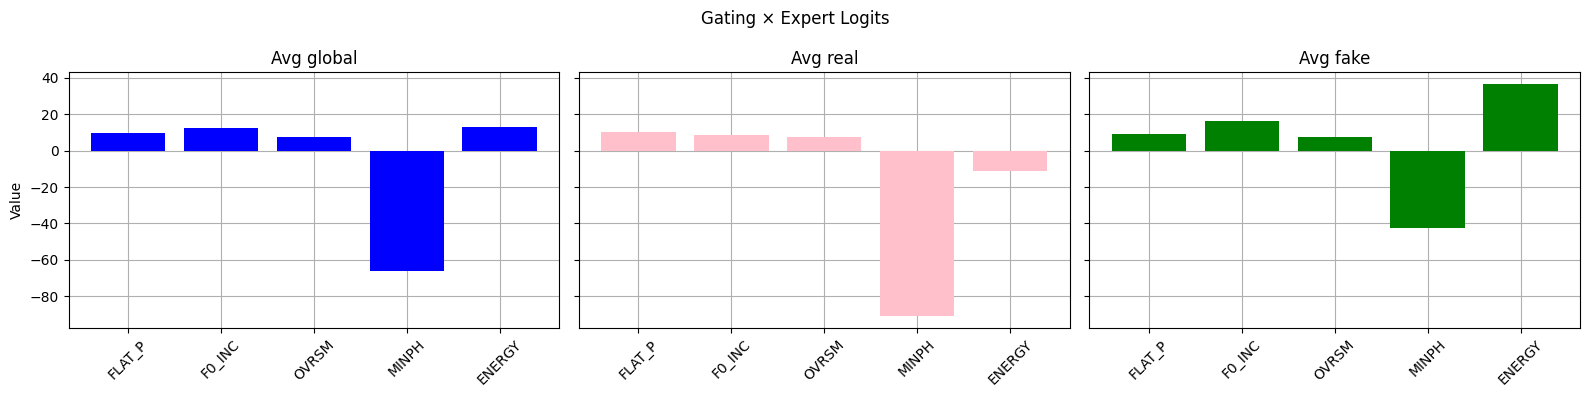

-----------------------------------
A09

Individual Experts' Performance:
AUC: 22.77%, EER: 70.46%
AUC: 15.13%, EER: 75.77%
AUC: 74.59%, EER: 33.90%
AUC: 98.97%, EER: 4.68%
AUC: 97.23%, EER: 8.61%

MoE Performance:
AUC: 94.13%, EER: 10.63%
Loaded 1939 samples
Real mean score: -76.7024
Fake mean score: 187.5790



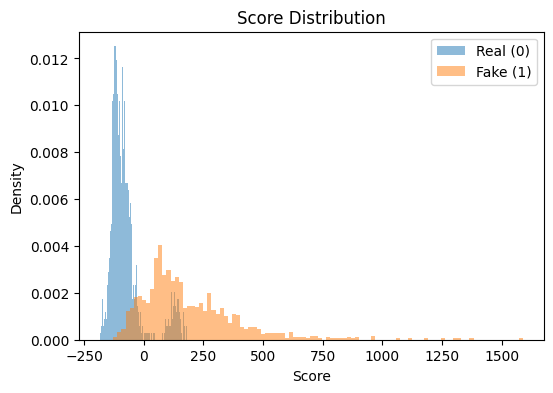

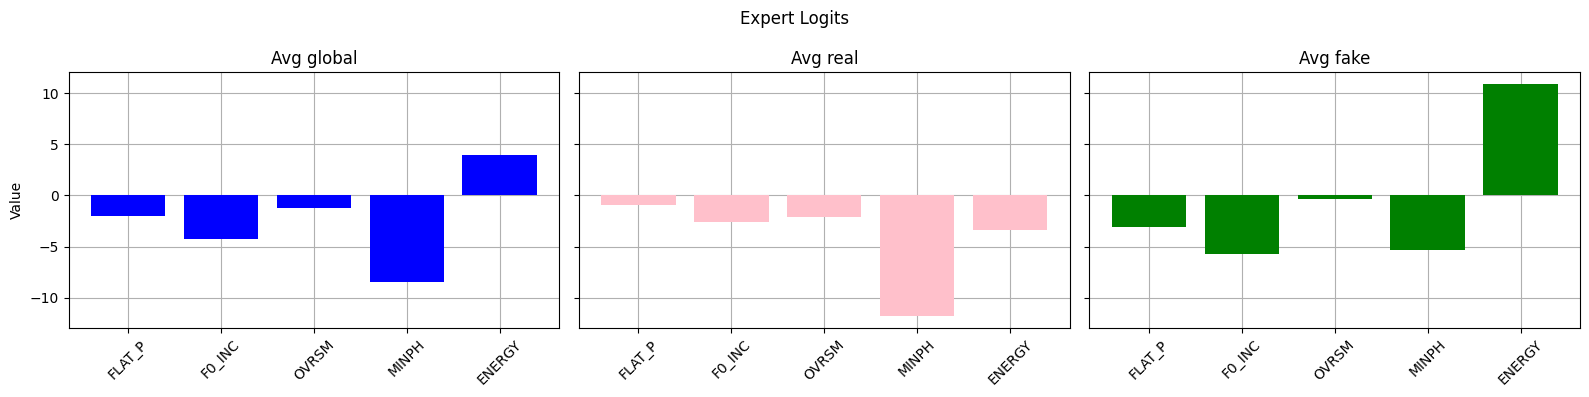

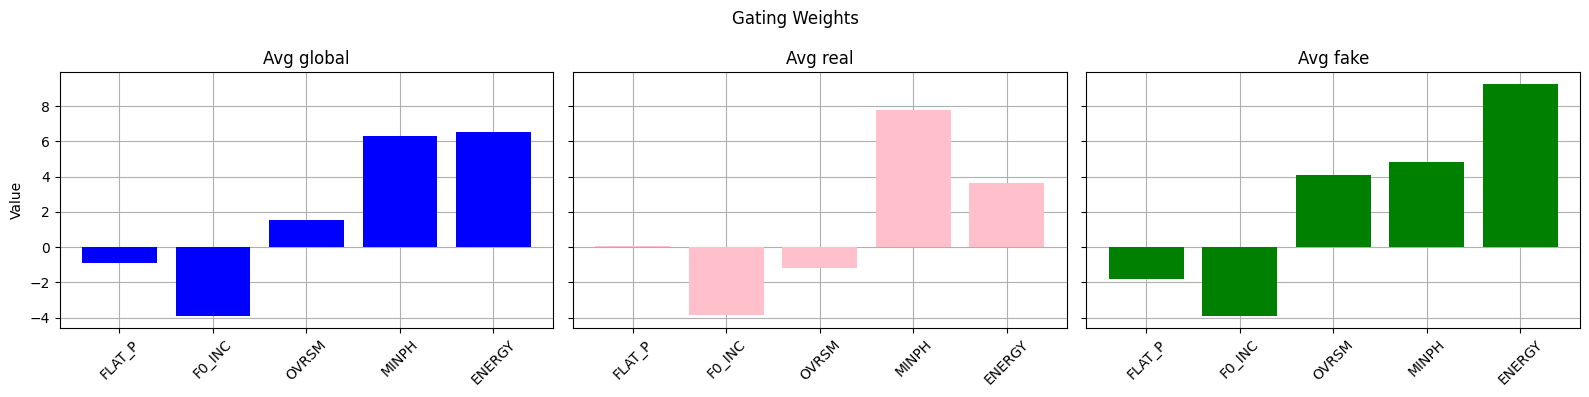

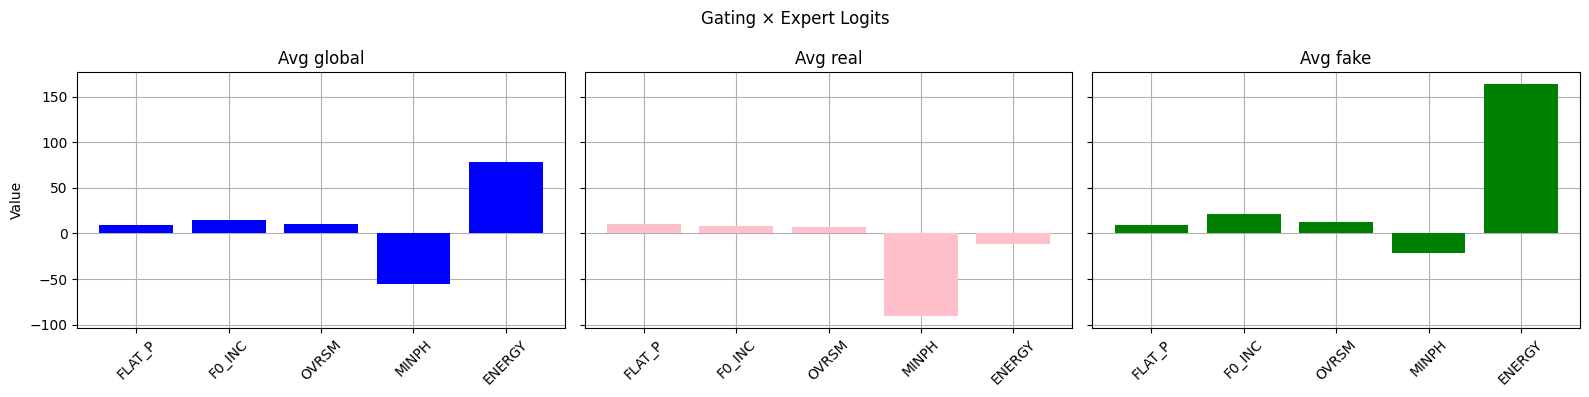

-----------------------------------
A10

Individual Experts' Performance:
AUC: 50.32%, EER: 48.99%
AUC: 38.14%, EER: 58.24%
AUC: 41.40%, EER: 57.60%
AUC: 68.30%, EER: 36.03%
AUC: 58.14%, EER: 43.89%

MoE Performance:
AUC: 50.77%, EER: 50.05%
Loaded 1898 samples
Real mean score: -76.7025
Fake mean score: -75.1778



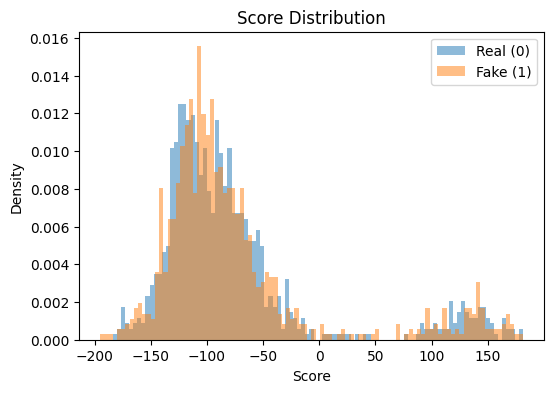

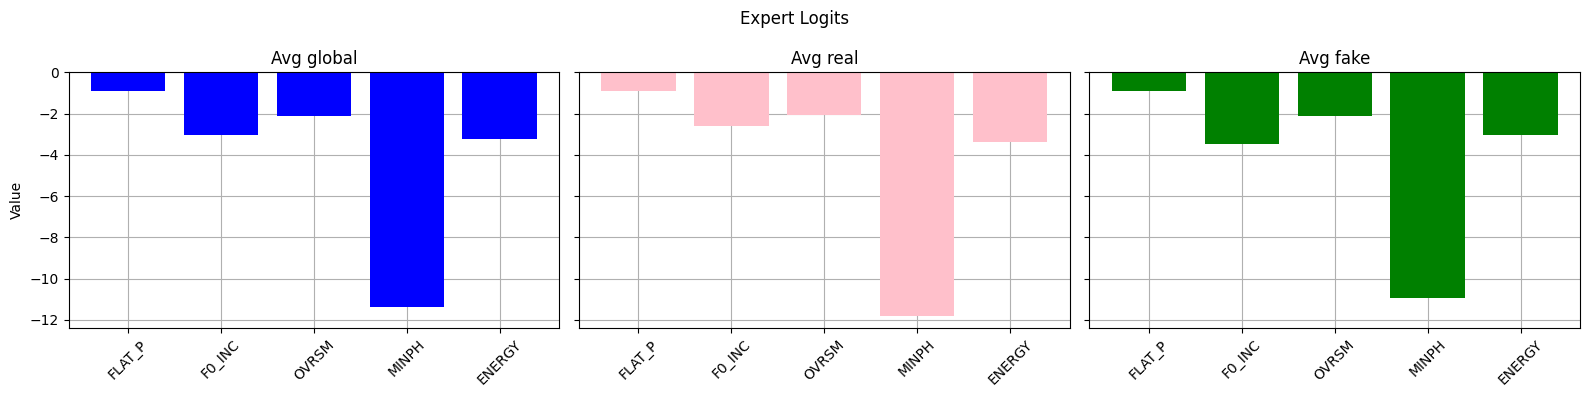

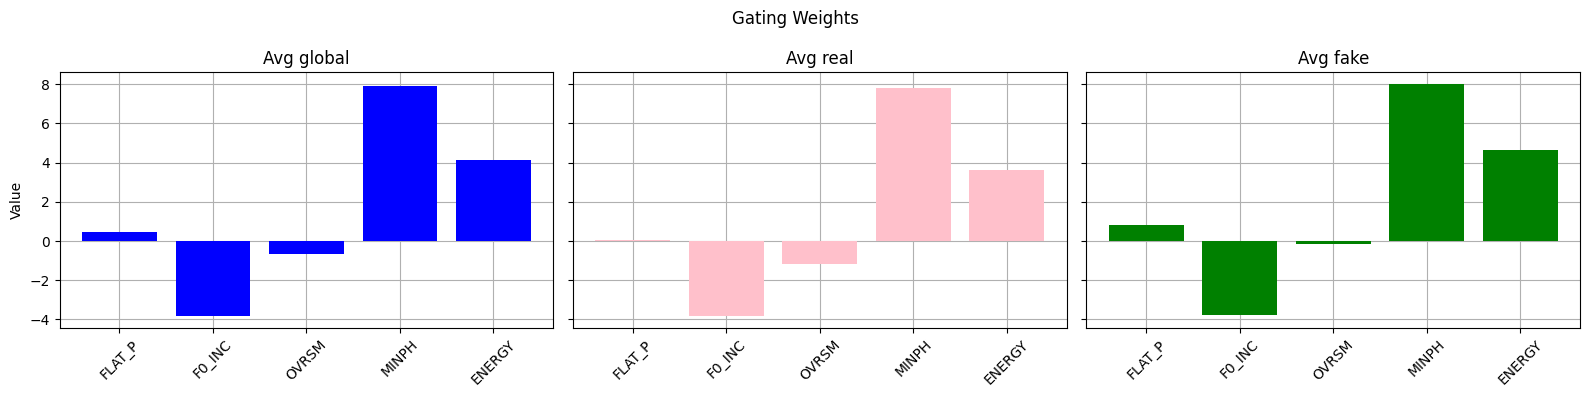

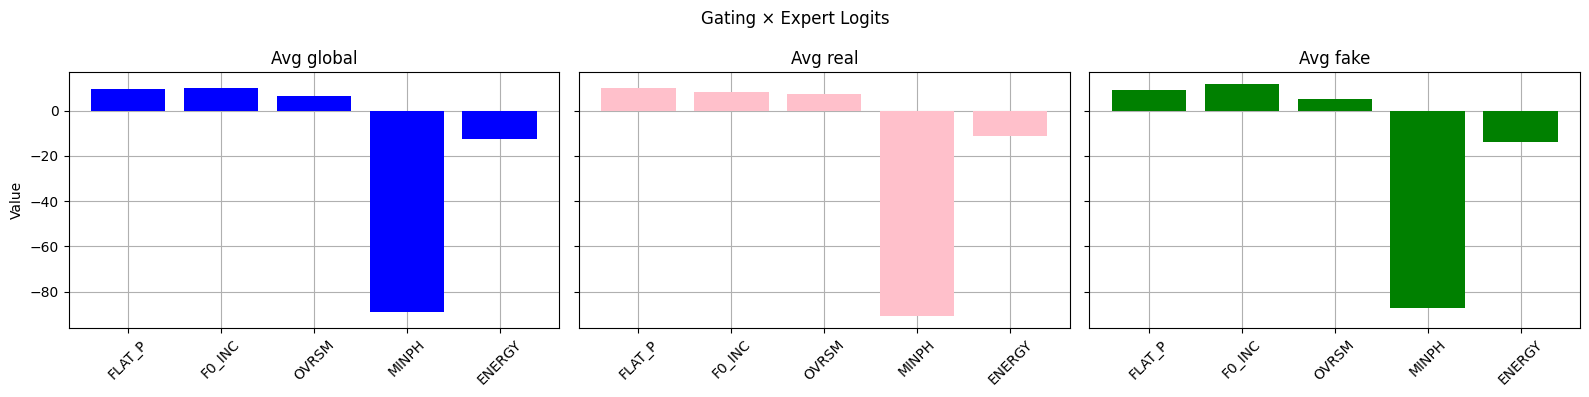

-----------------------------------
A11

Individual Experts' Performance:
AUC: 46.13%, EER: 52.39%
AUC: 35.13%, EER: 59.19%
AUC: 45.27%, EER: 56.11%
AUC: 78.28%, EER: 29.33%
AUC: 82.28%, EER: 25.19%

MoE Performance:
AUC: 77.05%, EER: 28.06%
Loaded 1902 samples
Real mean score: -76.7023
Fake mean score: 3.2961



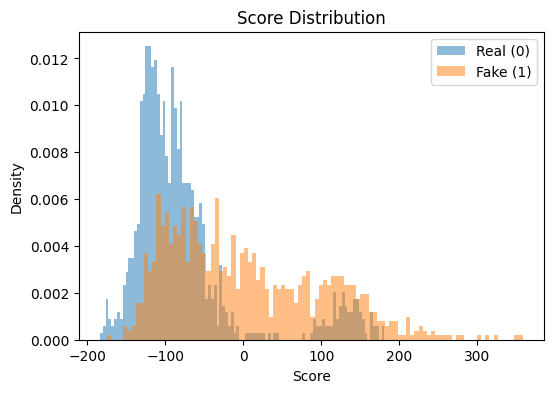

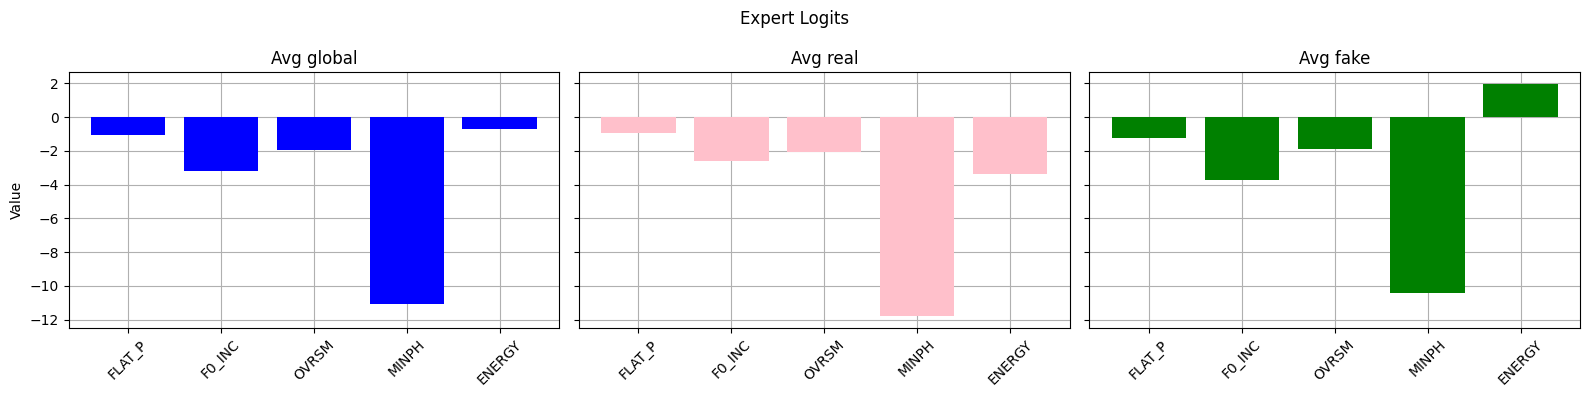

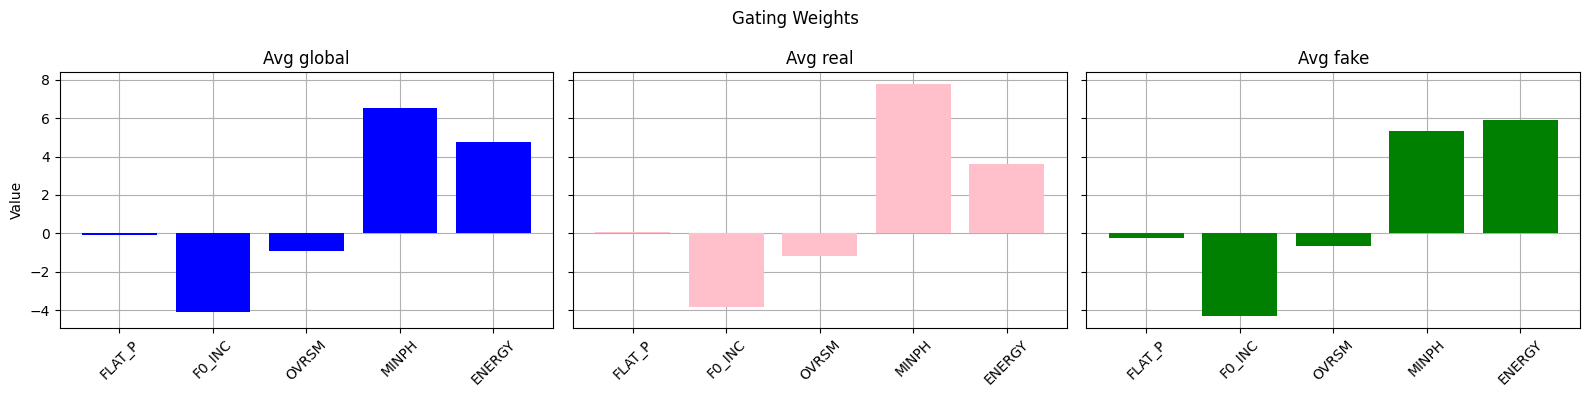

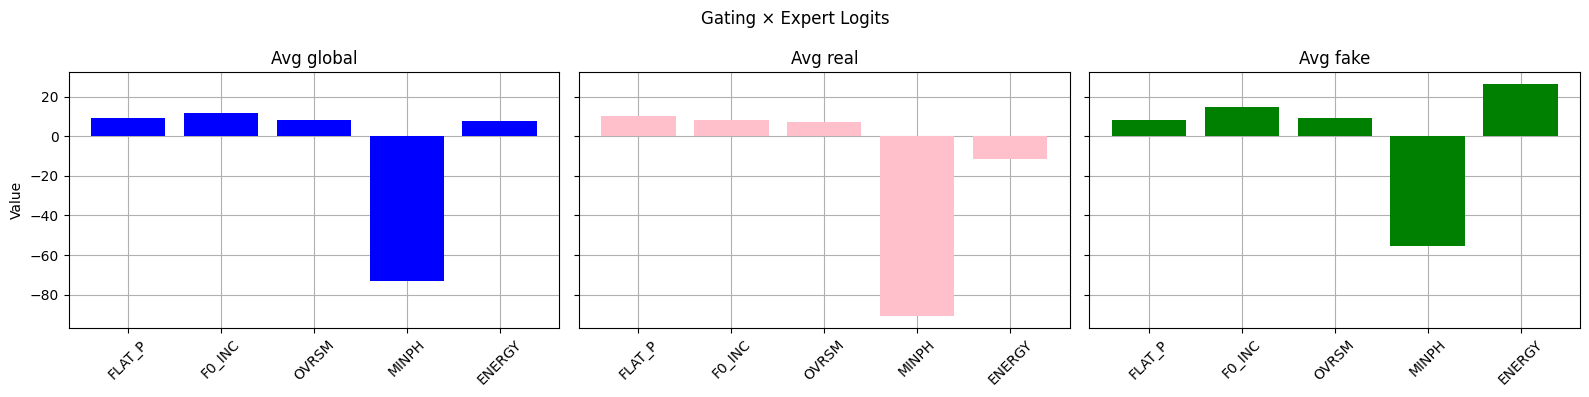

-----------------------------------
A12

Individual Experts' Performance:
AUC: 52.39%, EER: 48.14%
AUC: 39.70%, EER: 56.64%
AUC: 39.32%, EER: 58.45%
AUC: 59.22%, EER: 43.78%
AUC: 86.44%, EER: 18.92%

MoE Performance:
AUC: 82.38%, EER: 22.32%
Loaded 1876 samples
Real mean score: -76.7023
Fake mean score: 73.5341



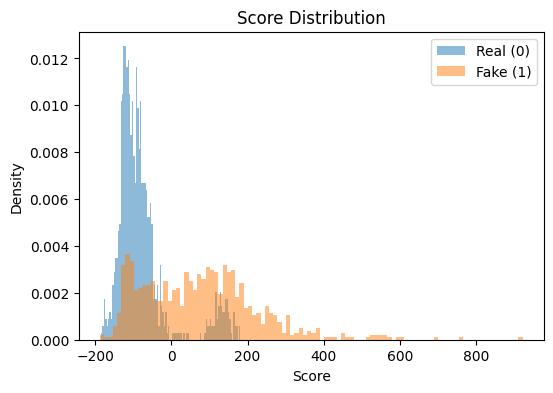

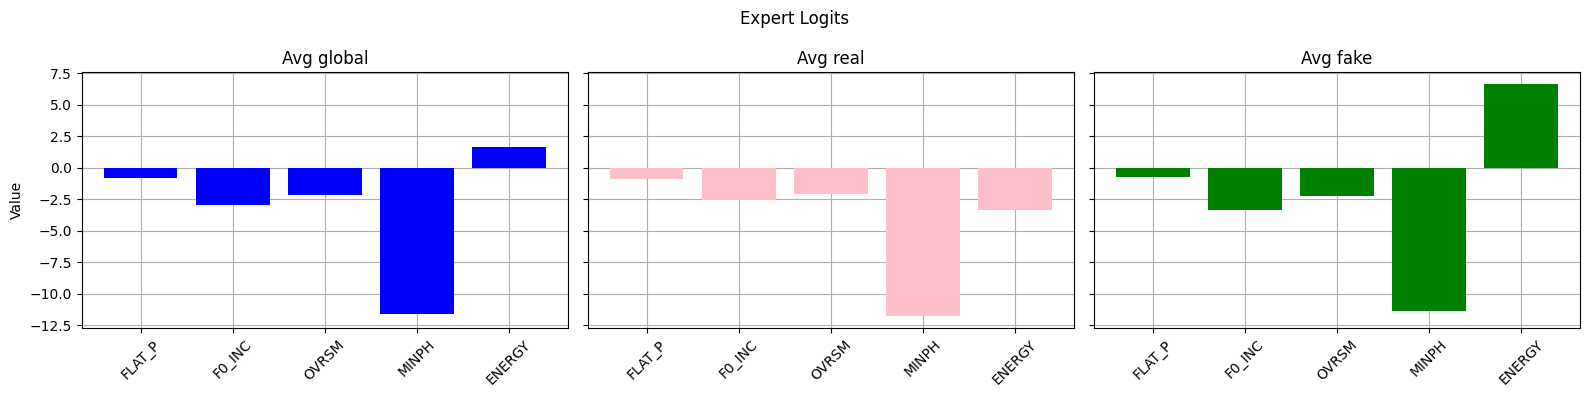

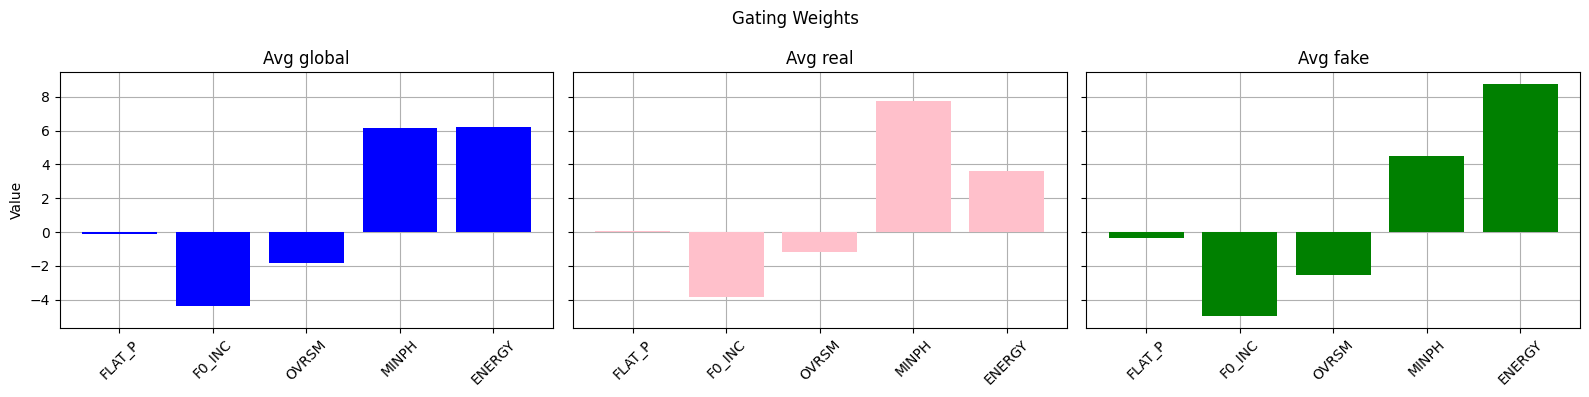

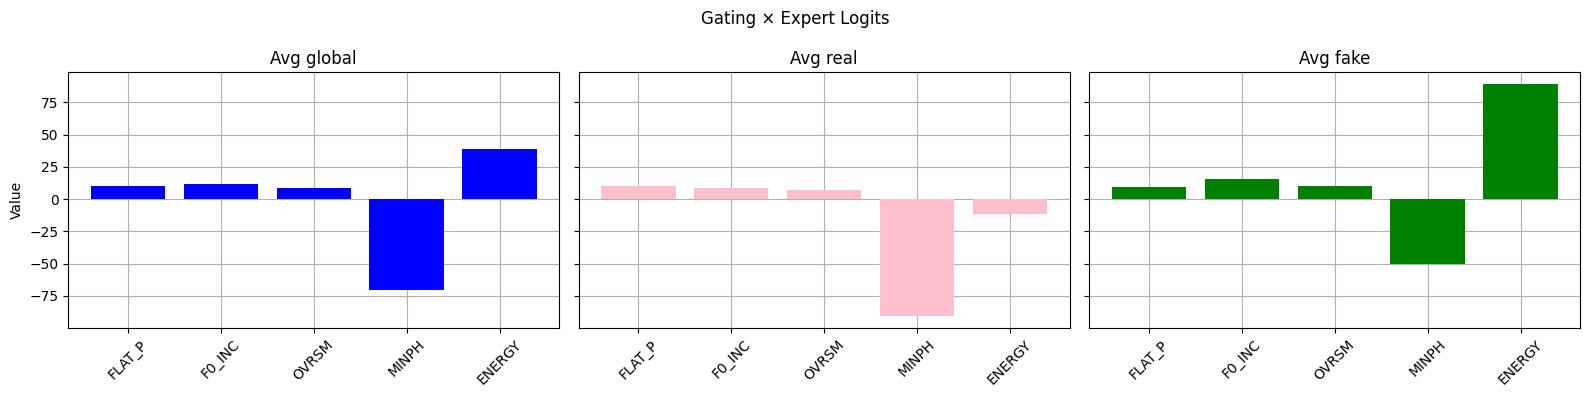

-----------------------------------


In [15]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07',  'A08', 'A09', 'A10', 'A11', 'A12']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/{g}"
    model_name = "frozen_5_exp_new_w_unbound"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True, plot=True)
    print("-----------------------------------")